<a href="https://colab.research.google.com/github/haniyathul/TESIS-HANIY/blob/main/Data_empiris_KKP_572%E2%80%93573_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel("Data Periode September - November.xlsx")

df.head()

,Longitude,Latitude,periode,id_wpp_tangkap,so,thetao,zos,uo,vo,chl,o2,mlotst,nppv,Kecepatan,cpue
0,92.25,2.75,Sep23_Nov23,572,32.456251,29.179822,0.409609,0.007200,-0.005725,0.116589,200.629854,18.672807,4.189994,0.009199,32.812079
1,92.25,3.25,Sep23_Nov23,572,32.112098,29.233677,0.416061,0.048852,-0.034232,0.109667,200.716746,16.415003,3.758218,0.059652,39.330566
2,92.25,3.75,Sep23_Nov23,572,31.879946,29.342594,0.418971,0.068079,-0.070260,0.106332,200.683519,16.389571,3.515052,0.097833,18.095839
3,92.75,1.25,Sep23_Nov23,572,32.817345,29.142013,0.384966,-0.286021,-0.012049,0.139036,201.433196,16.830394,5.487492,0.286274,2.806741
4,92.75,2.75,Sep23_Nov23,572,32.429830,29.242229,0.407123,0.036594,-0.038515,0.115609,200.629267,18.580969,4.174876,0.053128,13.232582


In [73]:
print("Ukuran data:", df.shape)

print("\nNama kolom:")
print(df.columns.tolist())

print("\nJumlah missing value:")
print(df.isna().sum())

Ukuran data: (401, 15)

Nama kolom:
['Longitude', 'Latitude', 'periode', 'id_wpp_tangkap', 'so', 'thetao', 'zos', 'uo', 'vo', 'chl', 'o2', 'mlotst', 'nppv', 'Kecepatan', 'cpue']

Jumlah missing value:
Longitude         0
Latitude          0
periode           0
id_wpp_tangkap    0
so                0
thetao            0
zos               0
uo                0
vo                0
chl               0
o2                0
mlotst            0
nppv              0
Kecepatan         0
cpue              0
dtype: int64


count    401.000000
mean       9.755032
std       17.912148
min        0.000117
25%        0.538636
50%        2.175787
75%        8.475327
max       98.235387
Name: cpue, dtype: float64


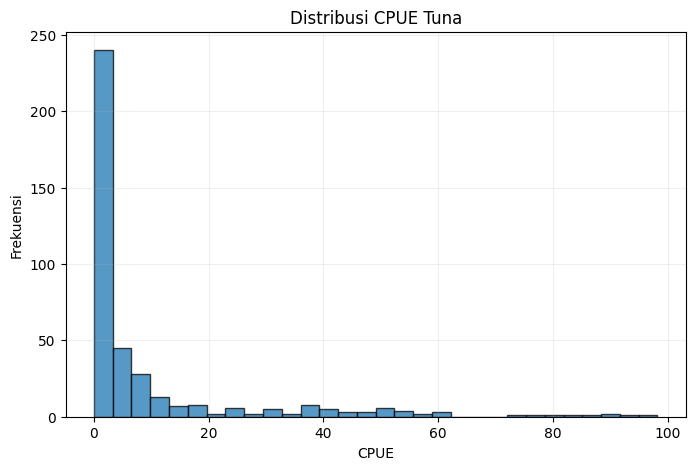

In [74]:
y = df["cpue"]

print(y.describe())

plt.figure(figsize=(8, 5))

plt.hist(y, bins=30, edgecolor="black", alpha=0.75)

plt.title("Distribusi CPUE Tuna")
plt.xlabel("CPUE")
plt.ylabel("Frekuensi")
plt.grid(alpha=0.2)

plt.show()

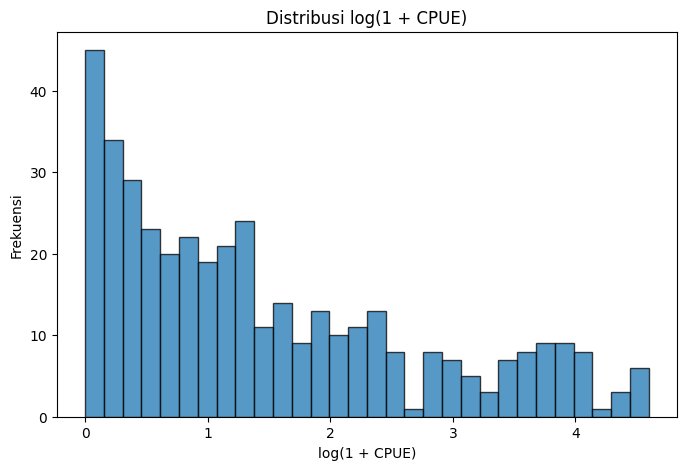

In [75]:
plt.figure(figsize=(8, 5))

plt.hist(np.log1p(df["cpue"]),
         bins=30,
         edgecolor="black",
         alpha=0.75)

plt.title("Distribusi log(1 + CPUE)")
plt.xlabel("log(1 + CPUE)")
plt.ylabel("Frekuensi")

plt.show()

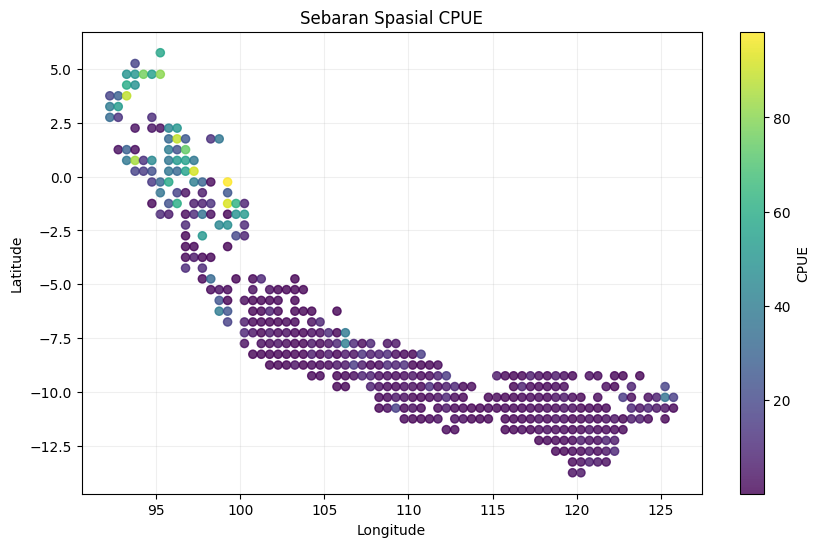

In [76]:
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["cpue"],
    cmap="viridis",
    s=35,
    alpha=0.8
)

plt.colorbar(scatter, label="CPUE")

plt.title("Sebaran Spasial CPUE")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.2)

plt.show()

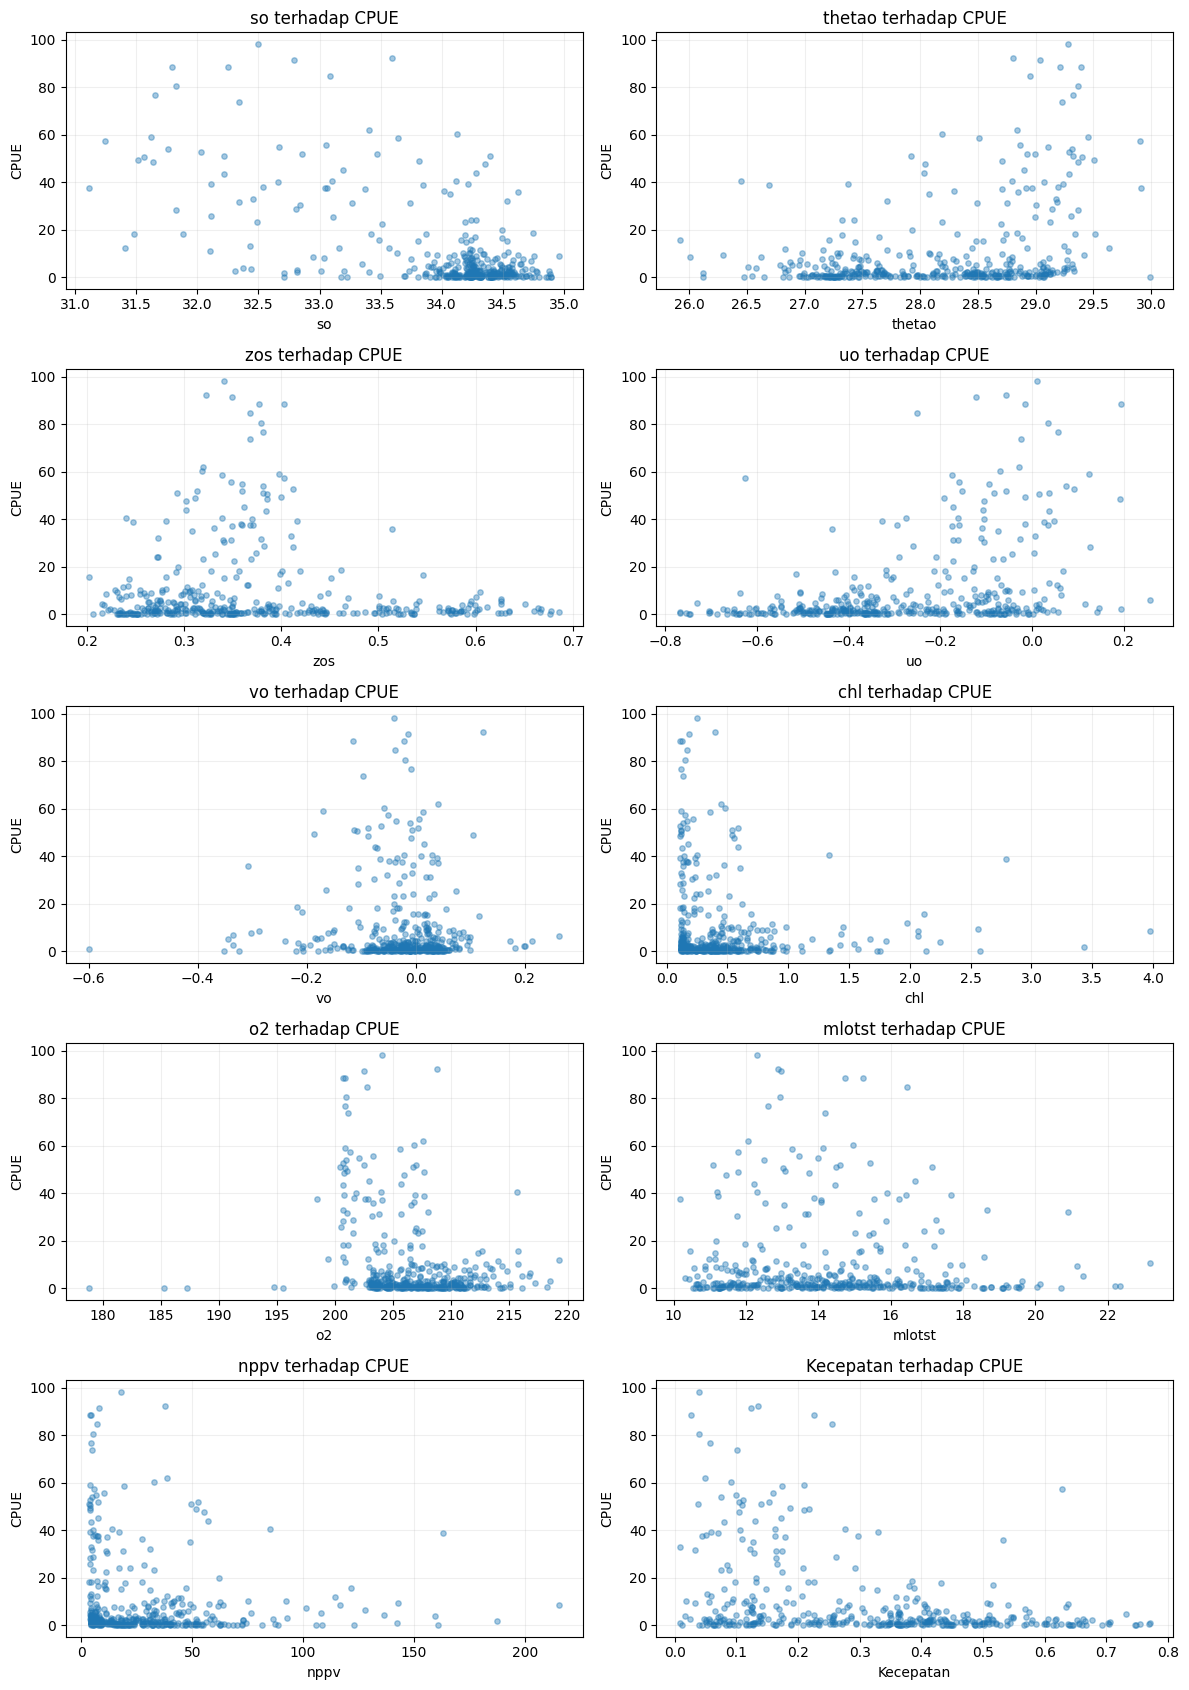

In [77]:
X_cols = [
    "so", "thetao", "zos",
    "uo", "vo", "chl",
    "o2", "mlotst", "nppv",
    "Kecepatan"
]

fig, axes = plt.subplots(5, 2, figsize=(12, 17))

axes = axes.flatten()

for i, col in enumerate(X_cols):

    axes[i].scatter(
        df[col],
        df["cpue"],
        alpha=0.4,
        s=15
    )

    axes[i].set_title(f"{col} terhadap CPUE")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("CPUE")
    axes[i].grid(alpha=0.2)

plt.tight_layout()
plt.show()

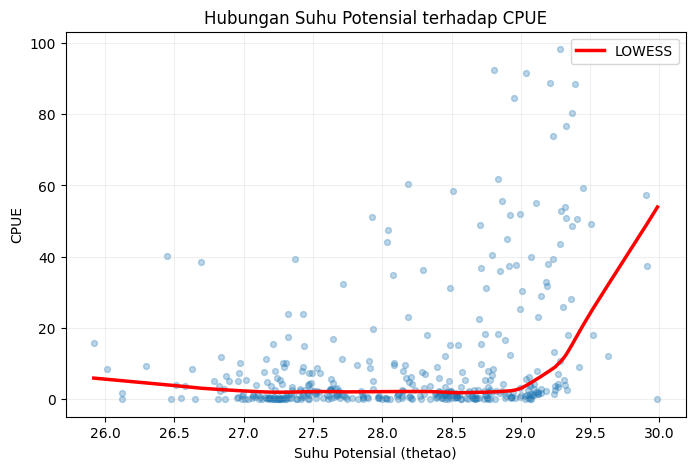

In [78]:
import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess

x = df["thetao"]
y = df["cpue"]

smooth = lowess(
    y, x,
    frac=0.35,
    it=3,
    return_sorted=True
)

plt.figure(figsize=(8, 5))

plt.scatter(x, y, alpha=0.3, s=18)

plt.plot(
    smooth[:, 0],
    smooth[:, 1],
    color="red",
    linewidth=2.5,
    label="LOWESS"
)

plt.xlabel("Suhu Potensial (thetao)")
plt.ylabel("CPUE")
plt.title("Hubungan Suhu Potensial terhadap CPUE")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [79]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

data = df[["thetao", "cpue"]].dropna().copy()

# Centering untuk mengurangi korelasi X dan X²
data["thetao_c"] = data["thetao"] - data["thetao"].mean()
data["thetao_c2"] = data["thetao_c"] ** 2

# Model linier
model_linier = smf.ols(
    "cpue ~ thetao_c",
    data=data
).fit()

# Model kuadratik
model_kuadratik = smf.ols(
    "cpue ~ thetao_c + thetao_c2",
    data=data
).fit()

# Perbandingan model
hasil = model_kuadratik.compare_f_test(model_linier)

print("F-statistic :", hasil[0])
print("p-value     :", hasil[1])
print("R² linier   :", model_linier.rsquared)
print("R² kuadratik:", model_kuadratik.rsquared)

F-statistic : 31.54992394566059
p-value     : 3.655860965873523e-08
R² linier   : 0.11708060248110341
R² kuadratik: 0.18192996757002267


In [80]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from patsy import dmatrix

X_cols = [
    "so", "thetao", "zos", "uo", "vo",
    "chl", "o2", "mlotst", "nppv", "Kecepatan"
]

hasil = []

for col in X_cols:
    data = df[[col, "cpue"]].dropna().copy()
    x = data[col].astype(float)
    y = data["cpue"].astype(float)

    # Model linier
    X_lin = sm.add_constant(x)
    model_lin = sm.OLS(y, X_lin).fit()

    # Model spline kubik
    X_spline = dmatrix(
        "bs(x, df=5, degree=3, include_intercept=False)",
        {"x": x},
        return_type="dataframe"
    )
    model_spline = sm.OLS(y, X_spline).fit()

    # Uji F model spline vs linier
    F, p, df_diff = model_spline.compare_f_test(model_lin)

    hasil.append({
        "Peubah": col,
        "R2_Linier": model_lin.rsquared,
        "R2_Spline": model_spline.rsquared,
        "F": F,
        "p_value": p
    })

hasil_df = pd.DataFrame(hasil)

hasil_df["Indikasi"] = np.where(
    hasil_df["p_value"] < 0.05,
    "Ada bukti komponen nonlinier",
    "Belum ada bukti"
)

display(hasil_df.round(4))

,Peubah,R2_Linier,R2_Spline,F,p_value,Indikasi
0,so,0.4021,0.4226,3.5015,0.0080,Ada bukti komponen nonlinier
1,thetao,0.1171,0.2043,10.8253,0.0000,Ada bukti komponen nonlinier
2,zos,0.0073,0.1078,11.1257,0.0000,Ada bukti komponen nonlinier
3,uo,0.1532,0.1724,2.2954,0.0587,Belum ada bukti
4,vo,0.0016,0.0126,1.0984,0.3570,Belum ada bukti
5,chl,0.0115,0.0542,4.4609,0.0015,Ada bukti komponen nonlinier
6,o2,0.0654,0.1350,7.9463,0.0000,Ada bukti komponen nonlinier
7,mlotst,0.0052,0.0178,1.2701,0.2811,Belum ada bukti
8,nppv,0.0145,0.0749,6.4454,0.0000,Ada bukti komponen nonlinier
9,Kecepatan,0.1269,0.1518,2.9023,0.0218,Ada bukti komponen nonlinier


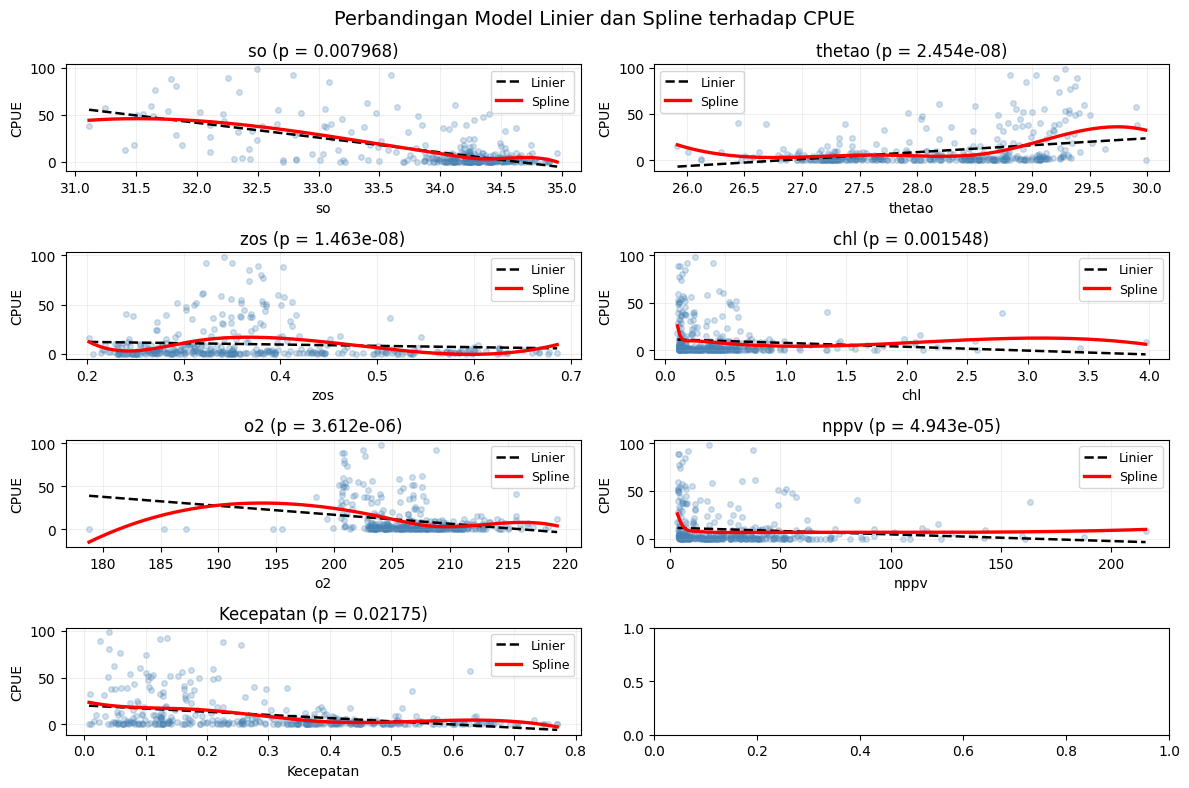

In [81]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from patsy import dmatrix

# Empat peubah utama

variabel = [
    "so", "thetao", "zos", "chl",
    "o2", "nppv", "Kecepatan"
]


fig, axes = plt.subplots(4, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(variabel):

    data = df[[col, "cpue"]].dropna().copy()
    x = data[col].astype(float)
    y = data["cpue"].astype(float)

    # Model linier
    X_lin = sm.add_constant(x)
    model_lin = sm.OLS(y, X_lin).fit()

    # Model spline kubik
    formula_spline = "bs(x, df=5, degree=3, include_intercept=False)"
    X_spline = dmatrix(
        formula_spline,
        {"x": x},
        return_type="dataframe"
    )
    model_spline = sm.OLS(y, X_spline).fit()

    # Uji F
    F, p_value, _ = model_spline.compare_f_test(model_lin)

    # Grid untuk menggambar kurva
    x_grid = np.linspace(x.min(), x.max(), 200)

    X_lin_grid = sm.add_constant(
        pd.Series(x_grid, name=col),
        has_constant="add"
    )
    y_lin = model_lin.predict(X_lin_grid)

    # Gunakan basis spline yang sama dengan data latih
    from patsy import build_design_matrices
    X_spline_grid = build_design_matrices(
        [X_spline.design_info],
        {"x": x_grid}
    )[0]
    y_spline = model_spline.predict(X_spline_grid)

    ax = axes[i]

    ax.scatter(x, y, color="steelblue", alpha=0.25, s=16)

    ax.plot(
        x_grid, y_lin,
        color="black", linestyle="--",
        linewidth=1.8, label="Linier"
    )

    ax.plot(
        x_grid, y_spline,
        color="red",
        linewidth=2.4, label="Spline"
    )

    ax.set_title(f"{col} (p = {p_value:.4g})", fontsize=12)
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel("CPUE", fontsize=10)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)

plt.suptitle(
    "Perbandingan Model Linier dan Spline terhadap CPUE",
    fontsize=14
)

plt.tight_layout()
plt.show()


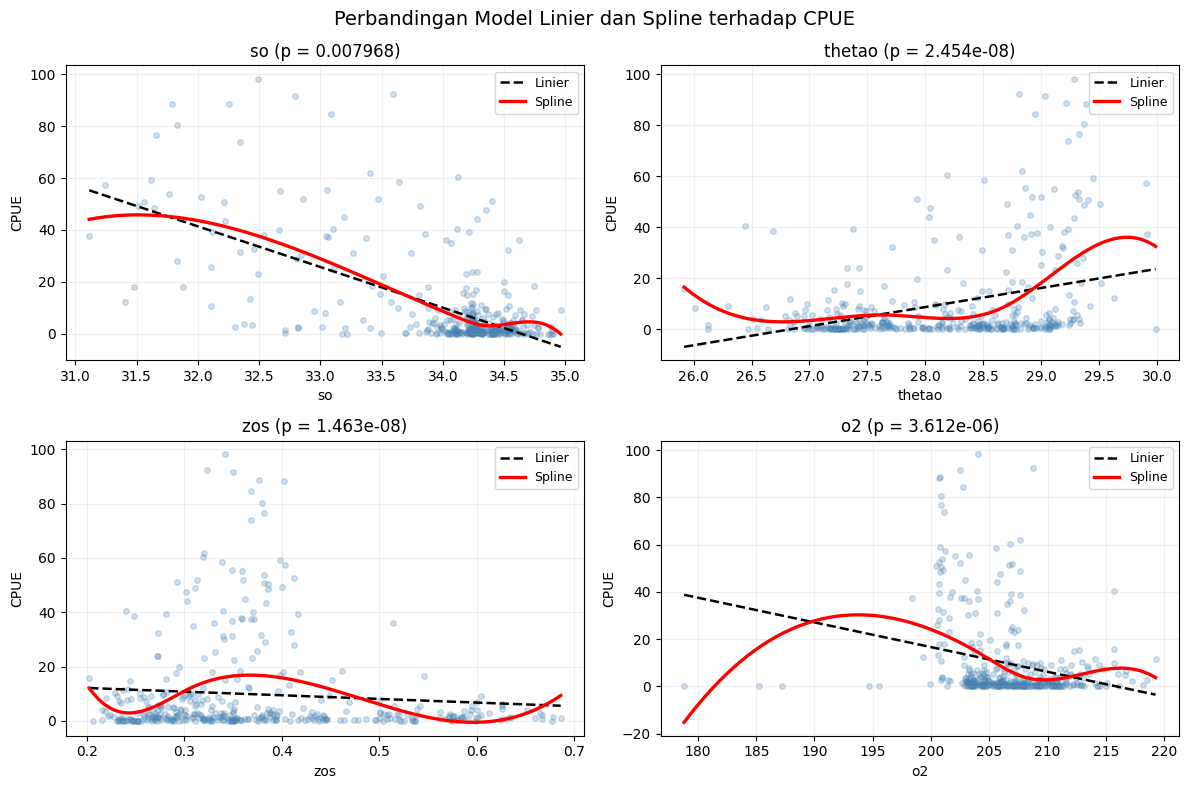

In [82]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from patsy import dmatrix

# Empat peubah utama
variabel = ["so", "thetao", "zos", "o2"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(variabel):

    data = df[[col, "cpue"]].dropna().copy()
    x = data[col].astype(float)
    y = data["cpue"].astype(float)

    # Model linier
    X_lin = sm.add_constant(x)
    model_lin = sm.OLS(y, X_lin).fit()

    # Model spline kubik
    formula_spline = "bs(x, df=5, degree=3, include_intercept=False)"
    X_spline = dmatrix(
        formula_spline,
        {"x": x},
        return_type="dataframe"
    )
    model_spline = sm.OLS(y, X_spline).fit()

    # Uji F
    F, p_value, _ = model_spline.compare_f_test(model_lin)

    # Grid untuk menggambar kurva
    x_grid = np.linspace(x.min(), x.max(), 200)

    X_lin_grid = sm.add_constant(
        pd.Series(x_grid, name=col),
        has_constant="add"
    )
    y_lin = model_lin.predict(X_lin_grid)

    # Gunakan basis spline yang sama dengan data latih
    from patsy import build_design_matrices
    X_spline_grid = build_design_matrices(
        [X_spline.design_info],
        {"x": x_grid}
    )[0]
    y_spline = model_spline.predict(X_spline_grid)

    ax = axes[i]

    ax.scatter(x, y, color="steelblue", alpha=0.25, s=16)

    ax.plot(
        x_grid, y_lin,
        color="black", linestyle="--",
        linewidth=1.8, label="Linier"
    )

    ax.plot(
        x_grid, y_spline,
        color="red",
        linewidth=2.4, label="Spline"
    )

    ax.set_title(f"{col} (p = {p_value:.4g})", fontsize=12)
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel("CPUE", fontsize=10)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)

plt.suptitle(
    "Perbandingan Model Linier dan Spline terhadap CPUE",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [83]:
# =========================================================
# 1. IMPORT LIBRARY
# =========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import Point, Polygon
from matplotlib.patches import Rectangle

# =========================================================
# 2. BACA DATA
# =========================================================
file_path = "Data Periode September - November.xlsx"   # sesuaikan kalau perlu
data = pd.read_excel(file_path)

print("Ukuran data:", data.shape)
print("Kolom:", data.columns.tolist())
data.head()

Ukuran data: (401, 15)
Kolom: ['Longitude', 'Latitude', 'periode', 'id_wpp_tangkap', 'so', 'thetao', 'zos', 'uo', 'vo', 'chl', 'o2', 'mlotst', 'nppv', 'Kecepatan', 'cpue']


,Longitude,Latitude,periode,id_wpp_tangkap,so,thetao,zos,uo,vo,chl,o2,mlotst,nppv,Kecepatan,cpue
0,92.25,2.75,Sep23_Nov23,572,32.456251,29.179822,0.409609,0.007200,-0.005725,0.116589,200.629854,18.672807,4.189994,0.009199,32.812079
1,92.25,3.25,Sep23_Nov23,572,32.112098,29.233677,0.416061,0.048852,-0.034232,0.109667,200.716746,16.415003,3.758218,0.059652,39.330566
2,92.25,3.75,Sep23_Nov23,572,31.879946,29.342594,0.418971,0.068079,-0.070260,0.106332,200.683519,16.389571,3.515052,0.097833,18.095839
3,92.75,1.25,Sep23_Nov23,572,32.817345,29.142013,0.384966,-0.286021,-0.012049,0.139036,201.433196,16.830394,5.487492,0.286274,2.806741
4,92.75,2.75,Sep23_Nov23,572,32.429830,29.242229,0.407123,0.036594,-0.038515,0.115609,200.629267,18.580969,4.174876,0.053128,13.232582


In [84]:
# =========================================================
# 3. CEK NAMA KOLOM YANG DIPAKAI
# =========================================================
# sesuaikan kalau ada perbedaan nama kolom
lon_col = "Longitude"
lat_col = "Latitude"
cpue_col = "cpue"   # pakai huruf kecil sesuai data kakak

# cek missing
print(data[[lon_col, lat_col, cpue_col]].isna().sum())

# buang data yang belum lengkap
data = data.dropna(subset=[lon_col, lat_col, cpue_col]).copy()

print("Ukuran data setelah drop NA:", data.shape)

Longitude    0
Latitude     0
cpue         0
dtype: int64
Ukuran data setelah drop NA: (401, 15)


In [85]:
# =========================================================
# 4. BATASI WILAYAH STUDI
# =========================================================
# kira-kira sesuai WPPNRI 713, 714, 715
xmin, xmax = 92, 127
ymin, ymax = -15, 7

data = data[
    (data[lon_col] >= xmin) & (data[lon_col] <= xmax) &
    (data[lat_col] >= ymin) & (data[lat_col] <= ymax)
].copy()

print("Ukuran data dalam wilayah studi:", data.shape)

Ukuran data dalam wilayah studi: (401, 15)


In [86]:
# =========================================================
# 5. BENTUK GRID 0.5 x 0.5 DERAJAT
# =========================================================
grid_size = 0.5

# fungsi untuk membulatkan ke grid bawah
def floor_to_grid(x, size=0.5):
    return np.floor(x / size) * size

data["lon_grid"] = data[lon_col].apply(lambda x: floor_to_grid(x, grid_size))
data["lat_grid"] = data[lat_col].apply(lambda x: floor_to_grid(x, grid_size))

# centroid grid
data["lon_center"] = data["lon_grid"] + grid_size / 2
data["lat_center"] = data["lat_grid"] + grid_size / 2

data.head()

,Longitude,Latitude,periode,id_wpp_tangkap,so,thetao,zos,uo,vo,chl,o2,mlotst,nppv,Kecepatan,cpue,lon_grid,lat_grid,lon_center,lat_center
0,92.25,2.75,Sep23_Nov23,572,32.456251,29.179822,0.409609,0.007200,-0.005725,0.116589,200.629854,18.672807,4.189994,0.009199,32.812079,92.0,2.5,92.25,2.75
1,92.25,3.25,Sep23_Nov23,572,32.112098,29.233677,0.416061,0.048852,-0.034232,0.109667,200.716746,16.415003,3.758218,0.059652,39.330566,92.0,3.0,92.25,3.25
2,92.25,3.75,Sep23_Nov23,572,31.879946,29.342594,0.418971,0.068079,-0.070260,0.106332,200.683519,16.389571,3.515052,0.097833,18.095839,92.0,3.5,92.25,3.75
3,92.75,1.25,Sep23_Nov23,572,32.817345,29.142013,0.384966,-0.286021,-0.012049,0.139036,201.433196,16.830394,5.487492,0.286274,2.806741,92.5,1.0,92.75,1.25
4,92.75,2.75,Sep23_Nov23,572,32.429830,29.242229,0.407123,0.036594,-0.038515,0.115609,200.629267,18.580969,4.174876,0.053128,13.232582,92.5,2.5,92.75,2.75


Jumlah observasi : 401
Jumlah grid data : 401


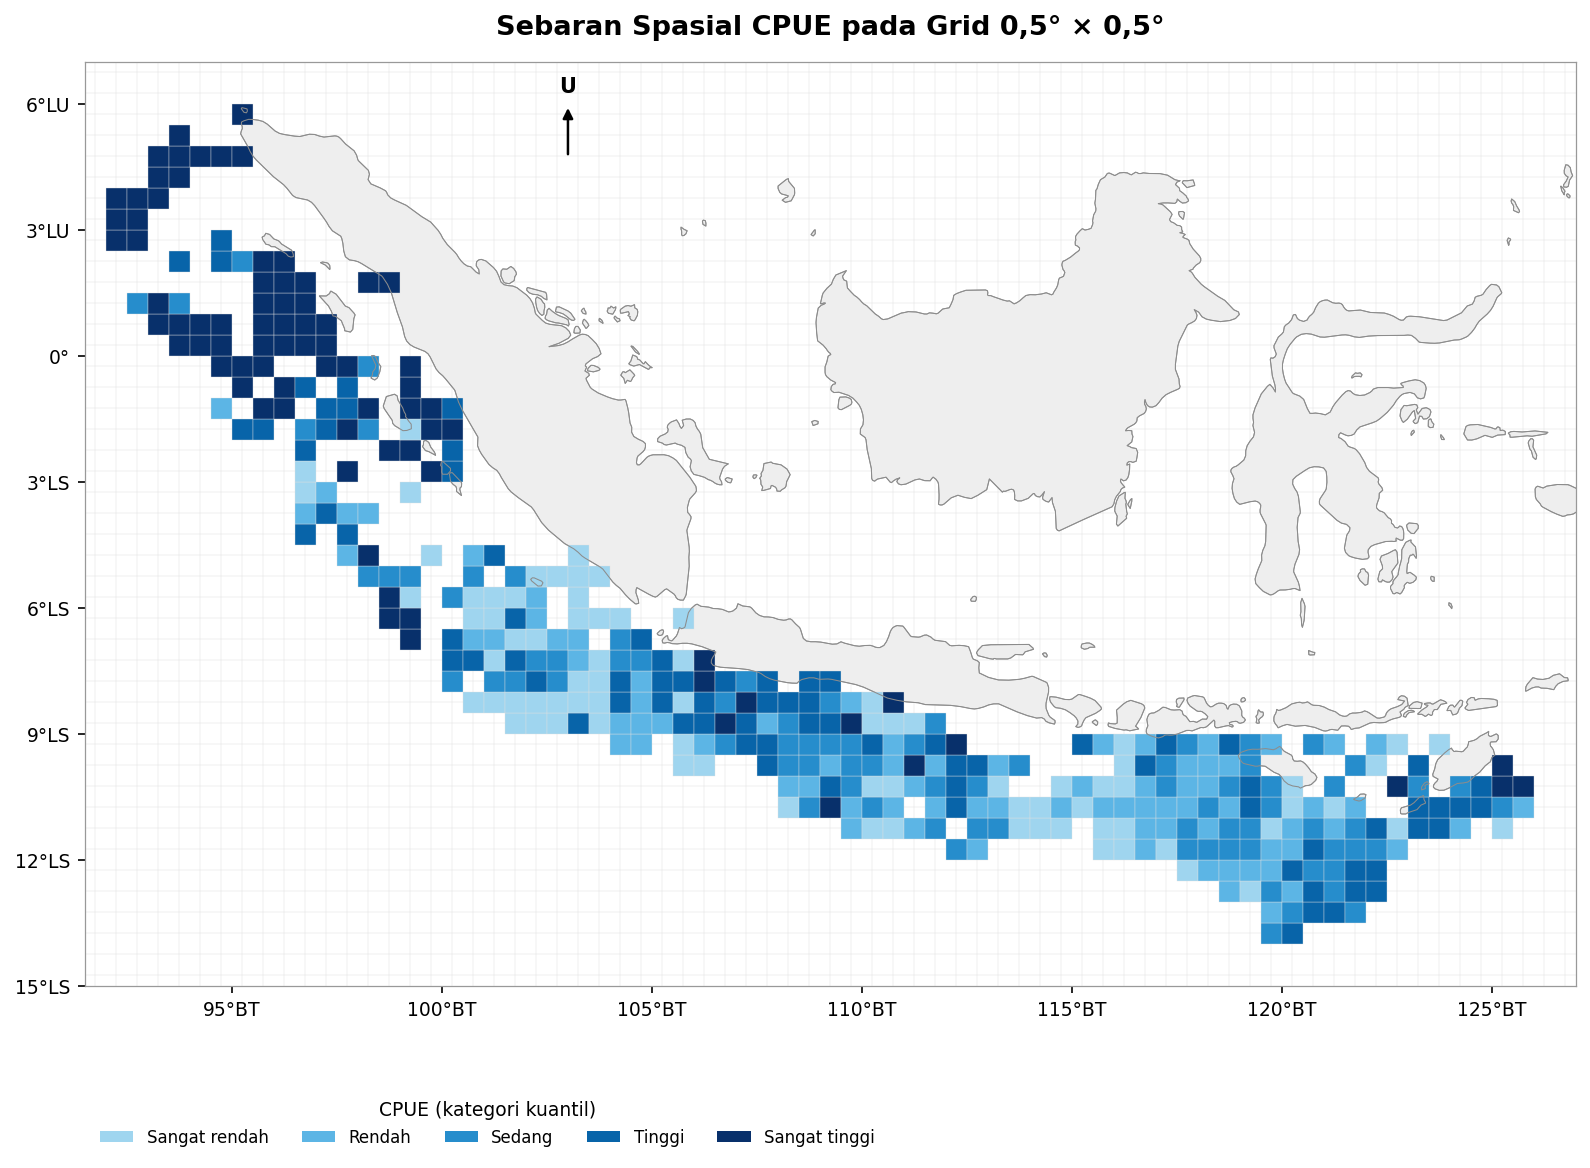

✅ Peta selesai
Lokasi file: /content/PETA_CPUE_GRID_INDONESIA.png


In [87]:
# ================================================================
# PETA SEBARAN SPASIAL CPUE — GRID 0.5° × 0.5°
# TAMPILAN MENYERUPAI PETA REFERENSI
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
from matplotlib.colors import ListedColormap, BoundaryNorm
from pathlib import Path

# ================================================================
# 1. DATA EMPIRIS
# ================================================================

data_peta = data_esf.copy()

GRID_SIZE = 0.5
HALF = GRID_SIZE / 2

# Koordinat asli digunakan sebagai pusat grid
grid_cpue = (
    data_peta
    .groupby(["Longitude", "Latitude"], as_index=False)
    .agg(cpue=("cpue", "mean"))
)

print("Jumlah observasi :", len(data_peta))
print("Jumlah grid data :", len(grid_cpue))

# ================================================================
# 2. PALET WARNA BIRU
#    Gunakan 5 kategori kuantil supaya warna tidak pucat
# ================================================================

WARNA_BIRU = [
    "#9fd5ef",   # sangat rendah
    "#5cb5e5",   # rendah
    "#268dcc",   # sedang
    "#0864a9",   # tinggi
    "#08306b"    # sangat tinggi
]

cmap = ListedColormap(WARNA_BIRU)

# Batas kuantil berdasarkan CPUE aktual
nilai_cpue = grid_cpue["cpue"].to_numpy(dtype=float)

# Peringkat digunakan agar kelompok tidak timpang
# bila ada banyak nilai CPUE yang sama
rank_cpue = pd.Series(nilai_cpue).rank(
    method="average", pct=True
).to_numpy()

kategori = np.minimum(
    (rank_cpue * 5).astype(int),
    4
)

grid_cpue["Kategori"] = kategori

# ================================================================
# 3. BATAS PETA
# ================================================================

XMIN, XMAX = 91.5, 127.0
YMIN, YMAX = -15.0, 7.0

# ================================================================
# 4. SIAPKAN GAMBAR
# ================================================================

fig, ax = plt.subplots(figsize=(14, 8), dpi=150)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# ================================================================
# 5. GARIS GRID KECIL DI SELURUH PETA
#    0.5° × 0.5°, sangat tipis seperti referensi
# ================================================================

# Karena koordinat data digunakan sebagai pusat grid,
# garis grid berada pada batas sel (offset 0.25°)

x_lines = np.arange(
    np.floor((XMIN - HALF) / GRID_SIZE) * GRID_SIZE + HALF,
    XMAX + GRID_SIZE,
    GRID_SIZE
)

y_lines = np.arange(
    np.floor((YMIN - HALF) / GRID_SIZE) * GRID_SIZE + HALF,
    YMAX + GRID_SIZE,
    GRID_SIZE
)

for x in x_lines:
    ax.axvline(
        x,
        color="#dedede",
        linewidth=0.22,
        zorder=0
    )

for y in y_lines:
    ax.axhline(
        y,
        color="#dedede",
        linewidth=0.22,
        zorder=0
    )

# ================================================================
# 6. DARATAN INDONESIA
# ================================================================

indo.plot(
    ax=ax,
    facecolor="#eeeeee",
    edgecolor="#999999",
    linewidth=0.45,
    zorder=2
)

# ================================================================
# 7. GRID YANG MEMILIKI CPUE
# ================================================================

kotak = []
warna = []

for _, row in grid_cpue.iterrows():

    lon = float(row["Longitude"])
    lat = float(row["Latitude"])

    kotak.append(
        Rectangle(
            (lon - HALF, lat - HALF),
            GRID_SIZE,
            GRID_SIZE
        )
    )

    warna.append(
        WARNA_BIRU[int(row["Kategori"])]
    )

collection = PatchCollection(
    kotak,
    facecolor=warna,
    edgecolor="#e0e0e0",
    linewidth=0.18,
    alpha=1.0,
    zorder=3
)

ax.add_collection(collection)

# ================================================================
# 8. GARIS PANTAI DAN BATAS DARATAN
# ================================================================

indo.boundary.plot(
    ax=ax,
    color="#8c8c8c",
    linewidth=0.50,
    zorder=4
)

# ================================================================
# 9. PANAH UTARA
# ================================================================

# Kompas sederhana di kanan atas area daratan
cx, cy = 103.0, 5.0

ax.annotate(
    "",
    xy=(cx, cy + 1.0),
    xytext=(cx, cy - 0.3),
    arrowprops=dict(
        arrowstyle="-|>",
        color="black",
        lw=1.2
    ),
    zorder=6
)

ax.text(
    cx, cy + 1.18,
    "U",
    ha="center",
    va="bottom",
    fontsize=10,
    fontweight="bold",
    zorder=6
)

# ================================================================
# 10. FORMAT PETA
# ================================================================

ax.set_xlim(XMIN, XMAX)
ax.set_ylim(YMIN, YMAX)

ax.set_aspect("equal")

# Label setiap 5 derajat
xticks = np.arange(95, 126, 5)
yticks = np.arange(-15, 7, 3)

ax.set_xticks(xticks)
ax.set_yticks(yticks)

ax.set_xticklabels(
    [f"{int(v)}°BT" for v in xticks],
    fontsize=9
)

ax.set_yticklabels(
    [
        f"{abs(int(v))}°LS" if v < 0
        else ("0°" if v == 0 else f"{int(v)}°LU")
        for v in yticks
    ],
    fontsize=9
)

ax.set_xlabel("")
ax.set_ylabel("")

ax.set_title(
    "Sebaran Spasial CPUE pada Grid 0,5° × 0,5°",
    fontsize=13,
    fontweight="bold",
    pad=13
)

# ================================================================
# 11. LEGENDA KATEGORI CPUE
# ================================================================

from matplotlib.patches import Patch

labels = [
    "Sangat rendah",
    "Rendah",
    "Sedang",
    "Tinggi",
    "Sangat tinggi"
]

handles = [
    Patch(facecolor=c, edgecolor="none", label=l)
    for c, l in zip(WARNA_BIRU, labels)
]

ax.legend(
    handles=handles,
    title="CPUE (kategori kuantil)",
    loc="lower left",
    bbox_to_anchor=(0.0, -0.19),
    ncol=5,
    frameon=False,
    fontsize=8,
    title_fontsize=9
)

for spine in ax.spines.values():
    spine.set_linewidth(0.6)
    spine.set_color("#999999")

# ================================================================
# 12. SIMPAN GAMBAR
# ================================================================

OUTPUT_PETA = Path("/content/PETA_CPUE_GRID_INDONESIA.png")

plt.savefig(
    OUTPUT_PETA,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("✅ Peta selesai")
print("Lokasi file:", OUTPUT_PETA)

Jumlah lokasi data: 401
Wilayah WPP ditemukan:
['WPP-RI 572', 'WPP-RI 573']

REKAP GRID WPP
Grid laut total : 752
Grid ada data   : 401
Grid tanpa data : 351


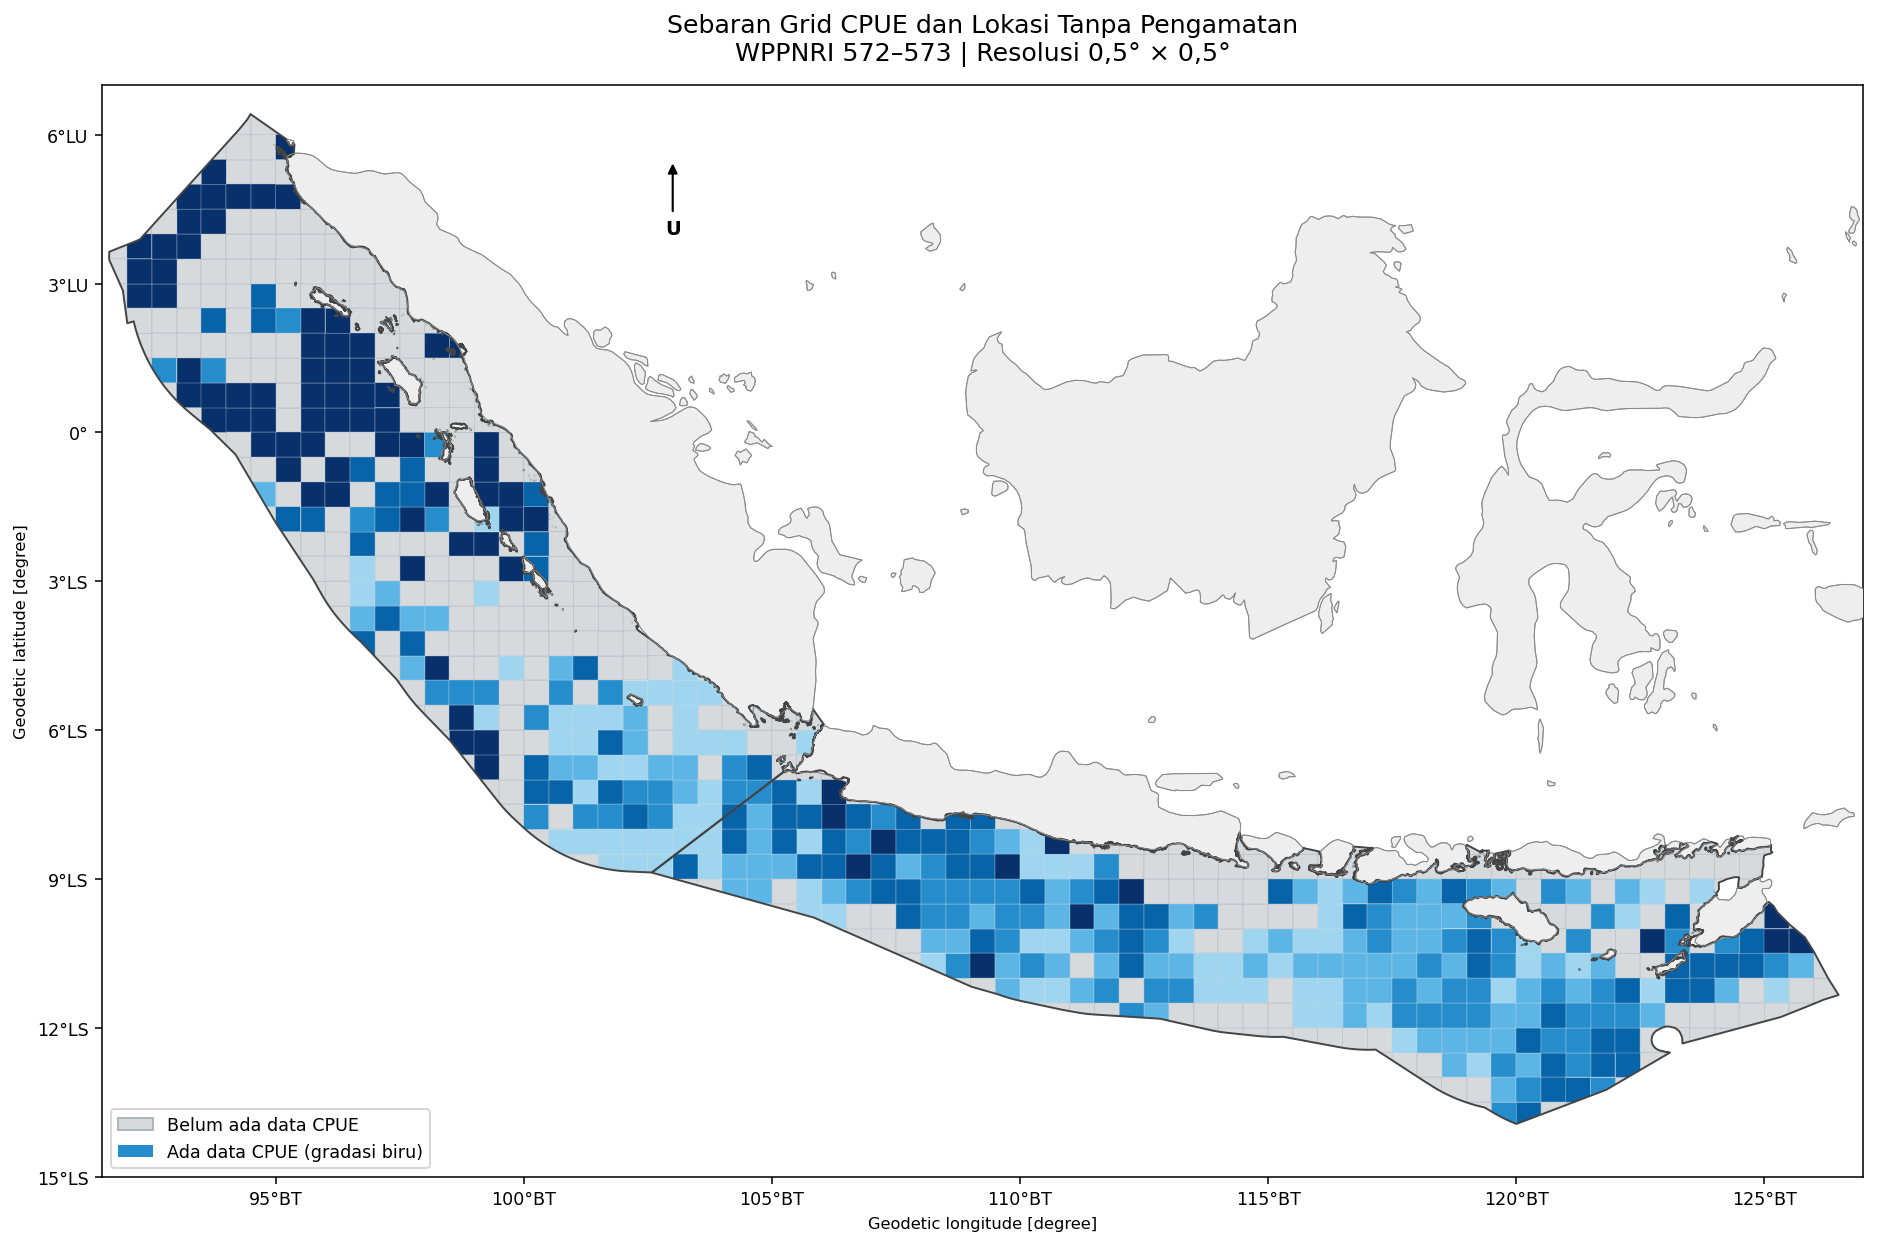


✅ PETA DAN GRID LENGKAP SELESAI


In [88]:
# ================================================================
# PETA GRID LENGKAP WPP 572–573
# BIRU = ADA DATA CPUE
# ABU  = BELUM ADA DATA CPUE
# DARAT = TIDAK DIJADIKAN GRID TARGET
# ================================================================

!pip -q install geopandas shapely requests

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests

from urllib.parse import urlencode
from shapely.geometry import box
from shapely.prepared import prep
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# ------------------------------------------------
# 1. DATA CPUE ASLI
# ------------------------------------------------

DATA_ASLI = data_esf.copy()

GRID_SIZE = 0.5
HALF = GRID_SIZE / 2

GRID_ADA = (
    DATA_ASLI
    .groupby(["Longitude", "Latitude"], as_index=False)
    .agg(cpue=("cpue", "mean"))
)

print("Jumlah lokasi data:", len(GRID_ADA))

# ------------------------------------------------
# 2. AMBIL BATAS RESMI WPP 572 DAN 573 DARI BIG
# ------------------------------------------------

BASE_URL = (
    "https://kspservices.big.go.id/satupeta/rest/services/"
    "PUBLIK/SUMBER_DAYA_ALAM_DAN_LINGKUNGAN/"
    "MapServer/21/query"
)

PARAMS = {
    "where": "namobj IN ('WPP-RI 572','WPP-RI 573')",
    "outFields": "namobj,kodwpp",
    "returnGeometry": "true",
    "outSR": "4326",
    "f": "geojson"
}

response = requests.get(
    BASE_URL,
    params=PARAMS,
    timeout=90
)
response.raise_for_status()

geojson = response.json()

if "features" not in geojson or not geojson["features"]:
    raise RuntimeError(
        "Poligon WPP tidak berhasil diambil dari BIG. "
        "Periksa koneksi atau respons layanan."
    )

WPP_GDF = gpd.GeoDataFrame.from_features(
    geojson["features"],
    crs="EPSG:4326"
)

WPP_GDF = WPP_GDF[
    WPP_GDF["namobj"].isin(["WPP-RI 572", "WPP-RI 573"])
].copy()

print("Wilayah WPP ditemukan:")
print(WPP_GDF["namobj"].tolist())

# ------------------------------------------------
# 3. BATAS LAUT DAN DARAT
# ------------------------------------------------

WPP_AREA = WPP_GDF.geometry.union_all()

# indo adalah GeoDataFrame peta Indonesia dari cell sebelumnya
DARAT = indo.to_crs("EPSG:4326").geometry.union_all()

# Potong wilayah WPP dengan daratan
LAUT_WPP = WPP_AREA.difference(DARAT)

LAUT_PREP = prep(LAUT_WPP)

# ------------------------------------------------
# 4. BUAT SELURUH GRID 0.5°
# ------------------------------------------------

# Selaraskan pusat grid dengan koordinat data asli
lon_offset = float(
    np.mod(GRID_ADA["Longitude"].iloc[0], GRID_SIZE)
)

lat_offset = float(
    np.mod(GRID_ADA["Latitude"].iloc[0], GRID_SIZE)
)

# Pastikan data memakai satu lattice grid yang konsisten
for col, offset in [
    ("Longitude", lon_offset),
    ("Latitude", lat_offset)
]:
    deviasi = np.abs(
        ((GRID_ADA[col].to_numpy() - offset + 0.25)
         % GRID_SIZE) - 0.25
    )

    if deviasi.max() > 1e-5:
        raise ValueError(
            f"Koordinat {col} tidak seluruhnya sejajar "
            "dengan grid 0.5 derajat."
        )

XMIN, XMAX = 91.5, 127.0
YMIN, YMAX = -15.0, 7.0

lon_awal = (
    np.floor((XMIN - lon_offset) / GRID_SIZE)
    * GRID_SIZE + lon_offset
)

lat_awal = (
    np.floor((YMIN - lat_offset) / GRID_SIZE)
    * GRID_SIZE + lat_offset
)

LON_CENTERS = np.arange(
    lon_awal, XMAX + GRID_SIZE, GRID_SIZE
)

LAT_CENTERS = np.arange(
    lat_awal, YMAX + GRID_SIZE, GRID_SIZE
)

# Buat kotak, hanya yang beririsan dengan wilayah laut WPP
daftar_grid = []

for lon in LON_CENTERS:
    for lat in LAT_CENTERS:

        kotak = box(
            lon - HALF,
            lat - HALF,
            lon + HALF,
            lat + HALF
        )

        if not LAUT_PREP.intersects(kotak):
            continue

        # Potong grid agar mengikuti batas WPP dan garis pantai
        bentuk_laut = kotak.intersection(LAUT_WPP)

        if bentuk_laut.is_empty:
            continue

        daftar_grid.append({
            "Longitude": round(float(lon), 6),
            "Latitude": round(float(lat), 6),
            "geometry": bentuk_laut
        })

GRID_LENGKAP = gpd.GeoDataFrame(
    daftar_grid,
    geometry="geometry",
    crs="EPSG:4326"
)

# ------------------------------------------------
# 5. TANDAI GRID ADA DATA / TIDAK ADA DATA
# ------------------------------------------------

GRID_ADA["Longitude"] = GRID_ADA["Longitude"].round(6)
GRID_ADA["Latitude"] = GRID_ADA["Latitude"].round(6)

GRID_LENGKAP = GRID_LENGKAP.merge(
    GRID_ADA,
    on=["Longitude", "Latitude"],
    how="left",
    validate="one_to_one"
)

GRID_LENGKAP["Status"] = np.where(
    GRID_LENGKAP["cpue"].notna(),
    "Ada Data",
    "Belum Ada Data"
)

GRID_BIRU = GRID_LENGKAP[
    GRID_LENGKAP["Status"] == "Ada Data"
].copy()

GRID_ABU = GRID_LENGKAP[
    GRID_LENGKAP["Status"] == "Belum Ada Data"
].copy()

print("\nREKAP GRID WPP")
print("Grid laut total :", len(GRID_LENGKAP))
print("Grid ada data   :", len(GRID_BIRU))
print("Grid tanpa data :", len(GRID_ABU))

# ------------------------------------------------
# 6. WARNA BIRU YANG SUDAH KAKAK SUKA
# ------------------------------------------------

WARNA_BIRU = [
    "#9fd5ef",
    "#5cb5e5",
    "#268dcc",
    "#0864a9",
    "#08306b"
]

CMAP_BIRU = ListedColormap(WARNA_BIRU)

if len(GRID_BIRU) > 0:
    GRID_BIRU["Kategori"] = (
        GRID_BIRU["cpue"]
        .rank(method="average", pct=True)
        .mul(5)
        .astype(int)
        .clip(upper=4)
    )

# ------------------------------------------------
# 7. GAMBAR PETA
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(15, 9), dpi=140)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Semua grid laut yang belum mempunyai CPUE
if len(GRID_ABU):
    GRID_ABU.plot(
        ax=ax,
        color="#d6dadd",
        edgecolor="#aeb6ba",
        linewidth=0.23,
        zorder=2
    )

# Grid yang punya CPUE
if len(GRID_BIRU):
    GRID_BIRU.plot(
        ax=ax,
        column="Kategori",
        cmap=CMAP_BIRU,
        vmin=0,
        vmax=4,
        edgecolor="#c9dce5",
        linewidth=0.16,
        zorder=3
    )

# Daratan menutupi area pulau
indo.plot(
    ax=ax,
    facecolor="#eeeeee",
    edgecolor="#929292",
    linewidth=0.55,
    zorder=4
)

# Batas luar WPP 572–573
WPP_GDF.boundary.plot(
    ax=ax,
    color="#444444",
    linewidth=1.0,
    zorder=5
)

# Garis pantai
indo.boundary.plot(
    ax=ax,
    color="#8a8a8a",
    linewidth=0.45,
    zorder=6
)

# ------------------------------------------------
# 8. FORMAT PETA
# ------------------------------------------------

ax.set_xlim(XMIN, XMAX)
ax.set_ylim(YMIN, YMAX)
ax.set_aspect("equal")

xticks = np.arange(95, 126, 5)
yticks = np.arange(-15, 7, 3)

ax.set_xticks(xticks)
ax.set_yticks(yticks)

ax.set_xticklabels(
    [f"{v}°BT" for v in xticks]
)

ax.set_yticklabels([
    f"{abs(v)}°LS" if v < 0
    else ("0°" if v == 0 else f"{v}°LU")
    for v in yticks
])

ax.tick_params(labelsize=9)

ax.set_title(
    "Sebaran Grid CPUE dan Lokasi Tanpa Pengamatan\n"
    "WPPNRI 572–573 | Resolusi 0,5° × 0,5°",
    fontsize=13,
    pad=13
)

# Utara
ax.annotate(
    "U",
    xy=(103, 5.5),
    xytext=(103, 4.0),
    arrowprops=dict(
        arrowstyle="-|>",
        color="black",
        lw=1.1
    ),
    ha="center",
    fontsize=10,
    fontweight="bold"
)

legend_items = [
    Patch(
        facecolor="#d6dadd",
        edgecolor="#aeb6ba",
        label="Belum ada data CPUE"
    ),
    Patch(
        facecolor="#268dcc",
        edgecolor="none",
        label="Ada data CPUE (gradasi biru)"
    )
]

ax.legend(
    handles=legend_items,
    loc="lower left",
    fontsize=9,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "/content/PETA_GRID_LENGKAP_WPP_572_573.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 9. SIMPAN GRID UNTUK TAHAP SELANJUTNYA
# ------------------------------------------------

GRID_LENGKAP.drop(
    columns="geometry"
).to_csv(
    "/content/GRID_LENGKAP_WPP_572_573.csv",
    index=False
)

print("\n✅ PETA DAN GRID LENGKAP SELESAI")

Jumlah grid dalam peta : 752
Jumlah lokasi berdata  : 401
Jumlah variabel X      : 10

STATISTIK DESKRIPTIF 10 VARIABEL X


,count,mean,std,min,25%,50%,75%,max,missing
so,401.0,34.0189,0.7248,31.1141,34.0217,34.2455,34.4213,34.9614,0
thetao,401.0,28.1431,0.8179,25.9184,27.4305,28.2156,28.8063,29.9861,0
zos,401.0,0.3742,0.1138,0.2024,0.2888,0.3478,0.4312,0.6860,0
uo,401.0,-0.2771,0.2123,-0.7690,-0.4304,-0.2941,-0.0957,0.2569,0
vo,401.0,-0.0253,0.0861,-0.5991,-0.0585,-0.0132,0.0235,0.2634,0
chl,401.0,0.4505,0.4747,0.1063,0.1556,0.3323,0.5404,3.9720,0
o2,401.0,206.5878,4.3842,178.8123,203.6571,206.4205,209.3086,219.2706,0
mlotst,401.0,14.3143,2.4396,10.1675,12.3346,14.0880,15.7071,23.1587,0
nppv,401.0,29.5603,30.8860,3.5151,7.3928,19.8751,40.0398,215.5102,0
Kecepatan,401.0,0.3075,0.1879,0.0081,0.1297,0.3071,0.4376,0.7699,0


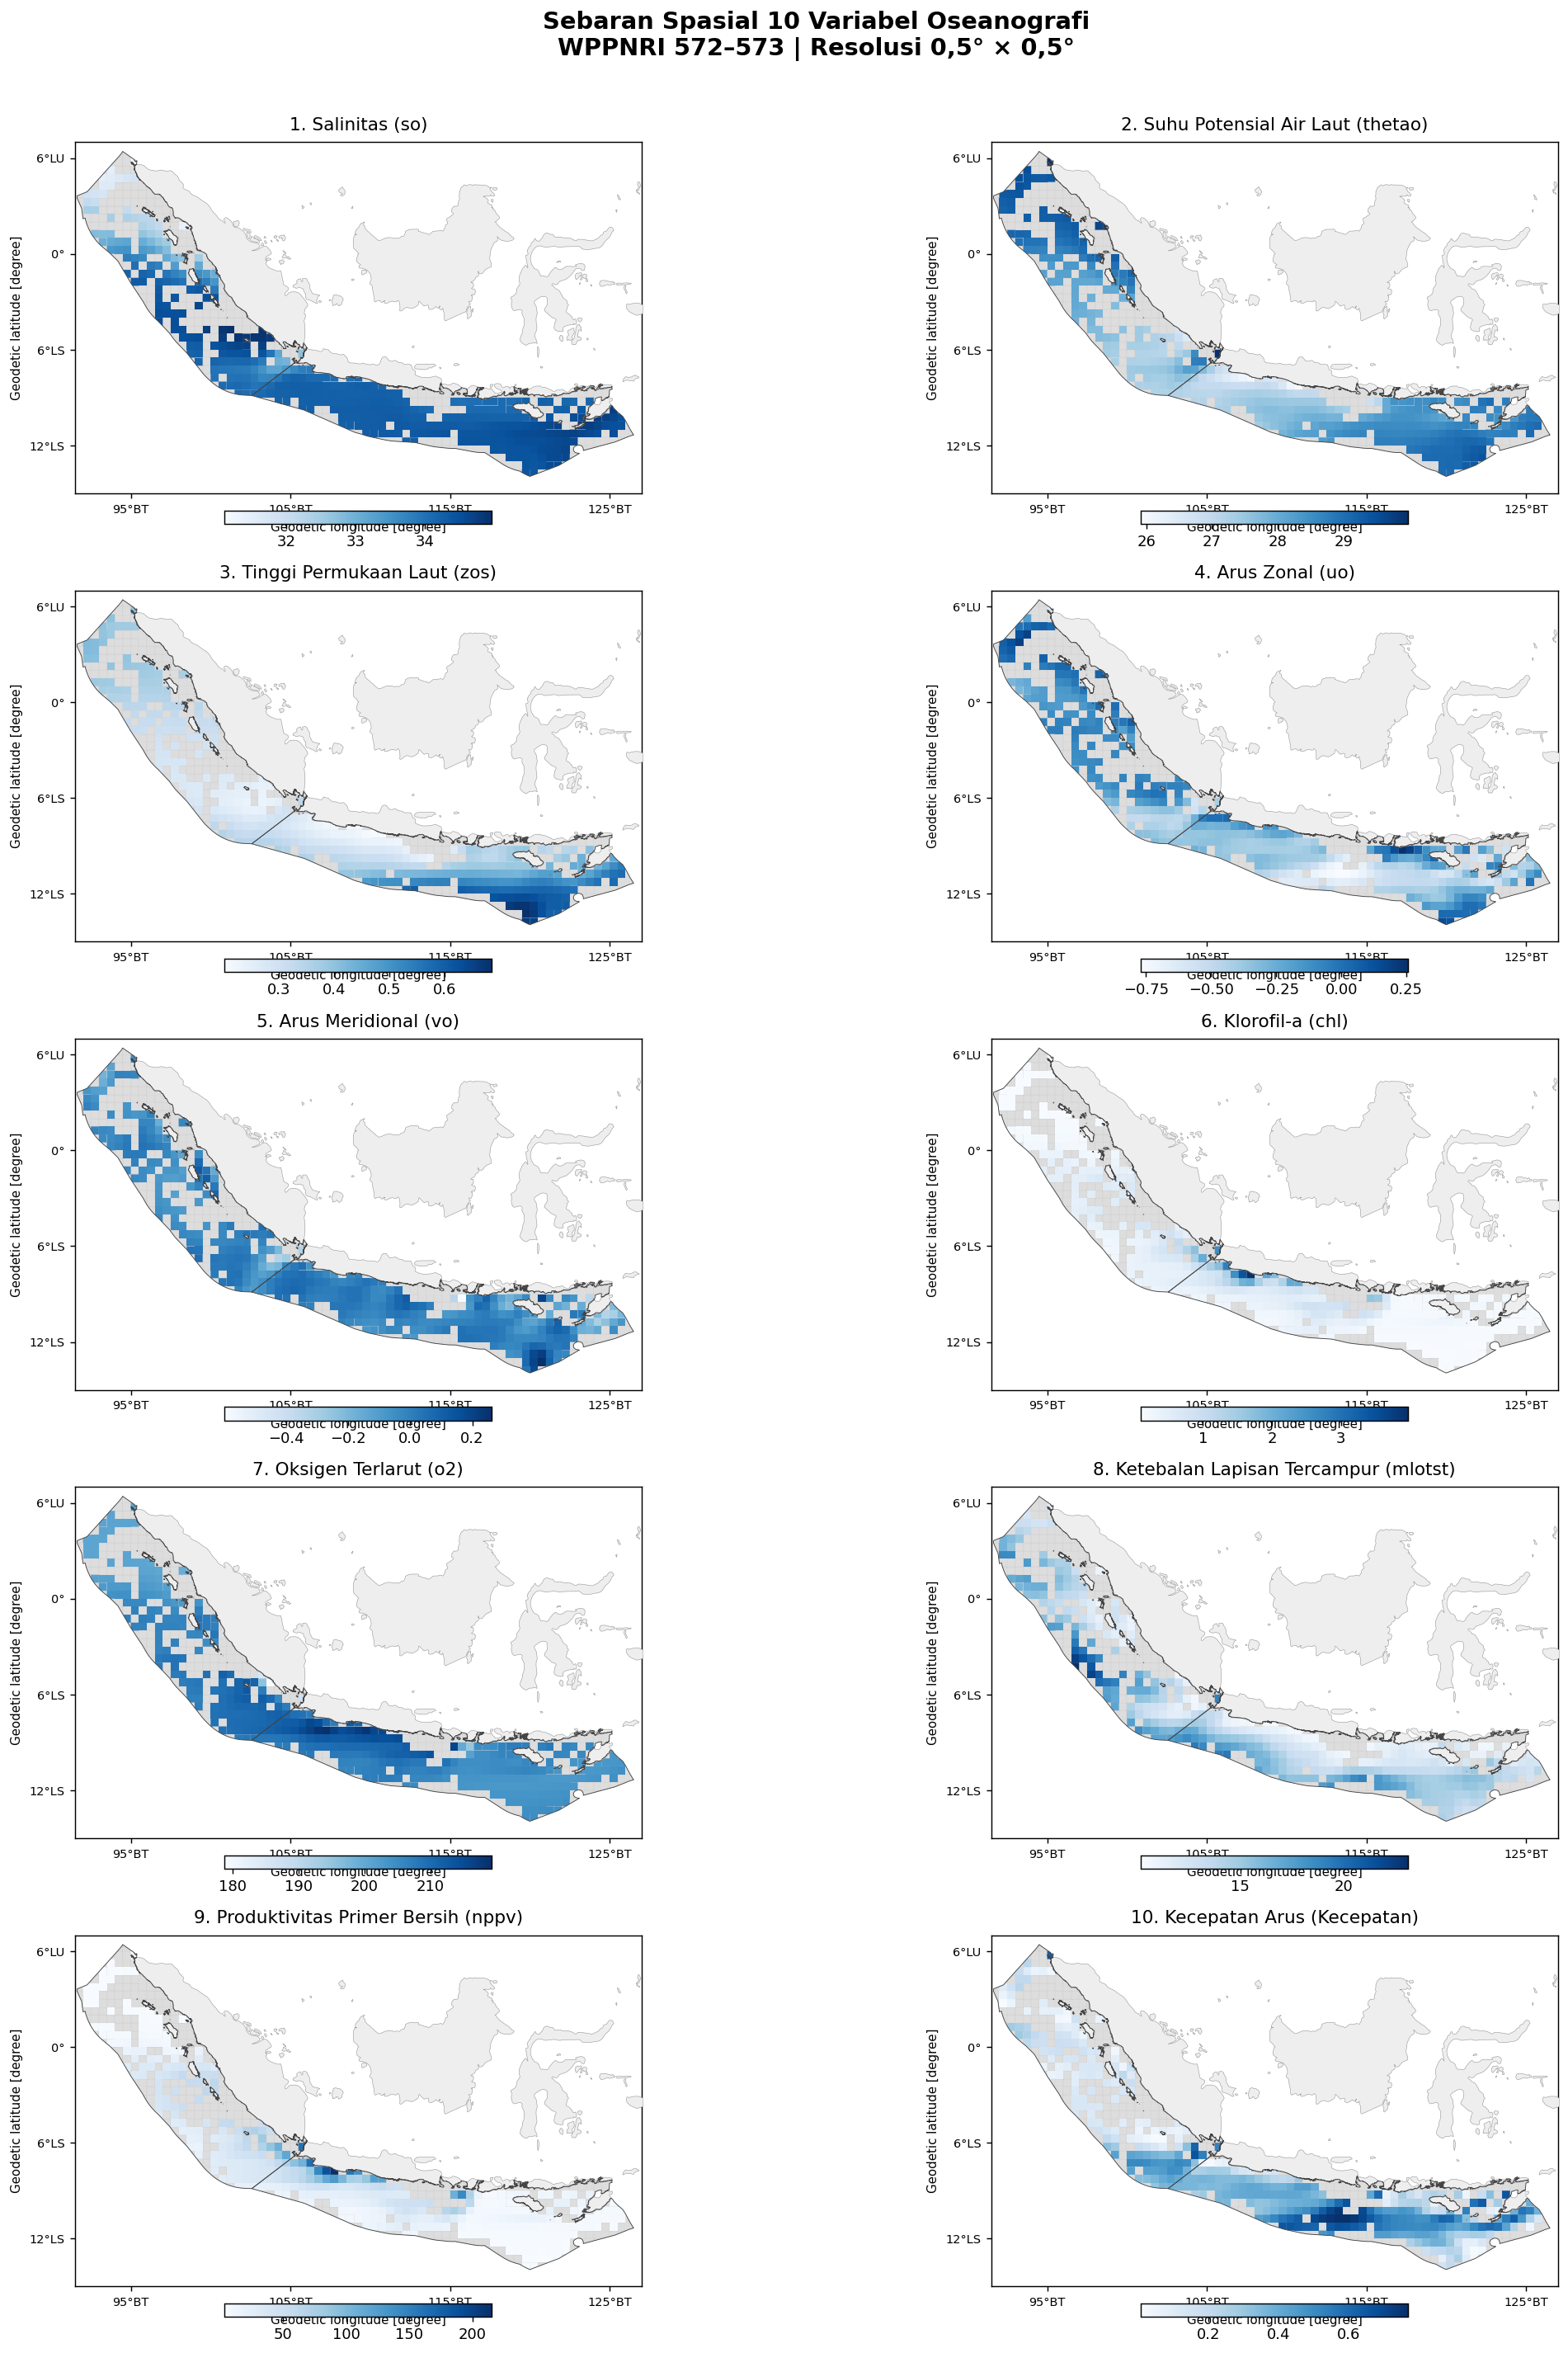


✅ PETA 10 VARIABEL X SELESAI
File: /content/PETA_10_VARIABEL_OSEANOGRAFI.png


In [89]:

# ================================================================
# EKSPLORASI SPASIAL 10 VARIABEL OSEANOGRAFI (X)
# WPPNRI 572–573 | GRID 0,5° × 0,5°
#
# Menggunakan objek yang sudah dibuat:
# data_esf, GRID_LENGKAP, WPP_GDF, indo
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# ------------------------------------------------
# 1. DAFTAR VARIABEL
# ------------------------------------------------

VAR_X = [
    "so",
    "thetao",
    "zos",
    "uo",
    "vo",
    "chl",
    "o2",
    "mlotst",
    "nppv",
    "Kecepatan"
]

NAMA_X = {
    "so": "Salinitas",
    "thetao": "Suhu Potensial Air Laut",
    "zos": "Tinggi Permukaan Laut",
    "uo": "Arus Zonal",
    "vo": "Arus Meridional",
    "chl": "Klorofil-a",
    "o2": "Oksigen Terlarut",
    "mlotst": "Ketebalan Lapisan Tercampur",
    "nppv": "Produktivitas Primer Bersih",
    "Kecepatan": "Kecepatan Arus"
}

# ------------------------------------------------
# 2. CEK KOLOM DAN OBJEK
# ------------------------------------------------

for nama_obj in ["data_esf", "GRID_LENGKAP", "WPP_GDF", "indo"]:
    if nama_obj not in globals():
        raise NameError(
            f"Objek {nama_obj} belum tersedia. "
            "Jalankan cell peta grid sebelumnya."
        )

kolom_wajib = ["Longitude", "Latitude"] + VAR_X
kolom_hilang = [
    kol for kol in kolom_wajib
    if kol not in data_esf.columns
]

if kolom_hilang:
    raise ValueError(
        f"Kolom tidak ditemukan pada data_esf: {kolom_hilang}"
    )

# ------------------------------------------------
# 3. RINGKAS NILAI X PER LOKASI GRID ASLI
# ------------------------------------------------

DATA_X = data_esf.copy()

DATA_X["Longitude"] = (
    pd.to_numeric(DATA_X["Longitude"], errors="coerce")
    .round(6)
)
DATA_X["Latitude"] = (
    pd.to_numeric(DATA_X["Latitude"], errors="coerce")
    .round(6)
)

for kol in VAR_X:
    DATA_X[kol] = pd.to_numeric(
        DATA_X[kol], errors="coerce"
    )

GRID_X = (
    DATA_X
    .groupby(["Longitude", "Latitude"], as_index=False)[VAR_X]
    .mean()
)

# Pertahankan geometri grid dari peta sebelumnya.
# Tidak menggeser titik pusat grid.
GRID_PETA_X = GRID_LENGKAP[
    ["Longitude", "Latitude", "geometry"]
].copy()

GRID_PETA_X = GRID_PETA_X.merge(
    GRID_X,
    on=["Longitude", "Latitude"],
    how="left",
    validate="one_to_one"
)

print("Jumlah grid dalam peta :", len(GRID_PETA_X))
print("Jumlah lokasi berdata  :", len(GRID_X))
print("Jumlah variabel X      :", len(VAR_X))

# ------------------------------------------------
# 4. STATISTIK DESKRIPTIF VARIABEL X
# ------------------------------------------------

DESKRIPTIF_X = (
    DATA_X[VAR_X]
    .describe()
    .T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
)

DESKRIPTIF_X["missing"] = (
    DATA_X[VAR_X].isna().sum()
)

print("\nSTATISTIK DESKRIPTIF 10 VARIABEL X")
display(DESKRIPTIF_X.round(4))

# ------------------------------------------------
# 5. PETA 10 VARIABEL DALAM SATU GAMBAR
# ------------------------------------------------

fig, axes = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(19, 22),
    dpi=130
)

axes = axes.flatten()

PETA_DARAT = indo.to_crs("EPSG:4326")

for i, variabel in enumerate(VAR_X):

    ax = axes[i]

    # Latar grid belum berisi nilai X
    GRID_PETA_X.plot(
        ax=ax,
        color="#dddddd",
        edgecolor="#bcbcbc",
        linewidth=0.1,
        zorder=1
    )

    DATA_TERISI = GRID_PETA_X[
        GRID_PETA_X[variabel].notna()
    ].copy()

    if not DATA_TERISI.empty:

        nilai_min = float(DATA_TERISI[variabel].min())
        nilai_max = float(DATA_TERISI[variabel].max())

        # Hindari skala identik jika nilai konstan
        if np.isclose(nilai_min, nilai_max):
            nilai_min -= 1e-6
            nilai_max += 1e-6

        DATA_TERISI.plot(
            ax=ax,
            column=variabel,
            cmap="Blues",
            vmin=nilai_min,
            vmax=nilai_max,
            edgecolor="none",
            linewidth=0,
            zorder=2
        )

        norm = Normalize(
            vmin=nilai_min,
            vmax=nilai_max
        )

        sm = ScalarMappable(
            norm=norm,
            cmap="Blues"
        )

        sm.set_array([])

        fig.colorbar(
            sm,
            ax=ax,
            orientation="horizontal",
            fraction=0.035,
            pad=0.045,
            shrink=0.75
        )

    # Daratan
    PETA_DARAT.plot(
        ax=ax,
        facecolor="#eeeeee",
        edgecolor="#929292",
        linewidth=0.3,
        zorder=3
    )

    # Batas WPP
    WPP_GDF.boundary.plot(
        ax=ax,
        color="#444444",
        linewidth=0.5,
        zorder=4
    )

    ax.set_xlim(91.5, 127.0)
    ax.set_ylim(-15.0, 7.0)
    ax.set_aspect("equal")

    ax.set_title(
        f"{i + 1}. {NAMA_X[variabel]} ({variabel})",
        fontsize=12,
        pad=8
    )

    ax.set_xticks([95, 105, 115, 125])
    ax.set_yticks([-12, -6, 0, 6])

    ax.set_xticklabels(
        ["95°BT", "105°BT", "115°BT", "125°BT"],
        fontsize=8
    )
    ax.set_yticklabels(
        ["12°LS", "6°LS", "0°", "6°LU"],
        fontsize=8
    )

    ax.grid(False)

fig.suptitle(
    "Sebaran Spasial 10 Variabel Oseanografi\n"
    "WPPNRI 572–573 | Resolusi 0,5° × 0,5°",
    fontsize=16,
    fontweight="bold",
    y=0.995
)

plt.tight_layout(rect=[0, 0, 1, 0.985])

plt.savefig(
    "/content/PETA_10_VARIABEL_OSEANOGRAFI.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✅ PETA 10 VARIABEL X SELESAI")
print("File: /content/PETA_10_VARIABEL_OSEANOGRAFI.png")


Jumlah observasi : 401
Jumlah variabel  : 11


,count,mean,std,min,25%,50%,75%,max,Missing,Skewness
cpue,401.0,9.7550,17.9121,0.0001,0.5386,2.1758,8.4753,98.2354,0,2.6454
so,401.0,34.0189,0.7248,31.1141,34.0217,34.2455,34.4213,34.9614,0,-1.9881
thetao,401.0,28.1431,0.8179,25.9184,27.4305,28.2156,28.8063,29.9861,0,-0.2100
zos,401.0,0.3742,0.1138,0.2024,0.2888,0.3478,0.4312,0.6860,0,0.8952
uo,401.0,-0.2771,0.2123,-0.7690,-0.4304,-0.2941,-0.0957,0.2569,0,-0.0556
vo,401.0,-0.0253,0.0861,-0.5991,-0.0585,-0.0132,0.0235,0.2634,0,-1.5408
chl,401.0,0.4505,0.4747,0.1063,0.1556,0.3323,0.5404,3.9720,0,3.3818
o2,401.0,206.5878,4.3842,178.8123,203.6571,206.4205,209.3086,219.2706,0,-0.7672
mlotst,401.0,14.3143,2.4396,10.1675,12.3346,14.0880,15.7071,23.1587,0,0.6787
nppv,401.0,29.5603,30.8860,3.5151,7.3928,19.8751,40.0398,215.5102,0,2.3845


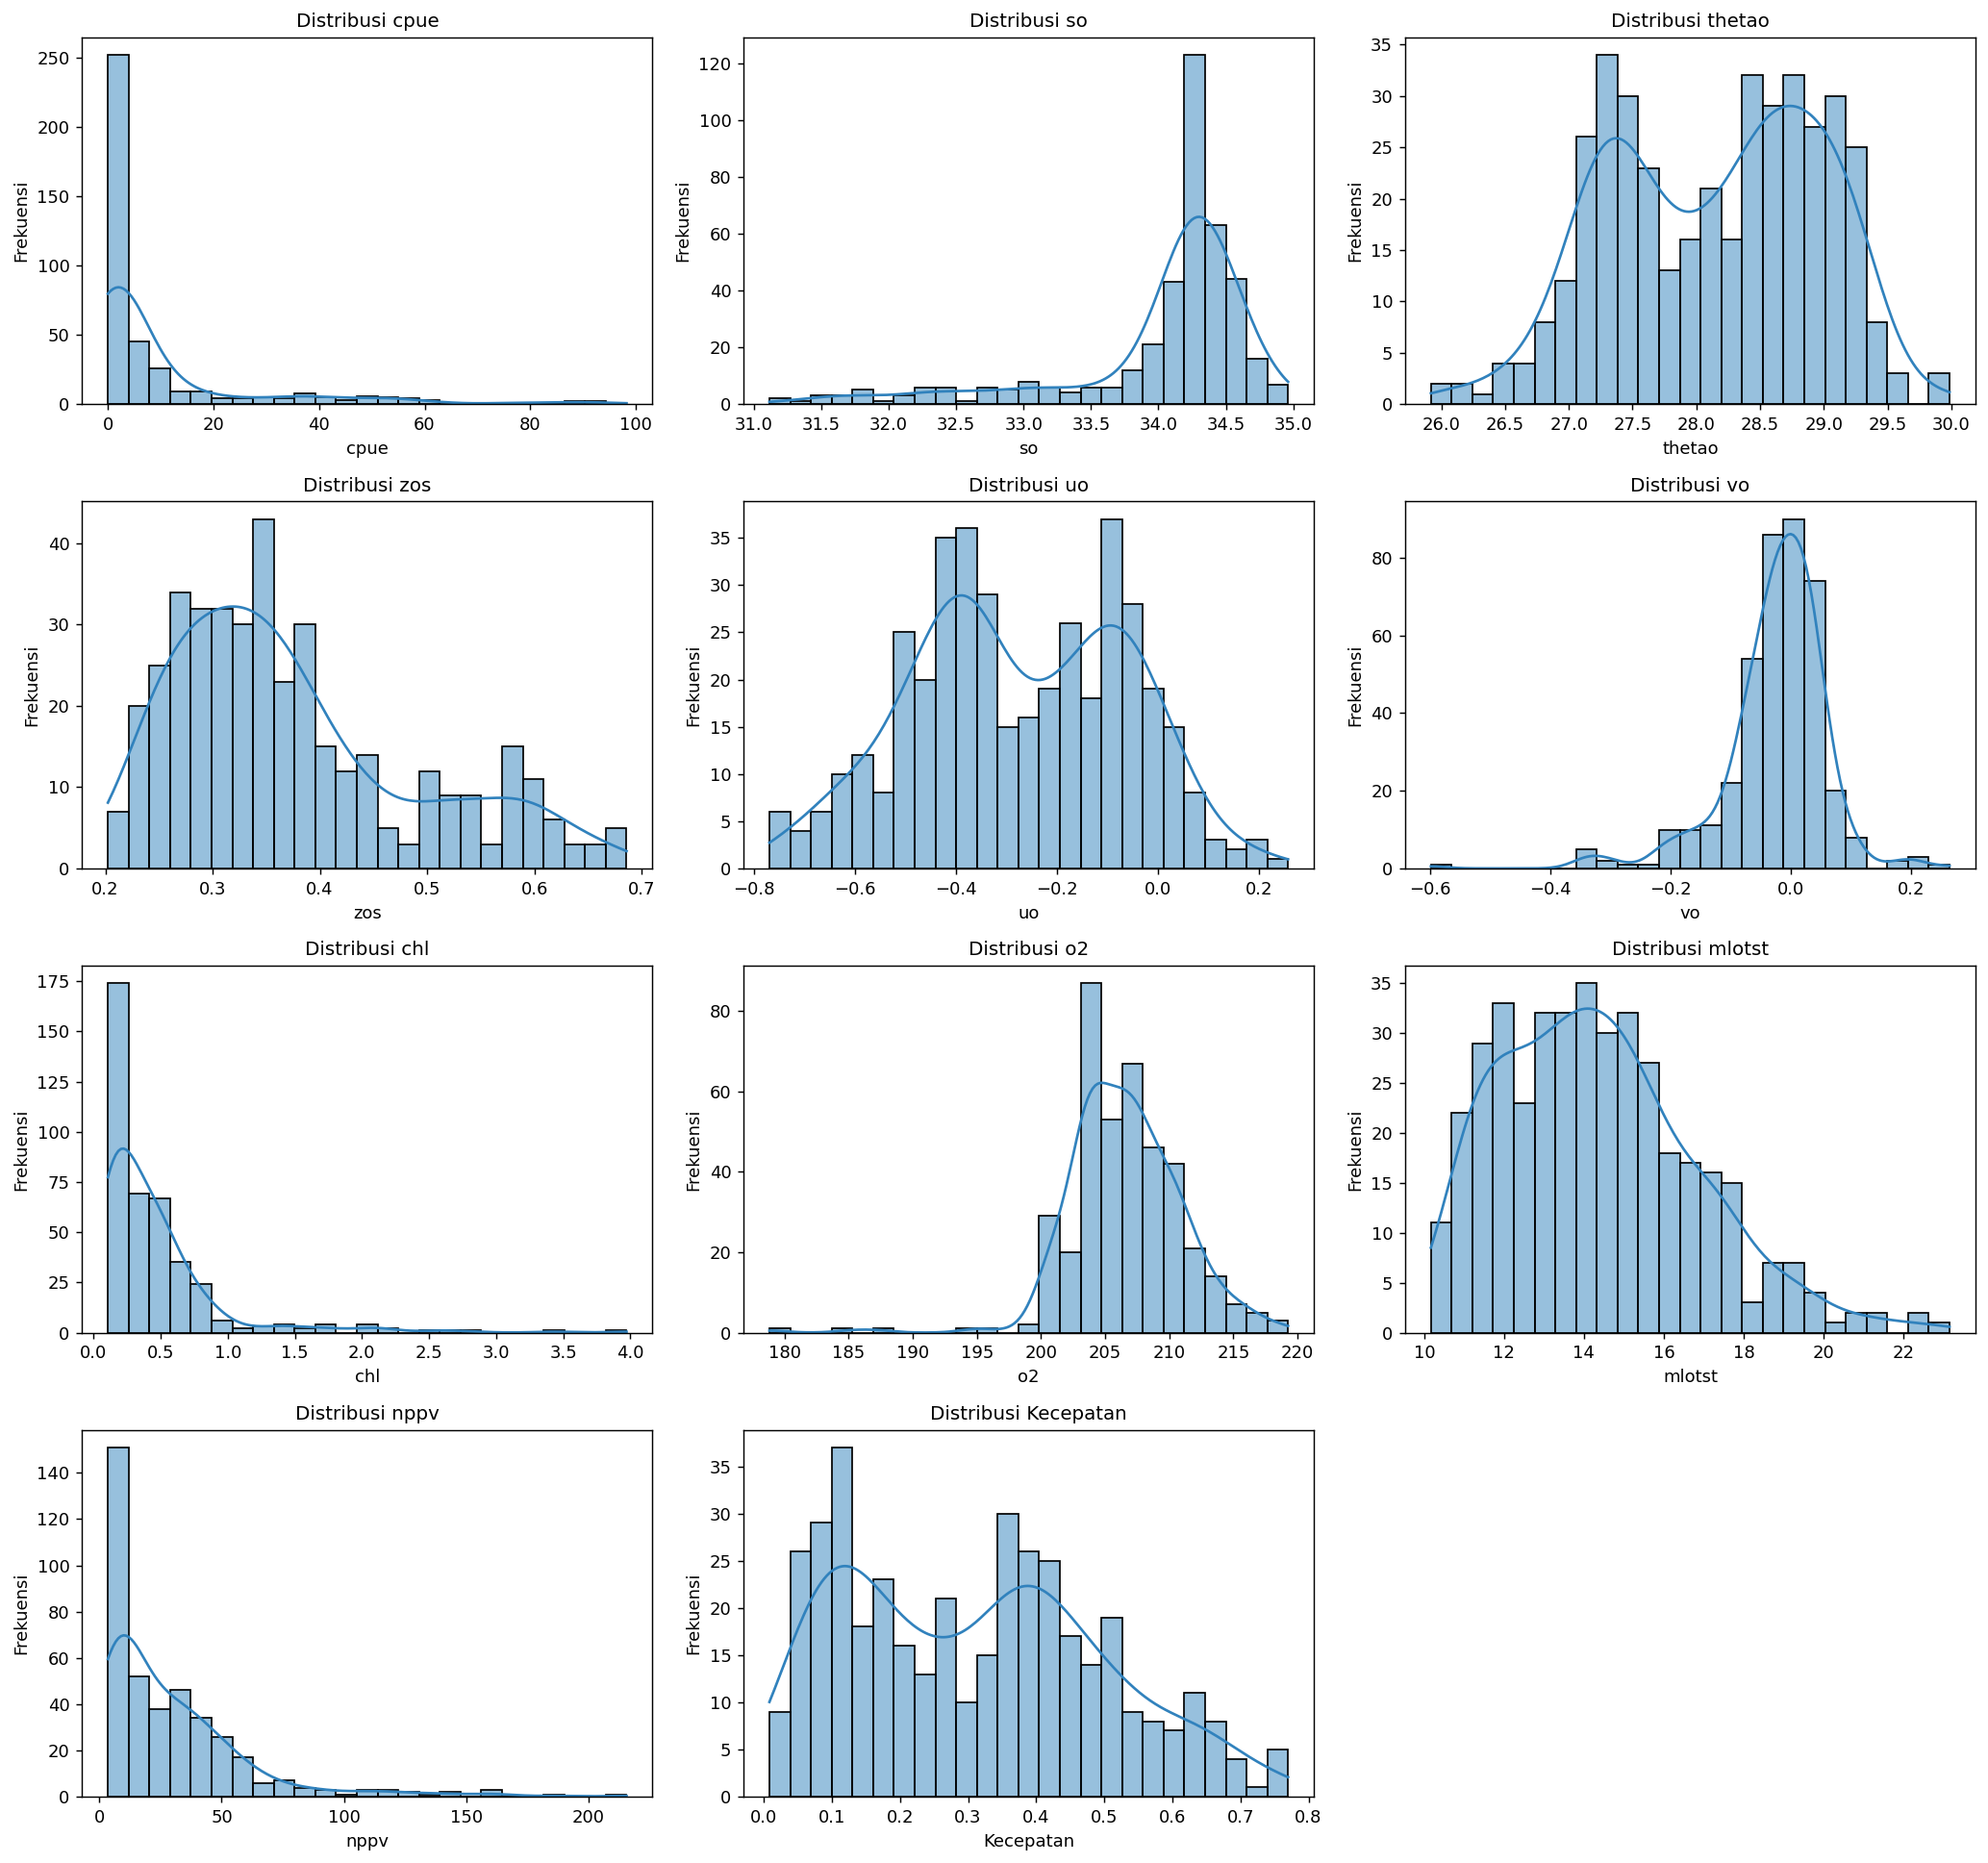

In [91]:

# ================================================================
# EKSPLORASI DATA - DISTRIBUSI CPUE DAN 10 VARIABEL X
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

VAR_X = [
    "so", "thetao", "zos", "uo", "vo",
    "chl", "o2", "mlotst", "nppv", "Kecepatan"
]

VAR_ANALISIS = ["cpue"] + VAR_X

df_eda = data_esf.copy().reset_index(drop=True)

# Pastikan seluruh kolom numerik
for kol in VAR_ANALISIS:
    df_eda[kol] = pd.to_numeric(
        df_eda[kol], errors="coerce"
    )

print("Jumlah observasi :", len(df_eda))
print("Jumlah variabel  :", len(VAR_ANALISIS))

# Statistik deskriptif
deskriptif = df_eda[VAR_ANALISIS].describe().T

deskriptif["Missing"] = (
    df_eda[VAR_ANALISIS].isna().sum()
)

deskriptif["Skewness"] = (
    df_eda[VAR_ANALISIS].skew()
)

display(deskriptif.round(4))

# Histogram
fig, axes = plt.subplots(
    4, 3,
    figsize=(16, 15),
    dpi=130
)

axes = axes.flatten()

for i, kol in enumerate(VAR_ANALISIS):
    sns.histplot(
        df_eda[kol].dropna(),
        bins=25,
        kde=True,
        color="#3182bd",
        ax=axes[i]
    )

    axes[i].set_title(
        f"Distribusi {kol}",
        fontsize=11
    )

    axes[i].set_xlabel(kol)
    axes[i].set_ylabel("Frekuensi")

for j in range(len(VAR_ANALISIS), len(axes)):
    axes[j].axis("off")

plt.tight_layout()

plt.savefig(
    "/content/HISTOGRAM_CPUE_DAN_X.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


KORELASI VARIABEL OSEANOGRAFI (X) DENGAN CPUE (Y)


,Variabel X,N,Pearson (r),p-value Pearson,Spearman (rho),p-value Spearman
0,so,401,-0.6341,0.0000,-0.3785,0.0000
1,uo,401,0.3913,0.0000,0.3680,0.0000
2,Kecepatan,401,-0.3562,0.0000,-0.3295,0.0000
3,thetao,401,0.3422,0.0000,0.3044,0.0000
4,o2,401,-0.2557,0.0000,-0.2210,0.0000
5,nppv,401,-0.1206,0.0157,-0.2000,0.0001
6,chl,401,-0.1073,0.0317,-0.1735,0.0005
7,zos,401,-0.0855,0.0873,-0.0086,0.8635
8,mlotst,401,-0.0721,0.1494,-0.1070,0.0322
9,vo,401,-0.0403,0.4213,-0.0171,0.7332


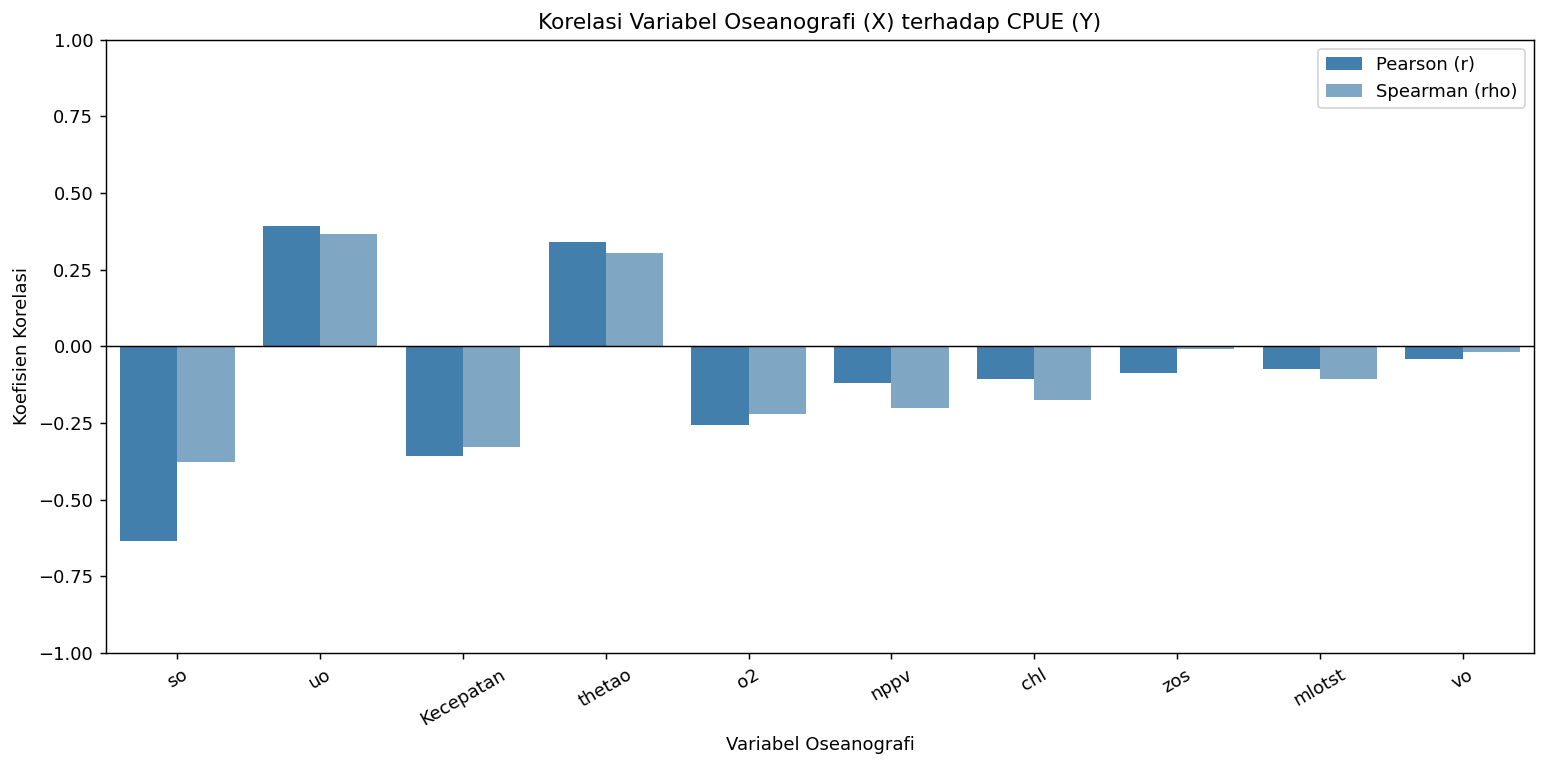

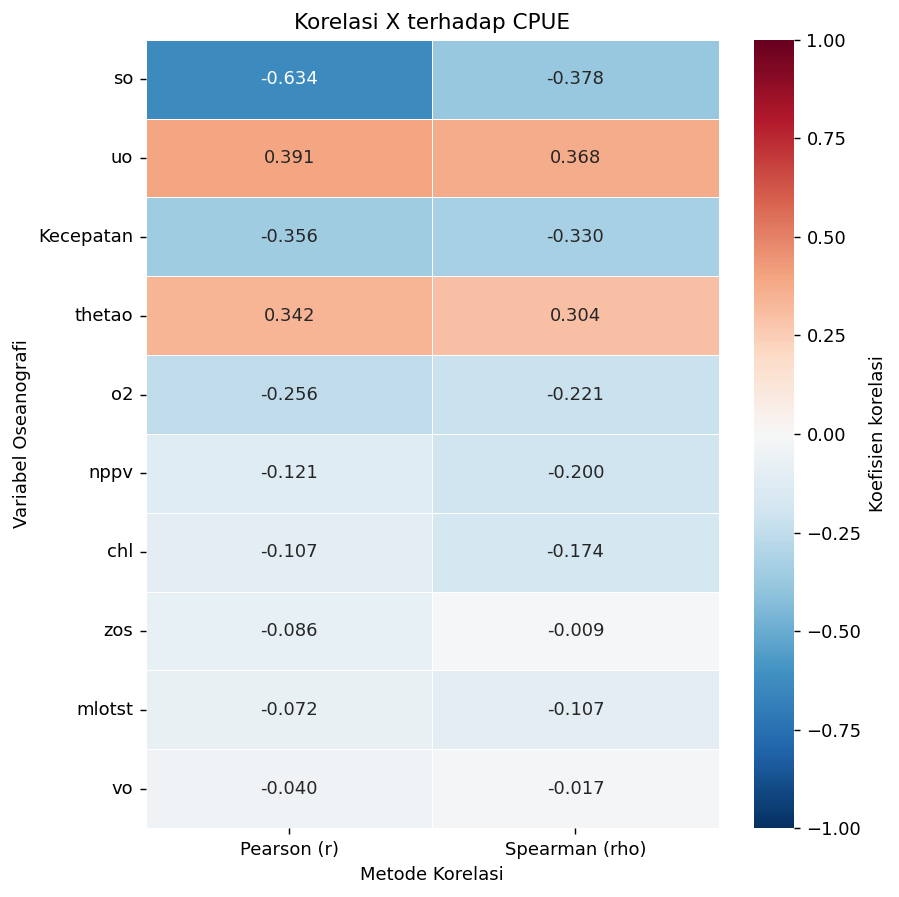

✅ Analisis korelasi X terhadap CPUE selesai.


In [96]:

# ================================================================
# KORELASI 10 VARIABEL X TERHADAP CPUE (Y)
# PEARSON DAN SPEARMAN
# Data: 401 observasi asli
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# 1. Menyiapkan data
VAR_X = [
    "so", "thetao", "zos", "uo", "vo",
    "chl", "o2", "mlotst", "nppv", "Kecepatan"
]

Y = "cpue"

df_korelasi = data_esf[[Y] + VAR_X].copy()

for kol in [Y] + VAR_X:
    df_korelasi[kol] = pd.to_numeric(
        df_korelasi[kol], errors="coerce"
    )

df_korelasi = df_korelasi.replace(
    [np.inf, -np.inf], np.nan
)

# 2. Menghitung korelasi X dengan Y
hasil = []

for x in VAR_X:

    pasangan = df_korelasi[[x, Y]].dropna()

    if (
        len(pasangan) < 3
        or pasangan[x].nunique() < 2
        or pasangan[Y].nunique() < 2
    ):
        r_pearson = np.nan
        p_pearson = np.nan
        r_spearman = np.nan
        p_spearman = np.nan
    else:
        r_pearson, p_pearson = pearsonr(
            pasangan[x], pasangan[Y]
        )

        r_spearman, p_spearman = spearmanr(
            pasangan[x], pasangan[Y]
        )

    hasil.append({
        "Variabel X": x,
        "N": len(pasangan),
        "Pearson (r)": r_pearson,
        "p-value Pearson": p_pearson,
        "Spearman (rho)": r_spearman,
        "p-value Spearman": p_spearman
    })

TABEL_KORELASI_XY = pd.DataFrame(hasil)

# Urutkan berdasarkan kekuatan korelasi Pearson
TABEL_KORELASI_XY["Abs_Pearson"] = (
    TABEL_KORELASI_XY["Pearson (r)"].abs()
)

TABEL_KORELASI_XY = (
    TABEL_KORELASI_XY
    .sort_values("Abs_Pearson", ascending=False)
    .drop(columns="Abs_Pearson")
    .reset_index(drop=True)
)

print("KORELASI VARIABEL OSEANOGRAFI (X) DENGAN CPUE (Y)")
display(TABEL_KORELASI_XY.round(4))

# 3. Grafik batang Pearson dan Spearman
plot_data = TABEL_KORELASI_XY.melt(
    id_vars="Variabel X",
    value_vars=["Pearson (r)", "Spearman (rho)"],
    var_name="Metode",
    value_name="Koefisien Korelasi"
)

plt.figure(figsize=(12, 6), dpi=130)

sns.barplot(
    data=plot_data,
    x="Variabel X",
    y="Koefisien Korelasi",
    hue="Metode",
    palette=["#3182bd", "#74a9cf"]
)

plt.axhline(0, color="black", linewidth=0.8)

plt.ylim(-1, 1)
plt.title(
    "Korelasi Variabel Oseanografi (X) terhadap CPUE (Y)"
)
plt.xlabel("Variabel Oseanografi")
plt.ylabel("Koefisien Korelasi")
plt.xticks(rotation=30)
plt.legend(title="")

plt.tight_layout()
plt.savefig(
    "/content/KORELASI_X_TERHADAP_CPUE.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 4. Heatmap khusus korelasi X dengan Y
heatmap_data = (
    TABEL_KORELASI_XY
    .set_index("Variabel X")[
        ["Pearson (r)", "Spearman (rho)"]
    ]
)

plt.figure(figsize=(7, 7), dpi=130)

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Koefisien korelasi"}
)

plt.title("Korelasi X terhadap CPUE")
plt.xlabel("Metode Korelasi")
plt.ylabel("Variabel Oseanografi")

plt.tight_layout()
plt.savefig(
    "/content/HEATMAP_KORELASI_XY.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 5. Simpan tabel
TABEL_KORELASI_XY.to_csv(
    "/content/TABEL_KORELASI_XY.csv",
    index=False
)

print("✅ Analisis korelasi X terhadap CPUE selesai.")


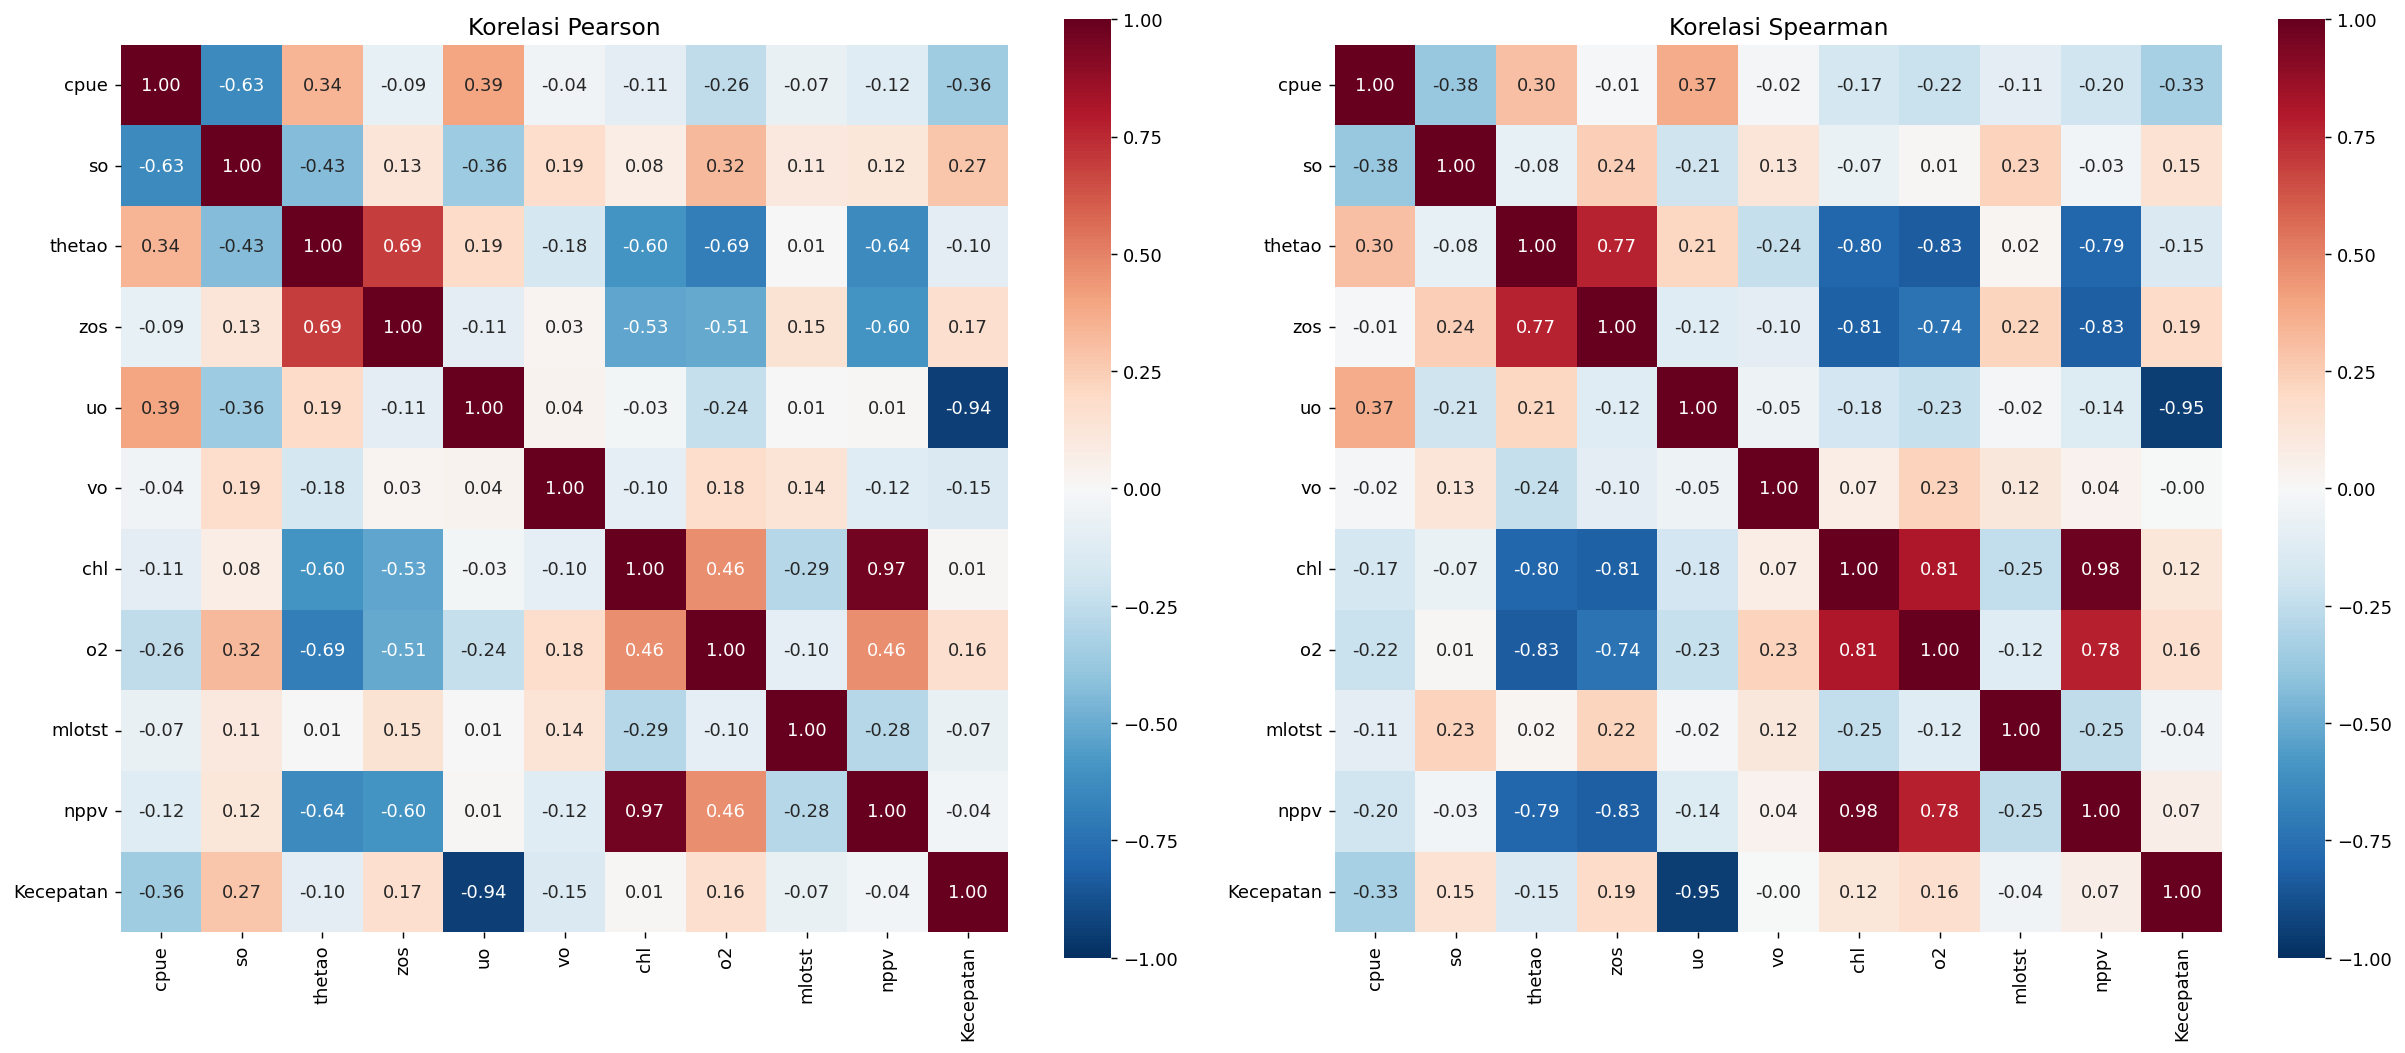

,Pearson,Spearman,Abs_Pearson
so,-0.6341,-0.3785,0.6341
uo,0.3913,0.3680,0.3913
Kecepatan,-0.3562,-0.3295,0.3562
thetao,0.3422,0.3044,0.3422
o2,-0.2557,-0.2210,0.2557
nppv,-0.1206,-0.2000,0.1206
chl,-0.1073,-0.1735,0.1073
zos,-0.0855,-0.0086,0.0855
mlotst,-0.0721,-0.1070,0.0721
vo,-0.0403,-0.0171,0.0403


In [93]:

# ================================================================
# KORELASI PEARSON DAN SPEARMAN
# ================================================================

import seaborn as sns
import matplotlib.pyplot as plt

KORELASI_PEARSON = (
    df_eda[VAR_ANALISIS].corr(method="pearson")
)

KORELASI_SPEARMAN = (
    df_eda[VAR_ANALISIS].corr(method="spearman")
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(19, 8),
    dpi=130
)

sns.heatmap(
    KORELASI_PEARSON,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[0]
)

axes[0].set_title(
    "Korelasi Pearson",
    fontsize=13
)

sns.heatmap(
    KORELASI_SPEARMAN,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[1]
)

axes[1].set_title(
    "Korelasi Spearman",
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    "/content/KORELASI_PEARSON_SPEARMAN.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Korelasi masing-masing X terhadap CPUE
REKAP_KORELASI_CPUE = pd.DataFrame({
    "Pearson": KORELASI_PEARSON.loc[VAR_X, "cpue"],
    "Spearman": KORELASI_SPEARMAN.loc[VAR_X, "cpue"]
})

REKAP_KORELASI_CPUE["Abs_Pearson"] = (
    REKAP_KORELASI_CPUE["Pearson"].abs()
)

REKAP_KORELASI_CPUE = (
    REKAP_KORELASI_CPUE
    .sort_values("Abs_Pearson", ascending=False)
)

display(REKAP_KORELASI_CPUE.round(4))


In [94]:

# ================================================================
# MULTIKOLINEARITAS - VARIANCE INFLATION FACTOR
# ================================================================

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)
from statsmodels.tools.tools import add_constant

# Hanya data lengkap untuk perhitungan VIF
X_vif = df_eda[VAR_X].replace(
    [np.inf, -np.inf], np.nan
).dropna().copy()

# Jangan hitung VIF pada kolom yang konstan
kolom_konstan = [
    kol for kol in X_vif.columns
    if X_vif[kol].nunique() <= 1
]

if kolom_konstan:
    print("Kolom konstan:", kolom_konstan)

X_vif = X_vif.drop(columns=kolom_konstan)

X_vif_const = add_constant(
    X_vif,
    has_constant="add"
)

HASIL_VIF = pd.DataFrame({
    "Variabel": X_vif.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif_const.values,
            X_vif_const.columns.get_loc(kol)
        )
        for kol in X_vif.columns
    ]
})

HASIL_VIF = HASIL_VIF.sort_values(
    "VIF",
    ascending=False
)

display(HASIL_VIF.round(3))


,Variabel,VIF
8,nppv,24.114
5,chl,21.091
9,Kecepatan,12.048
3,uo,11.992
1,thetao,6.106
2,zos,4.717
0,so,2.718
6,o2,2.159
4,vo,1.397
7,mlotst,1.252


In [95]:

# ================================================================
# DIAGNOSTIK CPUE UNTUK OBJEKTIF REG:TWEEDIE
# ================================================================

y = pd.to_numeric(
    df_eda["cpue"],
    errors="coerce"
)

n_total = len(y)
n_missing = int(y.isna().sum())
n_negatif = int((y < 0).sum())
n_nol = int((y == 0).sum())
n_positif = int((y > 0).sum())

print("DIAGNOSTIK CPUE UNTUK TWEEDIE")
print("-" * 45)
print("Jumlah observasi  :", n_total)
print("Missing CPUE      :", n_missing)
print("CPUE negatif      :", n_negatif)
print("CPUE nol          :", n_nol)
print("CPUE positif      :", n_positif)

print("\nPersentase CPUE nol:",
      f"{100 * n_nol / n_total:.2f}%")

print("\nStatistik CPUE positif:")
display(y[y > 0].describe().round(4))

if n_negatif > 0:
    print(
        "\nPERINGATAN: Ada CPUE negatif. "
        "Periksa data sebelum menggunakan reg:tweedie."
    )
elif n_missing > 0:
    print(
        "\nPERINGATAN: Ada CPUE missing. "
        "Tentukan penanganannya sebelum pemodelan."
    )
else:
    print(
        "\n✅ CPUE memenuhi syarat nonnegatif "
        "untuk objektif reg:tweedie."
    )


DIAGNOSTIK CPUE UNTUK TWEEDIE
---------------------------------------------
Jumlah observasi  : 401
Missing CPUE      : 0
CPUE negatif      : 0
CPUE nol          : 0
CPUE positif      : 401

Persentase CPUE nol: 0.00%

Statistik CPUE positif:


,cpue
count,401.0000
mean,9.7550
std,17.9121
min,0.0001
25%,0.5386
50%,2.1758
75%,8.4753
max,98.2354



✅ CPUE memenuhi syarat nonnegatif untuk objektif reg:tweedie.


In [97]:
print("=" * 45)
print("RADIUS MATRIKS PEMBOBOT SPASIAL")
print("=" * 45)

print("KNN-5         : 5 tetangga terdekat")
print(f"Distance Band : {RADIUS_DB_KM:.2f} km")
print(f"IDW           : {RADIUS_IDW_KM:.2f} km")

RADIUS MATRIKS PEMBOBOT SPASIAL
KNN-5         : 5 tetangga terdekat
Distance Band : 122.33 km
IDW           : 203.88 km


In [98]:

# ================================================================
# PEMBENTUKAN 3 MATRIKS PEMBOBOT SPASIAL (W)
# KNN-5 | DISTANCE BAND | INVERSE DISTANCE WEIGHTING
# DATA: 401 LOKASI PENGAMATAN CPUE
#
# W untuk Eigenvector Spatial Filtering (ESF)
# - Menggunakan koordinat asli
# - Jarak Haversine (km)
# - W simetris
# - Diagonal W = 0
# - Tidak distandardisasi baris
# ================================================================

import numpy as np
import pandas as pd

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.metrics.pairwise import haversine_distances

# ------------------------------------------------
# 1. MENYIAPKAN DATA ASLI
# ------------------------------------------------

df_w = data_esf.copy().reset_index(drop=True)

KOORDINAT = ["Longitude", "Latitude"]

if not set(KOORDINAT).issubset(df_w.columns):
    raise ValueError(
        "Kolom Longitude dan Latitude tidak ditemukan."
    )

for kol in KOORDINAT:
    df_w[kol] = pd.to_numeric(
        df_w[kol], errors="coerce"
    )

if df_w[KOORDINAT].isna().any().any():
    raise ValueError(
        "Ada koordinat kosong. Periksa data_esf."
    )

if df_w[KOORDINAT].duplicated().any():
    raise ValueError(
        "Ada lokasi koordinat duplikat. "
        "Periksa apakah data perlu diagregasi per grid."
    )

N = len(df_w)

if N != 401:
    print(
        f"PERHATIAN: jumlah lokasi saat ini {N}, "
        "bukan 401."
    )

print("Jumlah lokasi :", N)

# ------------------------------------------------
# 2. MENGHITUNG MATRIKS JARAK HAVERSINE
# ------------------------------------------------

# sklearn menggunakan urutan [latitude, longitude]
KOORD_RAD = np.radians(
    df_w[["Latitude", "Longitude"]].to_numpy(
        dtype=float
    )
)

R_BUMI_KM = 6371.0088

D_KM = (
    haversine_distances(KOORD_RAD)
    * R_BUMI_KM
)

# Jarak dari lokasi ke dirinya sendiri tidak
# boleh masuk dalam penentuan tetangga
np.fill_diagonal(D_KM, np.inf)

if not np.isfinite(D_KM[
    ~np.eye(N, dtype=bool)
]).all():
    raise ValueError("Ada jarak yang tidak valid.")

# ------------------------------------------------
# 3. KNN-5: LIMA TETANGGA TERDEKAT
# ------------------------------------------------

K = 5

if N <= K:
    raise ValueError("Jumlah lokasi harus lebih dari K.")

# Lima indeks tetangga terdekat setiap lokasi
IDX_KNN = np.argsort(
    D_KM, axis=1
)[:, :K]

W_knn = np.zeros(
    (N, N), dtype=np.float64
)

baris = np.repeat(np.arange(N), K)

W_knn[
    baris,
    IDX_KNN.reshape(-1)
] = 1.0

# Simetris: i-j bertetangga jika salah satu
# memilih yang lain sebagai tetangga
W_knn = np.maximum(
    W_knn,
    W_knn.T
)

np.fill_diagonal(W_knn, 0.0)

W_KNN5 = csr_matrix(W_knn)

# ------------------------------------------------
# 4. DISTANCE BAND: TETANGGA DALAM RADIUS
# ------------------------------------------------

# Radius eksploratif:
# persentil ke-90 jarak tetangga ke-5
#
# Radius ini adalah keputusan desain awal,
# bukan angka baku dari teori ESF.

JARAK_TETANGGA_KE5 = np.sort(
    D_KM, axis=1
)[:, K - 1]

RADIUS_DB_KM = float(
    np.percentile(
        JARAK_TETANGGA_KE5, 90
    )
)

W_distance = (
    D_KM <= RADIUS_DB_KM
).astype(float)

np.fill_diagonal(W_distance, 0.0)

W_DISTANCE = csr_matrix(
    W_distance
)

# ------------------------------------------------
# 5. IDW: BOBOT KEBALIKAN JARAK
# ------------------------------------------------

# Radius IDW dibuat terpisah dari KNN-5.
# Nilai 1.667 adalah faktor eksploratif,
# yang perlu dijelaskan pada metodologi.

FAKTOR_RADIUS_IDW = 1.667

RADIUS_IDW_KM = (
    FAKTOR_RADIUS_IDW * RADIUS_DB_KM
)

# Hanya pasangan lokasi di dalam radius IDW
# yang mendapat bobot 1 / jarak (km).

W_idw = np.zeros(
    (N, N), dtype=np.float64
)

MASK_IDW = (
    (D_KM <= RADIUS_IDW_KM)
    & (D_KM > 0)
    & np.isfinite(D_KM)
)

W_idw[MASK_IDW] = (
    1.0 / D_KM[MASK_IDW]
)

# Menjaga simetri numerik
W_idw = (
    W_idw + W_idw.T
) / 2.0

np.fill_diagonal(W_idw, 0.0)

W_IDW = csr_matrix(W_idw)

# ------------------------------------------------
# 6. SIMPAN SEMUA MATRIKS W
# ------------------------------------------------

W_STORE = {
    "KNN5": W_KNN5,
    "DISTANCE": W_DISTANCE,
    "IDW": W_IDW
}

# ------------------------------------------------
# 7. VALIDASI DAN RINGKASAN W
# ------------------------------------------------

rekap_w = []

for nama, W in W_STORE.items():

    A = W.toarray()

    jumlah_tetangga = np.count_nonzero(
        A, axis=1
    )

    n_komponen, label_komponen = (
        connected_components(
            W,
            directed=False
        )
    )

    rekap_w.append({
        "Matriks": nama,
        "Ukuran": f"{N} x {N}",
        "Jumlah Pasangan": int(
            np.count_nonzero(A) // 2
        ),
        "Tetangga Minimum": int(
            jumlah_tetangga.min()
        ),
        "Tetangga Rata-rata": float(
            jumlah_tetangga.mean()
        ),
        "Tetangga Maksimum": int(
            jumlah_tetangga.max()
        ),
        "Lokasi Terisolasi": int(
            (jumlah_tetangga == 0).sum()
        ),
        "Komponen Terhubung": int(
            n_komponen
        ),
        "Simetris": bool(
            np.allclose(A, A.T)
        ),
        "Diagonal Nol": bool(
            np.allclose(np.diag(A), 0)
        )
    })

REKAP_W_3JENIS = pd.DataFrame(rekap_w)

print("\nRADIUS PEMBOBOT SPASIAL")
print("-" * 45)

print(
    "Distance Band :",
    f"{RADIUS_DB_KM:.3f} km"
)

print(
    "IDW           :",
    f"{RADIUS_IDW_KM:.3f} km"
)

print("\nREKAP TIGA MATRIKS W")

display(REKAP_W_3JENIS.round(3))

# ------------------------------------------------
# 8. PERIKSA KONDISI MATRIKS
# ------------------------------------------------

for nama, W in W_STORE.items():

    A = W.toarray()

    assert A.shape == (N, N)
    assert np.allclose(A, A.T)
    assert np.allclose(np.diag(A), 0)
    assert np.all(A >= 0)

print("\n✅ TIGA MATRIKS W BERHASIL DIBENTUK")
print("✅ Semua matriks simetris")
print("✅ Semua diagonal bernilai nol")
print("✅ Koordinat asli tidak diubah")
print("✅ Siap untuk analisis spasial dan ESF")


Jumlah lokasi : 401

RADIUS PEMBOBOT SPASIAL
---------------------------------------------
Distance Band : 122.327 km
IDW           : 203.919 km

REKAP TIGA MATRIKS W


,Matriks,Ukuran,Jumlah Pasangan,Tetangga Minimum,Tetangga Rata-rata,Tetangga Maksimum,Lokasi Terisolasi,Komponen Terhubung,Simetris,Diagonal Nol
0,KNN5,401 x 401,1218,5,6.075,9,0,1,True,True
1,DISTANCE,401 x 401,1696,1,8.459,16,0,3,True,True
2,IDW,401 x 401,5090,2,25.387,42,0,1,True,True



✅ TIGA MATRIKS W BERHASIL DIBENTUK
✅ Semua matriks simetris
✅ Semua diagonal bernilai nol
✅ Koordinat asli tidak diubah
✅ Siap untuk analisis spasial dan ESF


Matriks pembobot spasial dibentuk menggunakan tiga pendekatan, yaitu K-Nearest Neighbors (KNN-5), Distance Band, dan Inverse Distance Weighting (IDW). Pada pendekatan KNN-5, hubungan spasial ditentukan berdasarkan lima tetangga terdekat. Pada pendekatan Distance Band, radius ketetanggaan ditetapkan sebesar 122,33 km berdasarkan persentil ke-90 jarak menuju tetangga terdekat kelima. Sementara itu, pendekatan IDW menggunakan radius sebesar 203,88 km dengan bobot berupa kebalikan jarak antarlokasi. Seluruh jarak dihitung menggunakan metode Haversine dan matriks pembobot dibentuk secara simetris tanpa standardisasi baris.

Jumlah observasi : 401
Permutasi        : 999
Taraf signifikansi: 0.05

HASIL UJI AUTOKORELASI SPASIAL CPUE


,Matriks W,Moran's I,E[I],Z Permutasi,p-value (2 sisi),p-value (positif),Keputusan,Pola Spasial
0,KNN5,0.59389,-0.0025,20.36962,0.001,0.001,Tolak H0,Autokorelasi positif
1,DISTANCE,0.48142,-0.0025,19.84139,0.001,0.001,Tolak H0,Autokorelasi positif
2,IDW,0.43003,-0.0025,28.91526,0.001,0.001,Tolak H0,Autokorelasi positif


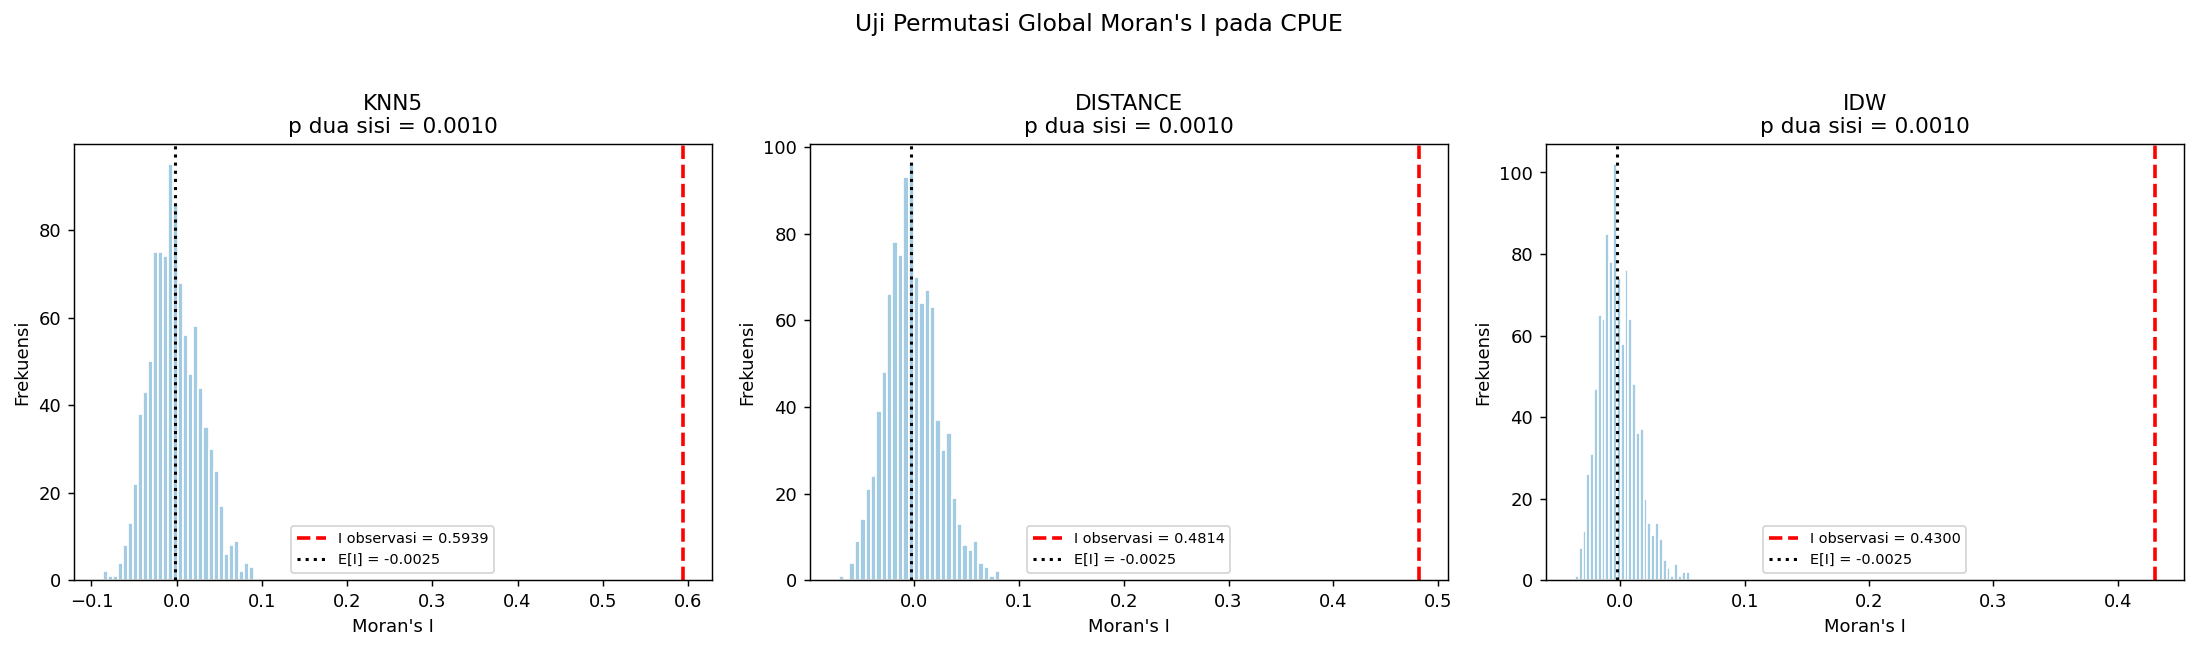


✅ UJI GLOBAL MORAN'S I SELESAI
✅ Hasil tersimpan dalam TABEL_MORAN_CPUE
✅ Ketiga W tidak diubah


In [99]:

# ================================================================
# UJI AUTOKORELASI SPASIAL GLOBAL MORAN'S I
# RESPONS : CPUE
# W       : KNN-5, DISTANCE BAND, IDW
# METODE  : UJI PERMUTASI (999 KALI)
# ALPHA   : 0.05
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix

# ------------------------------------------------
# 1. PERSIAPAN DATA
# ------------------------------------------------

ALPHA = 0.05
N_PERMUTASI = 999
SEED = 2026

# Gunakan df_w, yaitu data yang dipakai saat membentuk W.
# Urutan baris harus sama persis dengan urutan W.
if "df_w" not in globals():
    raise NameError(
        "df_w tidak ditemukan. Jalankan cell pembentukan W."
    )

if "W_STORE" not in globals():
    raise NameError(
        "W_STORE tidak ditemukan. Jalankan cell pembentukan W."
    )

# Periksa apakah data_esf telah berubah sejak W dibentuk
data_sekarang = data_esf.reset_index(drop=True)

if len(df_w) != len(data_sekarang):
    raise ValueError(
        "Jumlah baris data_esf berubah sejak W dibuat."
    )

if not np.allclose(
    df_w[["Longitude", "Latitude"]].to_numpy(),
    data_sekarang[["Longitude", "Latitude"]].to_numpy(),
    equal_nan=True
):
    raise ValueError(
        "Urutan koordinat berubah. "
        "Jangan gunakan W dengan urutan data berbeda."
    )

y = pd.to_numeric(
    df_w["cpue"], errors="coerce"
).to_numpy(dtype=float)

n = len(y)

if not np.isfinite(y).all():
    raise ValueError(
        "CPUE mengandung NaN atau infinity. "
        "Periksa data sebelum uji Moran."
    )

if np.var(y) <= 0:
    raise ValueError(
        "Variansi CPUE = 0. Moran's I tidak dapat dihitung."
    )

print("Jumlah observasi :", n)
print("Permutasi        :", N_PERMUTASI)
print("Taraf signifikansi:", ALPHA)

# ------------------------------------------------
# 2. FUNGSI MORAN'S I
# ------------------------------------------------

def hitung_moran(y, W):

    y = np.asarray(y, dtype=float)

    W = csr_matrix(W)

    n = len(y)
    S0 = float(W.sum())

    if S0 <= 0:
        raise ValueError(
            "Jumlah bobot spasial tidak boleh nol."
        )

    z = y - y.mean()

    pembilang = float(z @ (W @ z))
    penyebut = float(z @ z)

    if penyebut <= 0:
        raise ValueError(
            "Variansi respons harus positif."
        )

    I = (n / S0) * (pembilang / penyebut)

    return I

# ------------------------------------------------
# 3. UJI PERMUTASI
# ------------------------------------------------

def uji_moran_permutasi(
    y,
    W,
    n_permutasi=999,
    seed=2026
):

    rng = np.random.default_rng(seed)

    I_observasi = hitung_moran(y, W)

    I_permutasi = np.empty(
        n_permutasi, dtype=float
    )

    for b in range(n_permutasi):

        # Acak nilai CPUE antarlokasi,
        # sementara matriks W tetap.
        y_acak = rng.permutation(y)

        I_permutasi[b] = hitung_moran(
            y_acak, W
        )

    # Nilai harapan teoretis di bawah pengacakan
    E_I = -1.0 / (len(y) - 1)

    # p-value dua sisi dengan pusat E[I]
    # Koreksi +1 mencakup statistik teramati.
    ekstrem_dua_sisi = np.sum(
        np.abs(I_permutasi - E_I)
        >= np.abs(I_observasi - E_I)
    )

    p_dua_sisi = (
        ekstrem_dua_sisi + 1
    ) / (n_permutasi + 1)

    # p-value satu sisi untuk autokorelasi positif
    ekstrem_positif = np.sum(
        I_permutasi >= I_observasi
    )

    p_positif = (
        ekstrem_positif + 1
    ) / (n_permutasi + 1)

    sd_permutasi = np.std(
        I_permutasi, ddof=1
    )

    z_permutasi = (
        (I_observasi - np.mean(I_permutasi))
        / sd_permutasi
        if sd_permutasi > 0 else np.nan
    )

    return {
        "I": I_observasi,
        "E_I": E_I,
        "Rata2_Permutasi": np.mean(I_permutasi),
        "SD_Permutasi": sd_permutasi,
        "Z_Permutasi": z_permutasi,
        "P_Dua_Sisi": p_dua_sisi,
        "P_Positif": p_positif,
        "Distribusi_Permutasi": I_permutasi
    }

# ------------------------------------------------
# 4. UJI MORAN UNTUK 3 MATRIKS W
# ------------------------------------------------

HASIL_UJI_MORAN = {}
rekap_moran = []

for nama, W in W_STORE.items():

    if W.shape != (n, n):
        raise ValueError(
            f"Ukuran W {nama} tidak sesuai jumlah data."
        )

    hasil = uji_moran_permutasi(
        y=y,
        W=W,
        n_permutasi=N_PERMUTASI,
        seed=SEED
    )

    HASIL_UJI_MORAN[nama] = hasil

    p = hasil["P_Dua_Sisi"]

    keputusan = (
        "Tolak H0"
        if p < ALPHA
        else "Gagal menolak H0"
    )

    if p < ALPHA:
        pola = (
            "Autokorelasi positif"
            if hasil["I"] > hasil["E_I"]
            else "Autokorelasi negatif"
        )
    else:
        pola = "Tidak signifikan"

    rekap_moran.append({
        "Matriks W": nama,
        "Moran's I": hasil["I"],
        "E[I]": hasil["E_I"],
        "Z Permutasi": hasil["Z_Permutasi"],
        "p-value (2 sisi)": p,
        "p-value (positif)": hasil["P_Positif"],
        "Keputusan": keputusan,
        "Pola Spasial": pola
    })

TABEL_MORAN_CPUE = pd.DataFrame(
    rekap_moran
)

print("\nHASIL UJI AUTOKORELASI SPASIAL CPUE")
display(TABEL_MORAN_CPUE.round(5))

# ------------------------------------------------
# 5. VISUALISASI DISTRIBUSI PERMUTASI
# ------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 4.8),
    dpi=130
)

for ax, (nama, hasil) in zip(
    axes, HASIL_UJI_MORAN.items()
):

    distribusi = hasil["Distribusi_Permutasi"]

    ax.hist(
        distribusi,
        bins=30,
        color="#9ecae1",
        edgecolor="white",
        alpha=0.95
    )

    ax.axvline(
        hasil["I"],
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"I observasi = {hasil['I']:.4f}"
    )

    ax.axvline(
        hasil["E_I"],
        color="black",
        linestyle=":",
        linewidth=1.7,
        label=f"E[I] = {hasil['E_I']:.4f}"
    )

    ax.set_title(
        f"{nama}\np dua sisi = {hasil['P_Dua_Sisi']:.4f}"
    )

    ax.set_xlabel("Moran's I")
    ax.set_ylabel("Frekuensi")
    ax.legend(fontsize=8)

fig.suptitle(
    "Uji Permutasi Global Moran's I pada CPUE",
    fontsize=13,
    y=1.03
)

plt.tight_layout()

plt.savefig(
    "/content/UJI_MORAN_CPUE_3W.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 6. SIMPAN HASIL
# ------------------------------------------------

TABEL_MORAN_CPUE.to_csv(
    "/content/TABEL_UJI_MORAN_CPUE_3W.csv",
    index=False
)

print("\n✅ UJI GLOBAL MORAN'S I SELESAI")
print("✅ Hasil tersimpan dalam TABEL_MORAN_CPUE")
print("✅ Ketiga W tidak diubah")


### Pengujian Autokorelasi Spasial

Pengujian autokorelasi spasial terhadap produktivitas penangkapan ikan (CPUE) dilakukan menggunakan Indeks Moran Global dengan tiga matriks pembobot spasial, yaitu K-Nearest Neighbors (KNN-5), Distance Band, dan Inverse Distance Weighting (IDW). Pengujian menggunakan 999 permutasi dengan taraf signifikansi sebesar 5%.

Hasil pengujian menunjukkan nilai Indeks Moran sebesar 0,59389 untuk KNN-5, 0,48142 untuk Distance Band, dan 0,43003 untuk IDW. Ketiga matriks menghasilkan nilai p sebesar 0,001, sehingga hipotesis nol yang menyatakan tidak terdapat autokorelasi spasial ditolak.

Nilai Indeks Moran yang positif menunjukkan adanya kecenderungan pengelompokan nilai CPUE yang serupa pada lokasi-lokasi yang memiliki hubungan spasial. Dengan demikian, data CPUE menunjukkan autokorelasi spasial positif yang signifikan berdasarkan ketiga definisi matriks pembobot yang digunakan.

Temuan tersebut mendukung penggunaan pendekatan pemodelan yang mempertimbangkan struktur spasial, termasuk Eigenvector Spatial Filtering (ESF). Meskipun demikian, efektivitas masing-masing matriks pembobot dalam meningkatkan akurasi prediksi tetap perlu dievaluasi melalui pemodelan ESF-GW-XGBoost.

Jumlah observasi : 401
Matriks W        : ['KNN5', 'DISTANCE', 'IDW']

DEKOMPOSISI EIGEN: KNN5
EV positif       : 145
EV negatif       : 255
EV mendekati nol : 1
Lambda maksimum  : 6.411902

Lima eigenvalue positif terbesar:


,Eigenvector,Eigenvalue,Rasio_terhadap_maksimum
0,EV1,6.411902,1.000000
1,EV2,6.390862,0.996719
2,EV3,6.346292,0.989768
3,EV4,6.300104,0.982564
4,EV5,6.240913,0.973333



DEKOMPOSISI EIGEN: DISTANCE
EV positif       : 144
EV negatif       : 256
EV mendekati nol : 1
Lambda maksimum  : 12.179054

Lima eigenvalue positif terbesar:


,Eigenvector,Eigenvalue,Rasio_terhadap_maksimum
0,EV1,12.179054,1.000000
1,EV2,10.650044,0.874456
2,EV3,10.170507,0.835082
3,EV4,9.549177,0.784066
4,EV5,9.365323,0.768970



DEKOMPOSISI EIGEN: IDW
EV positif       : 79
EV negatif       : 321
EV mendekati nol : 1
Lambda maksimum  : 0.276381

Lima eigenvalue positif terbesar:


,Eigenvector,Eigenvalue,Rasio_terhadap_maksimum
0,EV1,0.276381,1.000000
1,EV2,0.261598,0.946512
2,EV3,0.239162,0.865336
3,EV4,0.230834,0.835202
4,EV5,0.213164,0.771267



REKAP DEKOMPOSISI EIGEN TIGA MATRIKS W


,Matriks W,Jumlah Lokasi,EV Positif,EV Negatif,EV Mendekati Nol,Lambda Positif Maks,Lambda Positif Min
0,KNN5,401,145,255,1,6.411902,0.008022
1,DISTANCE,401,144,256,1,12.179054,0.001798
2,IDW,401,79,321,1,0.276381,0.000461


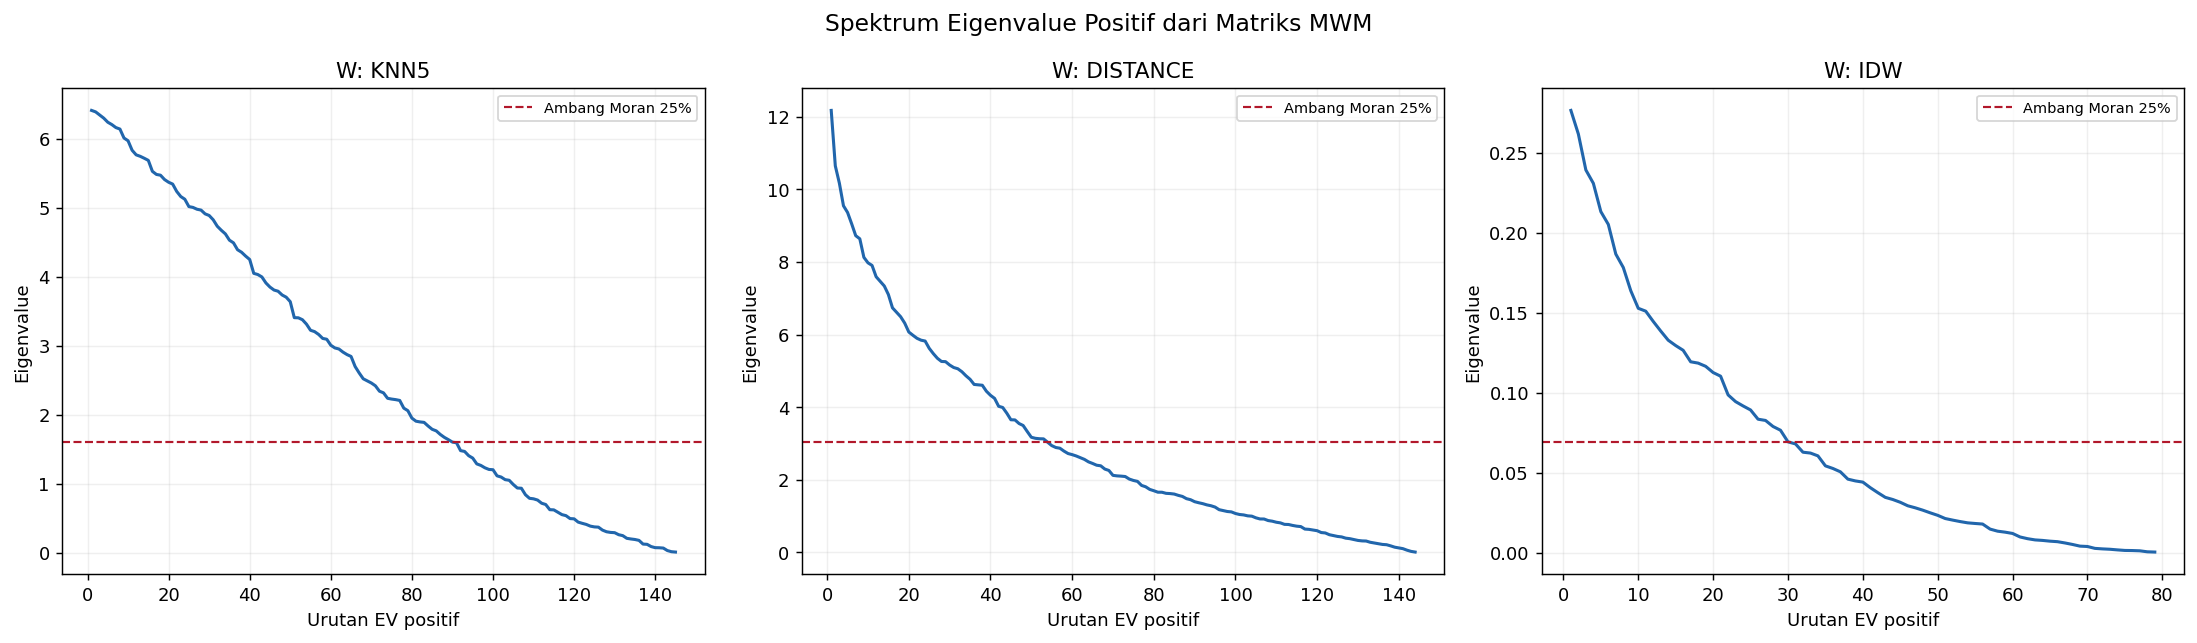


✅ DEKOMPOSISI EIGEN SELESAI
✅ Semua kandidat EV memiliki lambda positif
✅ Urutan EV sesuai koordinat asli
✅ Siap untuk empat metode seleksi EV


In [100]:

# ================================================================
# DEKOMPOSISI EIGEN MATRIKS MWM
# 3 W: KNN-5, DISTANCE BAND, IDW
#
# KANDIDAT EIGENVECTOR:
# HANYA EIGENVALUE POSITIF (lambda > 0)
#
# DATA: 401 LOKASI CPUE ASLI
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------
# 1. PEMERIKSAAN OBJEK
# ------------------------------------------------

if "df_w" not in globals():
    raise NameError("df_w belum tersedia.")

if "W_STORE" not in globals():
    raise NameError("W_STORE belum tersedia.")

N = len(df_w)

if not np.allclose(
    df_w[["Longitude", "Latitude"]].to_numpy(),
    data_esf.reset_index(drop=True)[
        ["Longitude", "Latitude"]
    ].to_numpy()
):
    raise ValueError(
        "Urutan koordinat berubah sejak W dibentuk."
    )

print("Jumlah observasi :", N)
print("Matriks W        :", list(W_STORE.keys()))

# ------------------------------------------------
# 2. MATRIKS PEMUSAT M
# ------------------------------------------------

I_N = np.eye(N)

SATU = np.ones((N, N))

M = I_N - (SATU / N)

# ------------------------------------------------
# 3. DEKOMPOSISI EIGEN UNTUK SETIAP W
# ------------------------------------------------

E_POSITIVE_STORE = {}
EIGENVALUE_STORE = {}
TABEL_EV_STORE = {}
MWM_STORE = {}

rekap_eigen = []

# Toleransi numerik agar eigenvalue mendekati nol
# tidak keliru dianggap positif.
TOL_RELATIF = 1e-10

for nama, W in W_STORE.items():

    print("\n" + "=" * 58)
    print("DEKOMPOSISI EIGEN:", nama)
    print("=" * 58)

    W_dense = W.toarray().astype(float)

    if W_dense.shape != (N, N):
        raise ValueError(
            f"Dimensi W {nama} tidak cocok."
        )

    if not np.allclose(W_dense, W_dense.T):
        raise ValueError(
            f"W {nama} tidak simetris."
        )

    # Matriks Moran terpusat
    C = M @ W_dense @ M

    # Mengatasi ketidaksimetrian numerik
    C = (C + C.T) / 2.0

    MWM_STORE[nama] = C

    # Karena C simetris, gunakan eigh
    eigenvalue, eigenvector = np.linalg.eigh(C)

    # Urutkan dari eigenvalue terbesar
    urutan = np.argsort(eigenvalue)[::-1]

    eigenvalue = eigenvalue[urutan]
    eigenvector = eigenvector[:, urutan]

    # Toleransi berdasarkan skala eigenvalue
    toleransi = (
        TOL_RELATIF *
        max(1.0, float(np.max(np.abs(eigenvalue))))
    )

    # Hanya eigenvalue positif
    mask_positif = eigenvalue > toleransi

    lambda_positif = eigenvalue[mask_positif]

    E_positif = eigenvector[:, mask_positif]

    jumlah_positif = len(lambda_positif)

    if jumlah_positif == 0:
        raise ValueError(
            f"Tidak ada EV positif pada W {nama}."
        )

    nama_ev = [
        f"EV{i+1}"
        for i in range(jumlah_positif)
    ]

    # DataFrame EV: barisnya sejajar dengan df_w
    E_df = pd.DataFrame(
        E_positif,
        columns=nama_ev,
        index=df_w.index
    )

    # Tabel nilai eigen positif
    tabel_eigen = pd.DataFrame({
        "Eigenvector": nama_ev,
        "Eigenvalue": lambda_positif,
        "Rasio_terhadap_maksimum": (
            lambda_positif / lambda_positif[0]
        )
    })

    E_POSITIVE_STORE[nama] = E_df
    EIGENVALUE_STORE[nama] = lambda_positif
    TABEL_EV_STORE[nama] = tabel_eigen

    jumlah_negatif = int(
        np.sum(eigenvalue < -toleransi)
    )

    jumlah_nol = int(
        np.sum(np.abs(eigenvalue) <= toleransi)
    )

    rekap_eigen.append({
        "Matriks W": nama,
        "Jumlah Lokasi": N,
        "EV Positif": jumlah_positif,
        "EV Negatif": jumlah_negatif,
        "EV Mendekati Nol": jumlah_nol,
        "Lambda Positif Maks": lambda_positif[0],
        "Lambda Positif Min": lambda_positif[-1]
    })

    print("EV positif       :", jumlah_positif)
    print("EV negatif       :", jumlah_negatif)
    print("EV mendekati nol :", jumlah_nol)
    print(
        "Lambda maksimum  :",
        round(lambda_positif[0], 6)
    )

    print("\nLima eigenvalue positif terbesar:")
    display(tabel_eigen.head(5).round(6))

# ------------------------------------------------
# 4. REKAP SEMUA W
# ------------------------------------------------

REKAP_EV_3W = pd.DataFrame(rekap_eigen)

print("\n" + "=" * 58)
print("REKAP DEKOMPOSISI EIGEN TIGA MATRIKS W")
print("=" * 58)

display(REKAP_EV_3W.round(6))

# ------------------------------------------------
# 5. GRAFIK EIGENVALUE POSITIF
# ------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    dpi=130
)

for ax, (nama, tabel) in zip(
    axes, TABEL_EV_STORE.items()
):

    x = np.arange(1, len(tabel) + 1)

    y = tabel["Eigenvalue"].to_numpy()

    ambang = 0.25 * y[0]

    ax.plot(
        x,
        y,
        color="#2166ac",
        linewidth=1.7
    )

    ax.axhline(
        ambang,
        color="#b2182b",
        linestyle="--",
        linewidth=1.2,
        label="Ambang Moran 25%"
    )

    ax.set_title(f"W: {nama}")
    ax.set_xlabel("Urutan EV positif")
    ax.set_ylabel("Eigenvalue")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

fig.suptitle(
    "Spektrum Eigenvalue Positif dari Matriks MWM",
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    "/content/EIGENVALUE_POSITIF_3W.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 6. SIMPAN TABEL KANDIDAT EV
# ------------------------------------------------

for nama in W_STORE.keys():

    # Simpan eigenvalue positif
    TABEL_EV_STORE[nama].to_csv(
        f"/content/EIGENVALUE_POSITIF_{nama}.csv",
        index=False
    )

    # Simpan EV positif dengan koordinat
    tabel_ev_koordinat = pd.concat(
        [
            df_w[["Longitude", "Latitude"]].copy(),
            E_POSITIVE_STORE[nama]
        ],
        axis=1
    )

    tabel_ev_koordinat.to_csv(
        f"/content/EV_POSITIF_{nama}.csv",
        index=False
    )

print("\n✅ DEKOMPOSISI EIGEN SELESAI")
print("✅ Semua kandidat EV memiliki lambda positif")
print("✅ Urutan EV sesuai koordinat asli")
print("✅ Siap untuk empat metode seleksi EV")



SELEKSI MORAN 25% - KNN5
Total eigenvector  : 401
EV positif         : 145
EV Moran 25%       : 89
Lambda maksimum    : 6.411902
Ambang lambda 25%  : 1.602975

Lima EV terpilih pertama:


,Eigenvector,Eigenvalue,Rasio_Lambda,Terpilih
0,EV1,6.411902,1.000000,True
1,EV2,6.390862,0.996719,True
2,EV3,6.346292,0.989768,True
3,EV4,6.300104,0.982564,True
4,EV5,6.240913,0.973333,True



SELEKSI MORAN 25% - DISTANCE
Total eigenvector  : 401
EV positif         : 144
EV Moran 25%       : 53
Lambda maksimum    : 12.179054
Ambang lambda 25%  : 3.044764

Lima EV terpilih pertama:


,Eigenvector,Eigenvalue,Rasio_Lambda,Terpilih
0,EV1,12.179054,1.000000,True
1,EV2,10.650044,0.874456,True
2,EV3,10.170507,0.835082,True
3,EV4,9.549177,0.784066,True
4,EV5,9.365323,0.768970,True



SELEKSI MORAN 25% - IDW
Total eigenvector  : 401
EV positif         : 79
EV Moran 25%       : 30
Lambda maksimum    : 0.276381
Ambang lambda 25%  : 0.069095

Lima EV terpilih pertama:


,Eigenvector,Eigenvalue,Rasio_Lambda,Terpilih
0,EV1,0.276381,1.000000,True
1,EV2,0.261598,0.946512,True
2,EV3,0.239162,0.865336,True
3,EV4,0.230834,0.835202,True
4,EV5,0.213164,0.771267,True


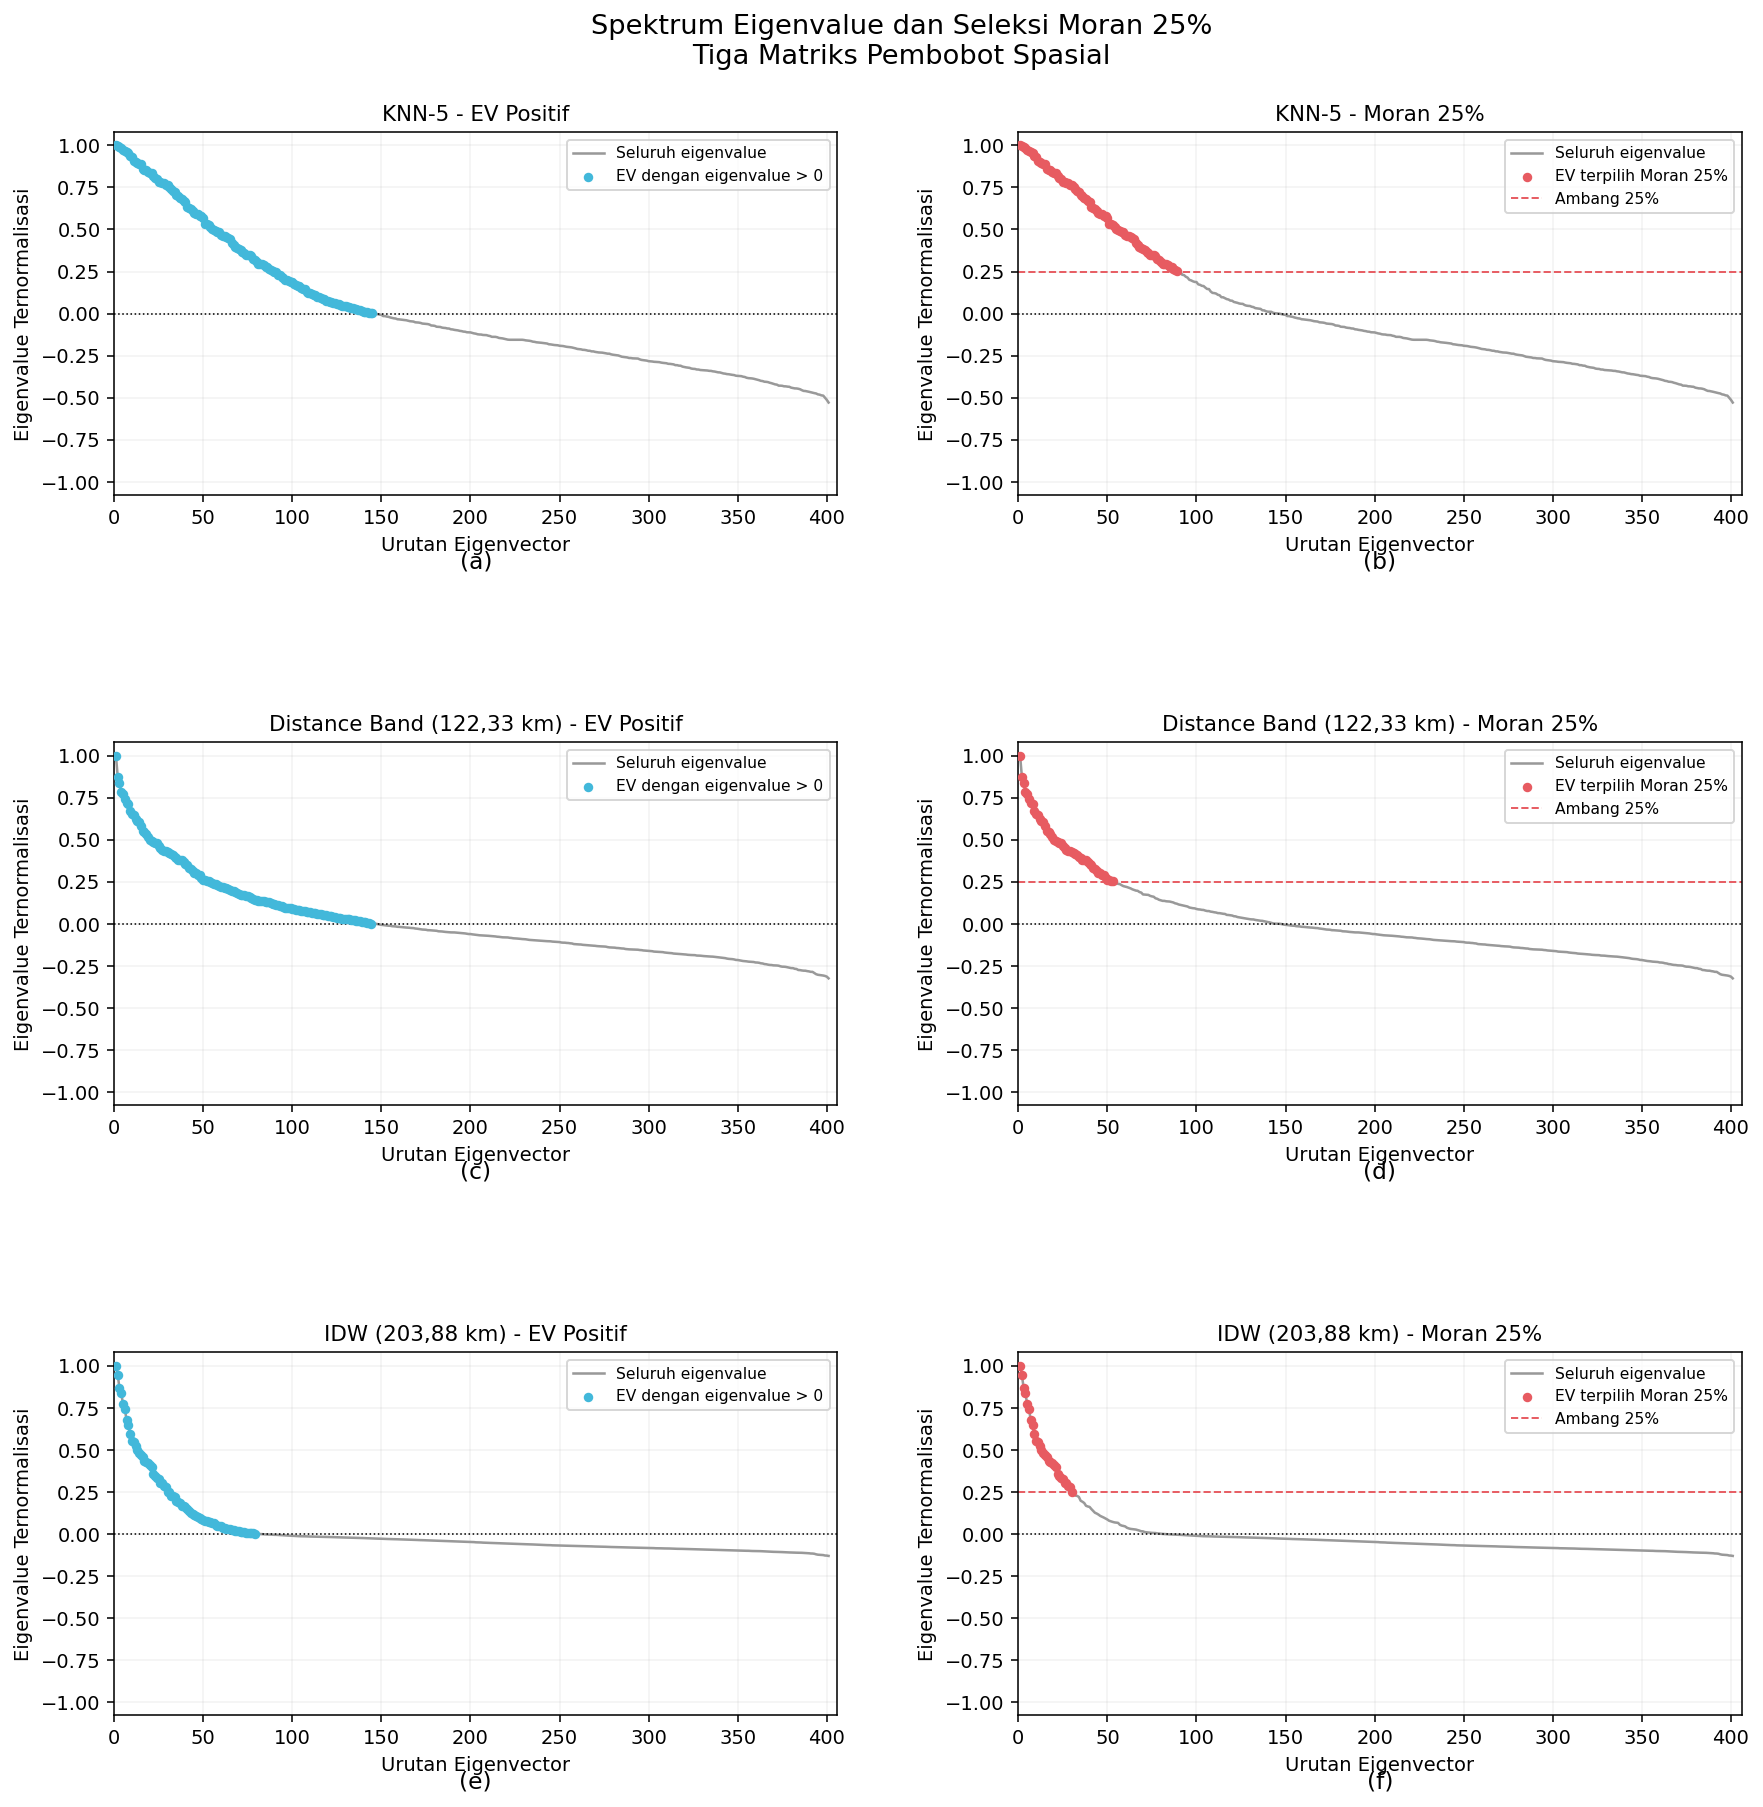


REKAP KANDIDAT DAN SELEKSI MORAN 25%


,Matriks W,Total EV,EV Positif,EV Moran 25%,EV Tidak Terpilih,Lambda Maks,Ambang Lambda 25%,Persentase Terpilih (%)
0,KNN5,401,145,89,56,6.411902,1.602975,61.379310
1,DISTANCE,401,144,53,91,12.179054,3.044764,36.805556
2,IDW,401,79,30,49,0.276381,0.069095,37.974684



✅ SELEKSI MORAN 25% SELESAI
✅ Grafik enam panel berhasil dibuat
✅ EV terpilih tersimpan dalam E_MORAN_STORE
✅ Tabel dan grafik sudah disimpan
✅ Siap lanjut seleksi LASSO


In [103]:

# ================================================================
# SELEKSI MORAN 25% + VISUALISASI EIGENVALUE 6 PANEL
# ESF - KNN5, DISTANCE BAND, IDW
#
# (a) KNN5     : seluruh EV + EV positif
# (b) KNN5     : seluruh EV + EV Moran 25%
# (c) DISTANCE : seluruh EV + EV positif
# (d) DISTANCE : seluruh EV + EV Moran 25%
# (e) IDW      : seluruh EV + EV positif
# (f) IDW      : seluruh EV + EV Moran 25%
#
# INPUT:
#   df_w
#   MWM_STORE
#   E_POSITIVE_STORE
#   EIGENVALUE_STORE
#
# OUTPUT:
#   E_MORAN_STORE
#   HASIL_MORAN_STORE
#   REKAP_MORAN_3W
#   REKAP_GRAFIK_EV
#   Grafik PNG + CSV
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------
# 1. PENGATURAN
# ------------------------------------------------

DAFTAR_W = ["KNN5", "DISTANCE", "IDW"]

NAMA_W = {
    "KNN5": "KNN-5",
    "DISTANCE": "Distance Band (122,33 km)",
    "IDW": "IDW (203,88 km)"
}

AMBANG_MORAN = 0.25

WARNA_SEMUA = "#999999"
WARNA_POSITIF = "#42b8da"
WARNA_MORAN = "#e75b61"

TOL_RELATIF = 1e-10

# ------------------------------------------------
# 2. CEK HASIL TAHAP SEBELUMNYA
# ------------------------------------------------

OBJEK_WAJIB = [
    "df_w",
    "MWM_STORE",
    "E_POSITIVE_STORE",
    "EIGENVALUE_STORE"
]

for objek in OBJEK_WAJIB:
    if objek not in globals():
        raise NameError(
            f"Objek {objek} belum tersedia. "
            "Jalankan dekomposisi eigen terlebih dahulu."
        )

N = len(df_w)

# ------------------------------------------------
# 3. SIAPKAN PENYIMPANAN HASIL
# ------------------------------------------------

E_MORAN_STORE = {}
HASIL_MORAN_STORE = {}

rekap_moran = []

# Grafik 3 baris x 2 kolom
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(15, 13),
    dpi=140
)

# ------------------------------------------------
# 4. PROSES TIAP MATRIKS W
# ------------------------------------------------

for i, nama in enumerate(DAFTAR_W):

    print("\n" + "=" * 60)
    print(f"SELEKSI MORAN 25% - {nama}")
    print("=" * 60)

    # --------------------------------------------
    # A. KANDIDAT EV POSITIF DARI TAHAP SEBELUMNYA
    # --------------------------------------------

    E_kandidat = E_POSITIVE_STORE[nama].copy()

    eigen_positif = np.asarray(
        EIGENVALUE_STORE[nama],
        dtype=float
    )

    if len(E_kandidat) != N:
        raise ValueError(
            f"Jumlah baris EV {nama} tidak sesuai."
        )

    if E_kandidat.shape[1] != len(eigen_positif):
        raise ValueError(
            f"Jumlah EV dan eigenvalue {nama} "
            "tidak sesuai."
        )

    if not E_kandidat.index.equals(df_w.index):
        raise ValueError(
            f"Indeks EV {nama} tidak sama "
            "dengan df_w."
        )

    # --------------------------------------------
    # B. SELEKSI MORAN 25%
    # --------------------------------------------

    lambda_maks = float(
        eigen_positif.max()
    )

    if lambda_maks <= 0:
        raise ValueError(
            f"Tidak ada eigenvalue positif pada {nama}."
        )

    batas_moran = (
        AMBANG_MORAN * lambda_maks
    )

    rasio = (
        eigen_positif / lambda_maks
    )

    mask_terpilih = (
        rasio >= AMBANG_MORAN
    )

    ev_terpilih = (
        E_kandidat.columns[mask_terpilih].tolist()
    )

    E_terpilih = E_kandidat.loc[
        :, ev_terpilih
    ].copy()

    E_MORAN_STORE[nama] = E_terpilih

    # Detail semua kandidat
    tabel = pd.DataFrame({
        "Eigenvector": E_kandidat.columns,
        "Eigenvalue": eigen_positif,
        "Rasio_Lambda": rasio,
        "Terpilih": mask_terpilih
    })

    HASIL_MORAN_STORE[nama] = tabel

    # --------------------------------------------
    # C. SELURUH EIGENVALUE UNTUK GRAFIK
    # --------------------------------------------

    # Gunakan MWM yang SUDAH dibentuk sebelumnya.
    # eigvalsh hanya menghitung eigenvalue, bukan
    # menghitung ulang W atau EV kandidat.
    C = MWM_STORE[nama]

    eigen_semua = np.linalg.eigvalsh(C)[::-1]

    skala_plot = float(
        np.max(np.abs(eigen_semua))
    )

    if skala_plot <= 0:
        raise ValueError(
            f"Eigenvalue {nama} seluruhnya nol."
        )

    eigen_plot = (
        eigen_semua / skala_plot
    )

    urutan = np.arange(
        1,
        len(eigen_semua) + 1
    )

    toleransi = (
        TOL_RELATIF *
        max(1.0, skala_plot)
    )

    mask_positif_plot = (
        eigen_semua > toleransi
    )

    mask_moran_plot = (
        mask_positif_plot &
        (eigen_semua >= batas_moran - 1e-12)
    )

    # Pastikan grafik sesuai seleksi yang disimpan
    if mask_positif_plot.sum() != len(eigen_positif):
        raise ValueError(
            f"Jumlah EV positif berbeda pada {nama}."
        )

    if mask_moran_plot.sum() != E_terpilih.shape[1]:
        raise ValueError(
            f"Jumlah EV Moran pada grafik "
            f"berbeda dengan data terpilih: {nama}."
        )

    # --------------------------------------------
    # D. GRAFIK KIRI: SEMUA EV + EV POSITIF
    # --------------------------------------------

    ax = axes[i, 0]

    ax.plot(
        urutan,
        eigen_plot,
        color=WARNA_SEMUA,
        linewidth=1.3,
        label="Seluruh eigenvalue"
    )

    ax.scatter(
        urutan[mask_positif_plot],
        eigen_plot[mask_positif_plot],
        color=WARNA_POSITIF,
        s=15,
        zorder=3,
        label="EV dengan eigenvalue > 0"
    )

    ax.axhline(
        0,
        color="black",
        linestyle=":",
        linewidth=0.8
    )

    ax.set_title(
        f"{NAMA_W[nama]} - EV Positif",
        fontsize=11
    )

    ax.set_xlabel("Urutan Eigenvector")
    ax.set_ylabel("Eigenvalue Ternormalisasi")

    ax.set_xlim(
        0, len(eigen_semua) + 5
    )

    ax.set_ylim(-1.08, 1.08)

    ax.legend(fontsize=8)
    ax.grid(alpha=0.15)

    ax.text(
        0.5, -0.20,
        f"({chr(97 + 2*i)})",
        transform=ax.transAxes,
        ha="center",
        fontsize=12
    )

    # --------------------------------------------
    # E. GRAFIK KANAN: SEMUA EV + MORAN 25%
    # --------------------------------------------

    ax = axes[i, 1]

    ax.plot(
        urutan,
        eigen_plot,
        color=WARNA_SEMUA,
        linewidth=1.3,
        label="Seluruh eigenvalue"
    )

    ax.scatter(
        urutan[mask_moran_plot],
        eigen_plot[mask_moran_plot],
        color=WARNA_MORAN,
        s=15,
        zorder=3,
        label="EV terpilih Moran 25%"
    )

    ax.axhline(
        0,
        color="black",
        linestyle=":",
        linewidth=0.8
    )

    ax.axhline(
        batas_moran / skala_plot,
        color=WARNA_MORAN,
        linestyle="--",
        linewidth=1,
        label="Ambang 25%"
    )

    ax.set_title(
        f"{NAMA_W[nama]} - Moran 25%",
        fontsize=11
    )

    ax.set_xlabel("Urutan Eigenvector")
    ax.set_ylabel("Eigenvalue Ternormalisasi")

    ax.set_xlim(
        0, len(eigen_semua) + 5
    )

    ax.set_ylim(-1.08, 1.08)

    ax.legend(fontsize=8)
    ax.grid(alpha=0.15)

    ax.text(
        0.5, -0.20,
        f"({chr(98 + 2*i)})",
        transform=ax.transAxes,
        ha="center",
        fontsize=12
    )

    # --------------------------------------------
    # F. REKAP HASIL
    # --------------------------------------------

    jumlah_kandidat = (
        E_kandidat.shape[1]
    )

    jumlah_terpilih = (
        E_terpilih.shape[1]
    )

    rekap_moran.append({
        "Matriks W": nama,
        "Total EV": len(eigen_semua),
        "EV Positif": jumlah_kandidat,
        "EV Moran 25%": jumlah_terpilih,
        "EV Tidak Terpilih": (
            jumlah_kandidat - jumlah_terpilih
        ),
        "Lambda Maks": lambda_maks,
        "Ambang Lambda 25%": batas_moran,
        "Persentase Terpilih (%)": (
            100 * jumlah_terpilih / jumlah_kandidat
        )
    })

    print("Total eigenvector  :", len(eigen_semua))
    print("EV positif         :", jumlah_kandidat)
    print("EV Moran 25%       :", jumlah_terpilih)

    print(
        "Lambda maksimum    :",
        round(lambda_maks, 6)
    )

    print(
        "Ambang lambda 25%  :",
        round(batas_moran, 6)
    )

    print("\nLima EV terpilih pertama:")
    display(
        tabel.loc[tabel["Terpilih"]]
        .head(5)
        .round(6)
    )

    # --------------------------------------------
    # G. SIMPAN CSV PER MATRIKS
    # --------------------------------------------

    tabel.to_csv(
        f"/content/SELEKSI_MORAN_{nama}.csv",
        index=False
    )

    data_ev = pd.concat(
        [
            df_w[[
                "Longitude",
                "Latitude"
            ]].copy(),
            E_terpilih
        ],
        axis=1
    )

    data_ev.to_csv(
        f"/content/EV_MORAN_{nama}.csv",
        index=False
    )

# ------------------------------------------------
# 5. TAMPILKAN GRAFIK 6 PANEL
# ------------------------------------------------

fig.suptitle(
    "Spektrum Eigenvalue dan Seleksi Moran 25%\n"
    "Tiga Matriks Pembobot Spasial",
    fontsize=14,
    y=0.995
)

plt.subplots_adjust(
    hspace=0.68,
    wspace=0.25,
    top=0.93,
    bottom=0.06
)

plt.savefig(
    "/content/GRAFIK_EIGENVALUE_DAN_MORAN_3W.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 6. TABEL REKAP AKHIR
# ------------------------------------------------

REKAP_MORAN_3W = pd.DataFrame(
    rekap_moran
)

# Nama lain agar kompatibel dengan cell sebelumnya
REKAP_GRAFIK_EV = REKAP_MORAN_3W.copy()

print("\n" + "=" * 65)
print("REKAP KANDIDAT DAN SELEKSI MORAN 25%")
print("=" * 65)

display(
    REKAP_MORAN_3W.round(6)
)

REKAP_MORAN_3W.to_csv(
    "/content/REKAP_MORAN_3W.csv",
    index=False
)

# ------------------------------------------------
# 7. VALIDASI TERAKHIR
# ------------------------------------------------

for nama in DAFTAR_W:

    assert len(E_MORAN_STORE[nama]) == N

    assert E_MORAN_STORE[nama].index.equals(
        df_w.index
    )

    assert (
        HASIL_MORAN_STORE[nama]
        .loc[
            HASIL_MORAN_STORE[nama]["Terpilih"],
            "Rasio_Lambda"
        ]
        .ge(AMBANG_MORAN - 1e-12)
        .all()
    )

print("\n✅ SELEKSI MORAN 25% SELESAI")
print("✅ Grafik enam panel berhasil dibuat")
print("✅ EV terpilih tersimpan dalam E_MORAN_STORE")
print("✅ Tabel dan grafik sudah disimpan")
print("✅ Siap lanjut seleksi LASSO")



SELEKSI LASSO - KNN5
EV positif         : 145
EV terpilih LASSO  : 40
Alpha terbaik      : 0.67837364
MSE CV             : 169.760494

EV terpilih (maksimal 10 pertama):


,Eigenvector,Eigenvalue,Koefisien_LASSO,Abs_Koefisien,Terpilih
0,EV1,6.411902,-0.907262,0.907262,True
1,EV2,6.390862,9.201111,9.201111,True
2,EV3,6.346292,0.218604,0.218604,True
3,EV4,6.300104,-1.347628,1.347628,True
4,EV5,6.240913,-0.963031,0.963031,True
5,EV6,6.206448,-2.117426,2.117426,True
6,EV7,6.163060,-5.817085,5.817085,True
7,EV8,6.141300,3.095145,3.095145,True
13,EV14,5.717971,1.671904,1.671904,True
14,EV15,5.687323,-0.239637,0.239637,True



SELEKSI LASSO - DISTANCE
EV positif         : 144
EV terpilih LASSO  : 56
Alpha terbaik      : 0.5590974
MSE CV             : 193.438665

EV terpilih (maksimal 10 pertama):


,Eigenvector,Eigenvalue,Koefisien_LASSO,Abs_Koefisien,Terpilih
0,EV1,12.179054,1.178588,1.178588,True
1,EV2,10.650044,0.336423,0.336423,True
4,EV5,9.365323,-1.340150,1.340150,True
6,EV7,8.725375,-3.021746,3.021746,True
7,EV8,8.639161,0.428648,0.428648,True
8,EV9,8.127340,-7.583309,7.583309,True
9,EV10,7.976648,2.532172,2.532172,True
11,EV12,7.593008,-0.495770,0.495770,True
12,EV13,7.466759,-2.376227,2.376227,True
14,EV15,7.102268,0.337085,0.337085,True



SELEKSI LASSO - IDW
EV positif         : 79
EV terpilih LASSO  : 40
Alpha terbaik      : 0.44725149
MSE CV             : 170.317487

EV terpilih (maksimal 10 pertama):


,Eigenvector,Eigenvalue,Koefisien_LASSO,Abs_Koefisien,Terpilih
0,EV1,0.276381,-0.667670,0.667670,True
4,EV5,0.213164,-7.052409,7.052409,True
5,EV6,0.205151,-4.219787,4.219787,True
6,EV7,0.186617,5.156519,5.156519,True
7,EV8,0.178229,0.113026,0.113026,True
8,EV9,0.163722,-0.293653,0.293653,True
14,EV15,0.129462,1.056915,1.056915,True
15,EV16,0.126501,-1.484442,1.484442,True
16,EV17,0.119335,5.390345,5.390345,True
18,EV19,0.116507,-2.198705,2.198705,True


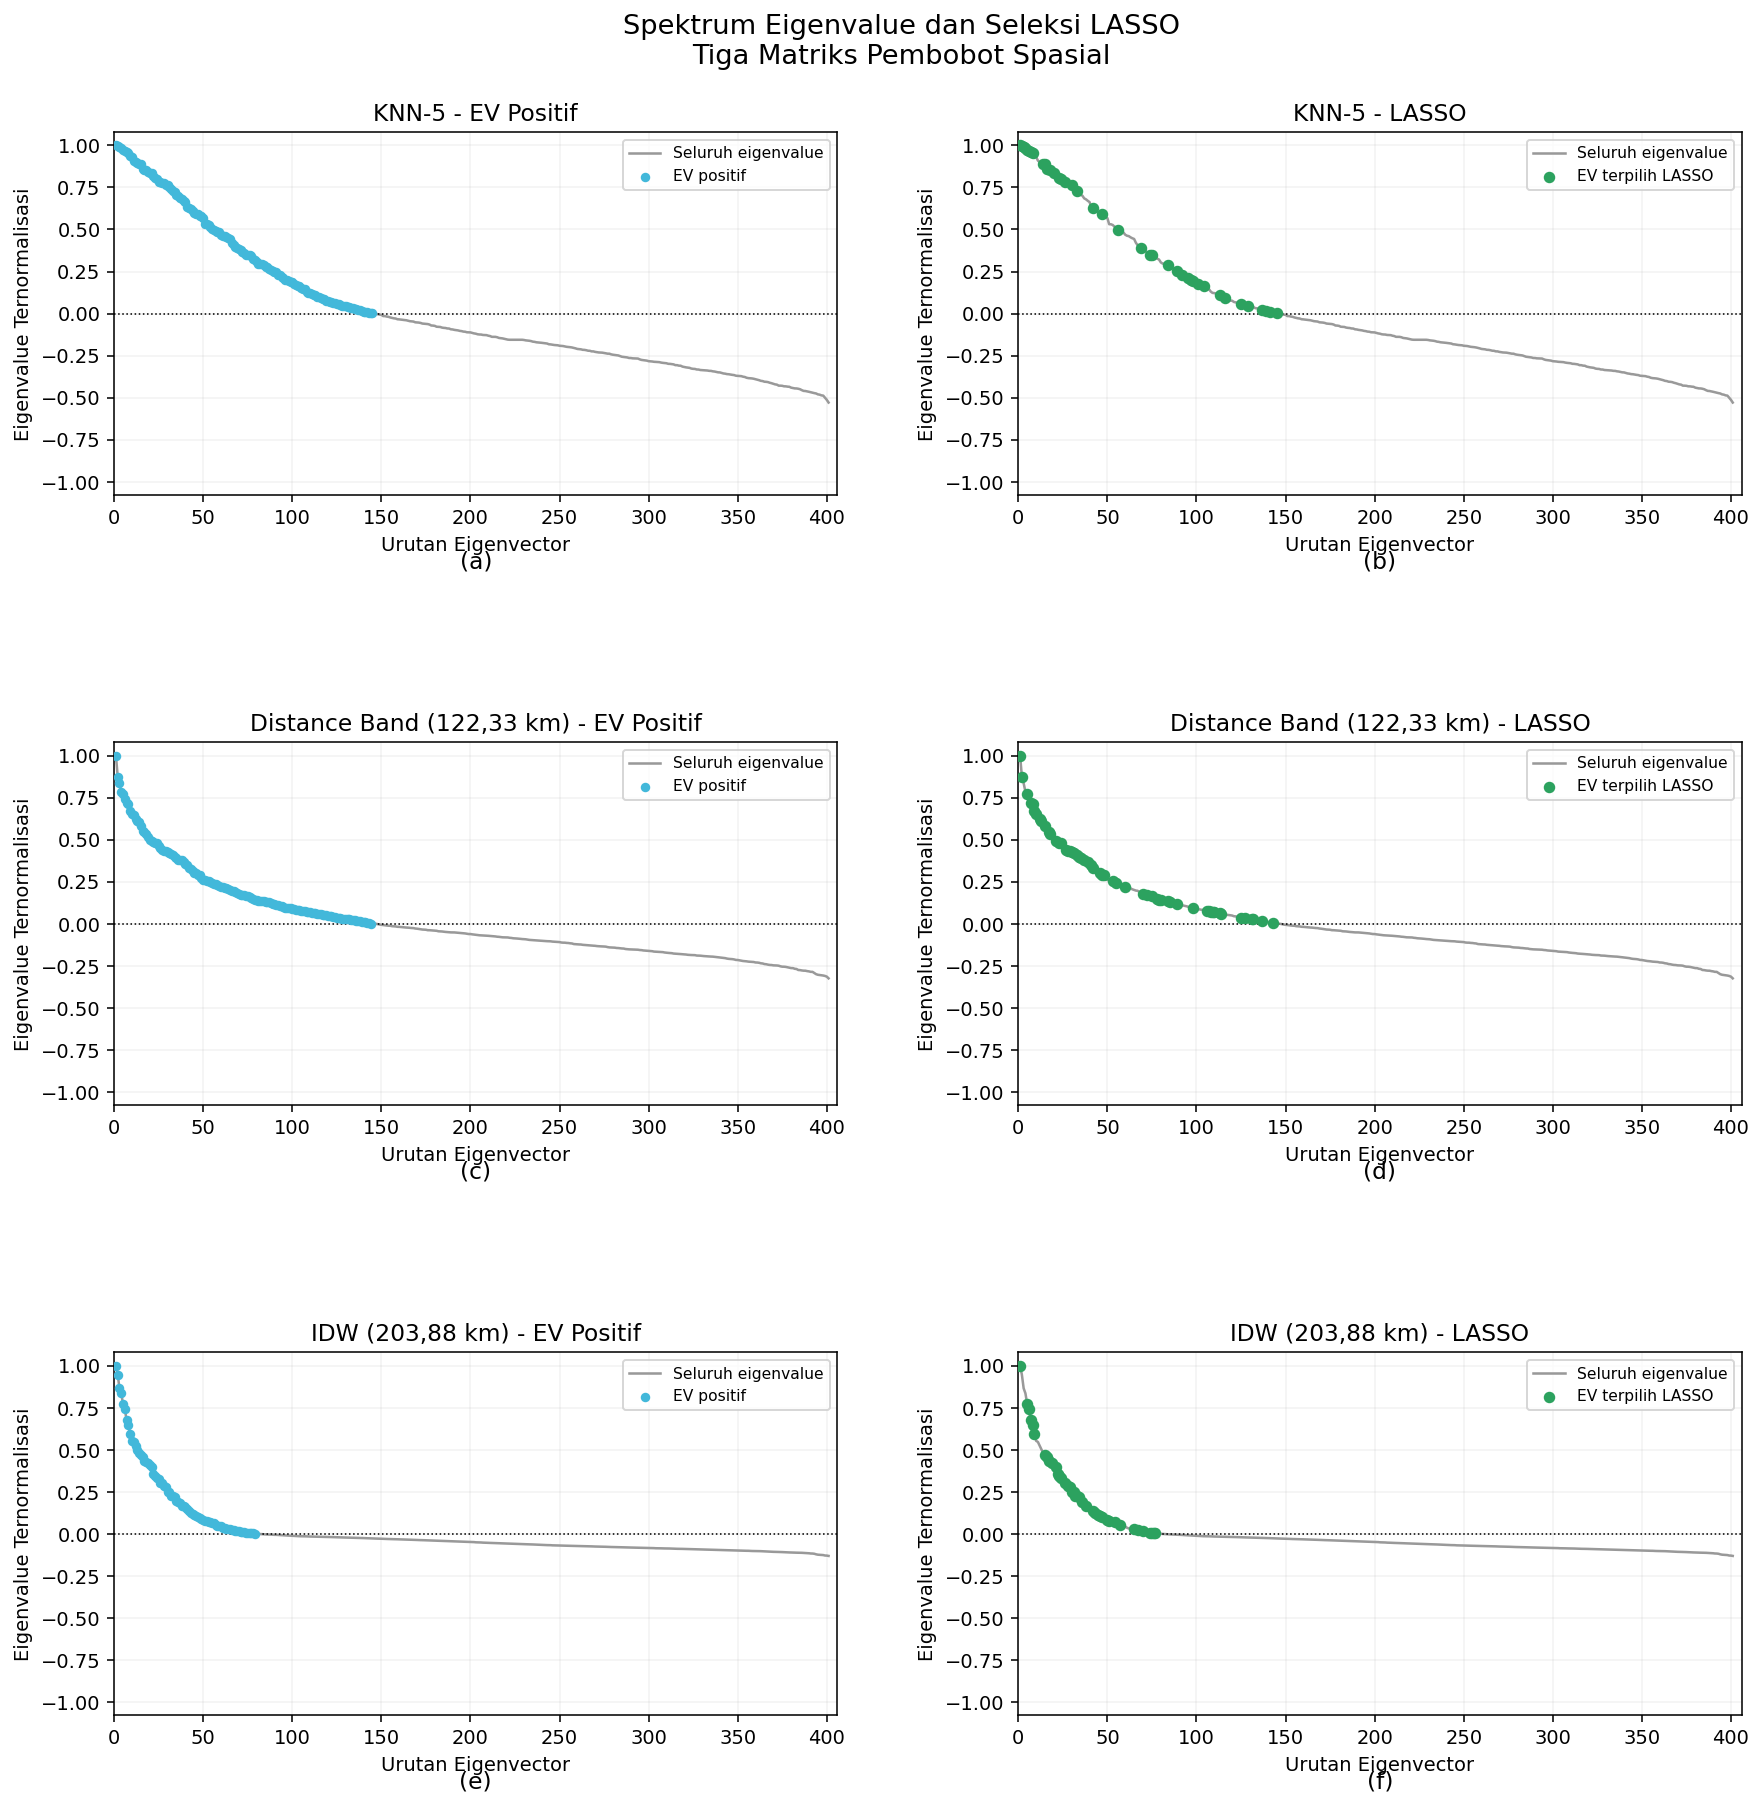


REKAP SELEKSI LASSO - TIGA MATRIKS W


,Matriks W,EV Positif,EV Terpilih LASSO,EV Tidak Terpilih,Alpha Terbaik,MSE CV,Persentase Terpilih (%)
0,KNN5,145,40,105,0.678374,169.760494,27.586207
1,DISTANCE,144,56,88,0.559097,193.438665,38.888889
2,IDW,79,40,39,0.447251,170.317487,50.632911



✅ SELEKSI LASSO SELESAI
✅ Grafik enam panel berhasil dibuat
✅ EV terpilih disimpan dalam E_LASSO_STORE
✅ Tabel dan grafik sudah disimpan
✅ Siap lanjut ke Stepwise Forward BIC


In [104]:

# ================================================================
# SELEKSI EIGENVECTOR LASSO + GRAFIK 6 PANEL
# KNN-5 | DISTANCE BAND | IDW
#
# KANDIDAT : Seluruh eigenvector dengan lambda > 0
# RESPONS  : CPUE
# SELEKSI  : Koefisien LASSO tidak nol
# TUNING   : Alpha melalui Random 5-Fold CV
#
# CATATAN:
# Ini adalah seleksi ESF pada seluruh 401 data,
# sesuai alur eksploratif yang dipilih.
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, KFold

# ------------------------------------------------
# 1. PENGATURAN
# ------------------------------------------------

DAFTAR_W = ["KNN5", "DISTANCE", "IDW"]

NAMA_W = {
    "KNN5": "KNN-5",
    "DISTANCE": "Distance Band (122,33 km)",
    "IDW": "IDW (203,88 km)"
}

SEED = 2026
N_FOLD_LASSO = 5

WARNA_SEMUA = "#999999"
WARNA_POSITIF = "#42b8da"
WARNA_LASSO = "#2ca25f"

# ------------------------------------------------
# 2. CEK OBJEK
# ------------------------------------------------

for objek in [
    "df_w",
    "E_POSITIVE_STORE",
    "EIGENVALUE_STORE",
    "MWM_STORE"
]:
    if objek not in globals():
        raise NameError(
            f"Objek {objek} belum tersedia."
        )

Y = pd.to_numeric(
    df_w["cpue"],
    errors="coerce"
).to_numpy(dtype=float)

if not np.isfinite(Y).all():
    raise ValueError(
        "CPUE mengandung nilai kosong atau infinity."
    )

if np.std(Y) == 0:
    raise ValueError("Variansi CPUE adalah nol.")

N = len(df_w)

CV_LASSO = KFold(
    n_splits=N_FOLD_LASSO,
    shuffle=True,
    random_state=SEED
)

# ------------------------------------------------
# 3. TEMPAT PENYIMPANAN
# ------------------------------------------------

E_LASSO_STORE = {}
HASIL_LASSO_STORE = {}
MODEL_LASSO_STORE = {}

rekap_lasso = []

fig, axes = plt.subplots(
    3, 2,
    figsize=(15, 13),
    dpi=140
)

# ------------------------------------------------
# 4. SELEKSI UNTUK SETIAP W
# ------------------------------------------------

for i, nama in enumerate(DAFTAR_W):

    print("\n" + "=" * 60)
    print("SELEKSI LASSO -", nama)
    print("=" * 60)

    E_df = E_POSITIVE_STORE[nama].copy()

    lambda_pos = np.asarray(
        EIGENVALUE_STORE[nama],
        dtype=float
    )

    if len(E_df) != N:
        raise ValueError(
            f"Jumlah baris EV {nama} tidak sesuai."
        )

    if not E_df.index.equals(df_w.index):
        raise ValueError(
            f"Indeks EV {nama} tidak sesuai df_w."
        )

    if E_df.shape[1] != len(lambda_pos):
        raise ValueError(
            f"Jumlah EV dan eigenvalue {nama} berbeda."
        )

    X_ev = E_df.to_numpy(dtype=float)

    if not np.isfinite(X_ev).all():
        raise ValueError(
            f"Ada nilai EV tidak valid pada {nama}."
        )

    # --------------------------------------------
    # A. TENTUKAN RENTANG ALPHA LASSO
    # --------------------------------------------

    # StandardScaler dipakai karena setiap kolom
    # EV perlu memiliki skala yang sebanding.
    #
    # Alpha maksimum digunakan untuk membangun
    # rentang pencarian penalti secara adaptif.

    X_std_awal = StandardScaler().fit_transform(
        X_ev
    )

    y_pusat = Y - Y.mean()

    alpha_max = float(
        np.max(
            np.abs(X_std_awal.T @ y_pusat)
        ) / N
    )

    if alpha_max <= 0:
        raise ValueError(
            f"Alpha maksimum tidak valid: {nama}"
        )

    # 50 nilai penalti dari 0.001 x alpha_max
    # sampai alpha_max.
    ALPHA_GRID = (
        alpha_max * np.logspace(-3, 0, 50)
    )

    # --------------------------------------------
    # B. PIPELINE STANDARDISASI + LASSO
    # --------------------------------------------

    # StandardScaler dilatih ulang di setiap
    # fold internal oleh GridSearchCV.

    pipeline = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "lasso",
            Lasso(
                max_iter=50000,
                tol=1e-5,
                selection="cyclic"
            )
        )
    ])

    pencarian = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "lasso__alpha": ALPHA_GRID
        },
        scoring="neg_mean_squared_error",
        cv=CV_LASSO,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    pencarian.fit(X_ev, Y)

    model_terbaik = pencarian.best_estimator_

    MODEL_LASSO_STORE[nama] = model_terbaik

    alpha_terbaik = float(
        pencarian.best_params_["lasso__alpha"]
    )

    koefisien = (
        model_terbaik.named_steps["lasso"].coef_
    )

    # --------------------------------------------
    # C. PEMILIHAN EIGENVECTOR
    # --------------------------------------------

    # Toleransi numerik kecil untuk menghindari
    # pembulatan floating-point dianggap nonnol.

    tol_koef = max(
        1e-8,
        1e-6 * float(np.max(np.abs(koefisien)))
    )

    mask_terpilih = (
        np.abs(koefisien) > tol_koef
    )

    nama_terpilih = E_df.columns[
        mask_terpilih
    ].tolist()

    E_terpilih = E_df.loc[
        :, nama_terpilih
    ].copy()

    E_LASSO_STORE[nama] = E_terpilih

    # --------------------------------------------
    # D. RINCIAN HASIL
    # --------------------------------------------

    tabel = pd.DataFrame({
        "Eigenvector": E_df.columns,
        "Eigenvalue": lambda_pos,
        "Koefisien_LASSO": koefisien,
        "Abs_Koefisien": np.abs(koefisien),
        "Terpilih": mask_terpilih
    })

    HASIL_LASSO_STORE[nama] = tabel

    # --------------------------------------------
    # E. DATA UNTUK GRAFIK EIGENVALUE
    # --------------------------------------------

    eigen_semua = np.linalg.eigvalsh(
        MWM_STORE[nama]
    )[::-1]

    skala = float(
        np.max(np.abs(eigen_semua))
    )

    toleransi_eigen = (
        1e-10 * max(1.0, skala)
    )

    posisi_positif = np.flatnonzero(
        eigen_semua > toleransi_eigen
    )

    if len(posisi_positif) != len(lambda_pos):
        raise ValueError(
            f"Jumlah EV positif berbeda pada {nama}."
        )

    posisi_lasso = posisi_positif[
        mask_terpilih
    ]

    eigen_plot = eigen_semua / skala

    urutan = np.arange(
        1,
        len(eigen_semua) + 1
    )

    # --------------------------------------------
    # F. PANEL KIRI: SELURUH EV + EV POSITIF
    # --------------------------------------------

    ax = axes[i, 0]

    ax.plot(
        urutan,
        eigen_plot,
        color=WARNA_SEMUA,
        linewidth=1.3,
        label="Seluruh eigenvalue"
    )

    ax.scatter(
        urutan[posisi_positif],
        eigen_plot[posisi_positif],
        color=WARNA_POSITIF,
        s=15,
        zorder=3,
        label="EV positif"
    )

    ax.axhline(
        0, color="black",
        linestyle=":", linewidth=0.8
    )

    ax.set_title(
        f"{NAMA_W[nama]} - EV Positif"
    )

    ax.set_xlabel("Urutan Eigenvector")
    ax.set_ylabel("Eigenvalue Ternormalisasi")
    ax.set_xlim(0, N + 5)
    ax.set_ylim(-1.08, 1.08)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.15)

    ax.text(
        0.5, -0.20,
        f"({chr(97 + 2*i)})",
        transform=ax.transAxes,
        ha="center",
        fontsize=12
    )

    # --------------------------------------------
    # G. PANEL KANAN: EV TERPILIH LASSO
    # --------------------------------------------

    ax = axes[i, 1]

    ax.plot(
        urutan,
        eigen_plot,
        color=WARNA_SEMUA,
        linewidth=1.3,
        label="Seluruh eigenvalue"
    )

    ax.scatter(
        urutan[posisi_lasso],
        eigen_plot[posisi_lasso],
        color=WARNA_LASSO,
        s=24,
        zorder=3,
        label="EV terpilih LASSO"
    )

    ax.axhline(
        0, color="black",
        linestyle=":", linewidth=0.8
    )

    ax.set_title(
        f"{NAMA_W[nama]} - LASSO"
    )

    ax.set_xlabel("Urutan Eigenvector")
    ax.set_ylabel("Eigenvalue Ternormalisasi")
    ax.set_xlim(0, N + 5)
    ax.set_ylim(-1.08, 1.08)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.15)

    ax.text(
        0.5, -0.20,
        f"({chr(98 + 2*i)})",
        transform=ax.transAxes,
        ha="center",
        fontsize=12
    )

    # --------------------------------------------
    # H. REKAP
    # --------------------------------------------

    jumlah_kandidat = E_df.shape[1]
    jumlah_terpilih = E_terpilih.shape[1]

    rekap_lasso.append({
        "Matriks W": nama,
        "EV Positif": jumlah_kandidat,
        "EV Terpilih LASSO": jumlah_terpilih,
        "EV Tidak Terpilih": (
            jumlah_kandidat - jumlah_terpilih
        ),
        "Alpha Terbaik": alpha_terbaik,
        "MSE CV": -pencarian.best_score_,
        "Persentase Terpilih (%)": (
            100 * jumlah_terpilih / jumlah_kandidat
        )
    })

    print("EV positif         :", jumlah_kandidat)
    print("EV terpilih LASSO  :", jumlah_terpilih)
    print("Alpha terbaik      :", round(alpha_terbaik, 8))
    print("MSE CV             :", round(-pencarian.best_score_, 6))

    print("\nEV terpilih (maksimal 10 pertama):")
    display(
        tabel[tabel["Terpilih"]]
        .head(10)
        .round(6)
    )

    # --------------------------------------------
    # I. SIMPAN CSV
    # --------------------------------------------

    tabel.to_csv(
        f"/content/SELEKSI_LASSO_{nama}.csv",
        index=False
    )

    tabel_ev = pd.concat([
        df_w[[
            "Longitude",
            "Latitude"
        ]].copy(),
        E_terpilih
    ], axis=1)

    tabel_ev.to_csv(
        f"/content/EV_LASSO_{nama}.csv",
        index=False
    )

# ------------------------------------------------
# 5. TAMPILKAN GRAFIK 6 PANEL
# ------------------------------------------------

fig.suptitle(
    "Spektrum Eigenvalue dan Seleksi LASSO\n"
    "Tiga Matriks Pembobot Spasial",
    fontsize=14,
    y=0.995
)

plt.subplots_adjust(
    hspace=0.68,
    wspace=0.25,
    top=0.93,
    bottom=0.06
)

plt.savefig(
    "/content/GRAFIK_EIGENVALUE_DAN_LASSO_3W.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 6. TABEL REKAP AKHIR
# ------------------------------------------------

REKAP_LASSO_3W = pd.DataFrame(
    rekap_lasso
)

print("\n" + "=" * 65)
print("REKAP SELEKSI LASSO - TIGA MATRIKS W")
print("=" * 65)

display(
    REKAP_LASSO_3W.round(6)
)

REKAP_LASSO_3W.to_csv(
    "/content/REKAP_LASSO_3W.csv",
    index=False
)

# ------------------------------------------------
# 7. PEMERIKSAAN AKHIR
# ------------------------------------------------

for nama in DAFTAR_W:

    assert len(E_LASSO_STORE[nama]) == N

    assert E_LASSO_STORE[nama].index.equals(
        df_w.index
    )

print("\n✅ SELEKSI LASSO SELESAI")
print("✅ Grafik enam panel berhasil dibuat")
print("✅ EV terpilih disimpan dalam E_LASSO_STORE")
print("✅ Tabel dan grafik sudah disimpan")
print("✅ Siap lanjut ke Stepwise Forward BIC")



STEPWISE FORWARD BIC - KNN5
Kandidat EV positif : 145
EV terpilih         : 17
BIC awal            : 2319.147
BIC akhir           : 1989.64

Urutan EV yang masuk model:


,Langkah,EV_Ditambahkan,Jumlah_EV,RSS,BIC,Penurunan_BIC
3,3,EV8,3,66570.12743,2073.90781,27.00574
4,4,EV89,4,62990.03527,2057.73474,16.17308
5,5,EV6,5,59855.62077,2043.26118,14.47356
6,6,EV14,6,57640.57540,2034.13399,9.12718
7,7,EV125,7,55680.79075,2026.25675,7.87724
8,8,EV4,8,54034.81269,2020.21802,6.03873
9,9,EV24,9,52395.33306,2013.85678,6.36125
10,10,EV116,10,50942.60972,2008.57549,5.28129
11,11,EV95,11,49503.31642,2003.07678,5.49871
12,12,EV42,12,48353.00997,1999.64275,3.43403



STEPWISE FORWARD BIC - DISTANCE
Kandidat EV positif : 144
EV terpilih         : 27
BIC awal            : 2319.147
BIC akhir           : 2021.4357

Urutan EV yang masuk model:


,Langkah,EV_Ditambahkan,Jumlah_EV,RSS,BIC,Penurunan_BIC
13,13,EV55,13,55073.43015,2057.82242,6.37742
14,14,EV5,14,53626.96645,2053.14363,4.67879
15,15,EV113,15,52364.66008,2049.58572,3.55790
16,16,EV1,16,51153.82089,2046.19839,3.38733
17,17,EV143,17,49963.33377,2042.74969,3.44870
18,18,EV17,18,48847.90533,2039.68991,3.05978
19,19,EV60,19,47740.48037,2036.48822,3.20170
20,20,EV18,20,46691.98497,2033.57711,2.91111
21,21,EV125,21,45664.12789,2030.64502,2.93209
22,22,EV28,22,44639.14130,2027.53549,3.10952



STEPWISE FORWARD BIC - IDW
Kandidat EV positif : 79
EV terpilih         : 15
BIC awal            : 2319.147
BIC akhir           : 2019.655

Urutan EV yang masuk model:


,Langkah,EV_Ditambahkan,Jumlah_EV,RSS,BIC,Penurunan_BIC
1,1,EV5,1,105783.80710,2247.63964,71.50733
2,2,EV17,2,92118.71730,2198.16756,49.47208
3,3,EV7,3,79526.41962,2145.21899,52.94857
4,4,EV6,4,70792.13721,2104.56006,40.65892
5,5,EV21,5,65120.40545,2077.06652,27.49354
6,6,EV19,6,62312.96928,2065.38907,11.67745
7,7,EV65,7,59580.72831,2053.40323,11.98584
8,8,EV42,8,57256.46685,2043.44077,9.96246
9,9,EV32,9,54942.41678,2032.89150,10.54926
10,10,EV16,10,53446.10947,2027.81312,5.07838


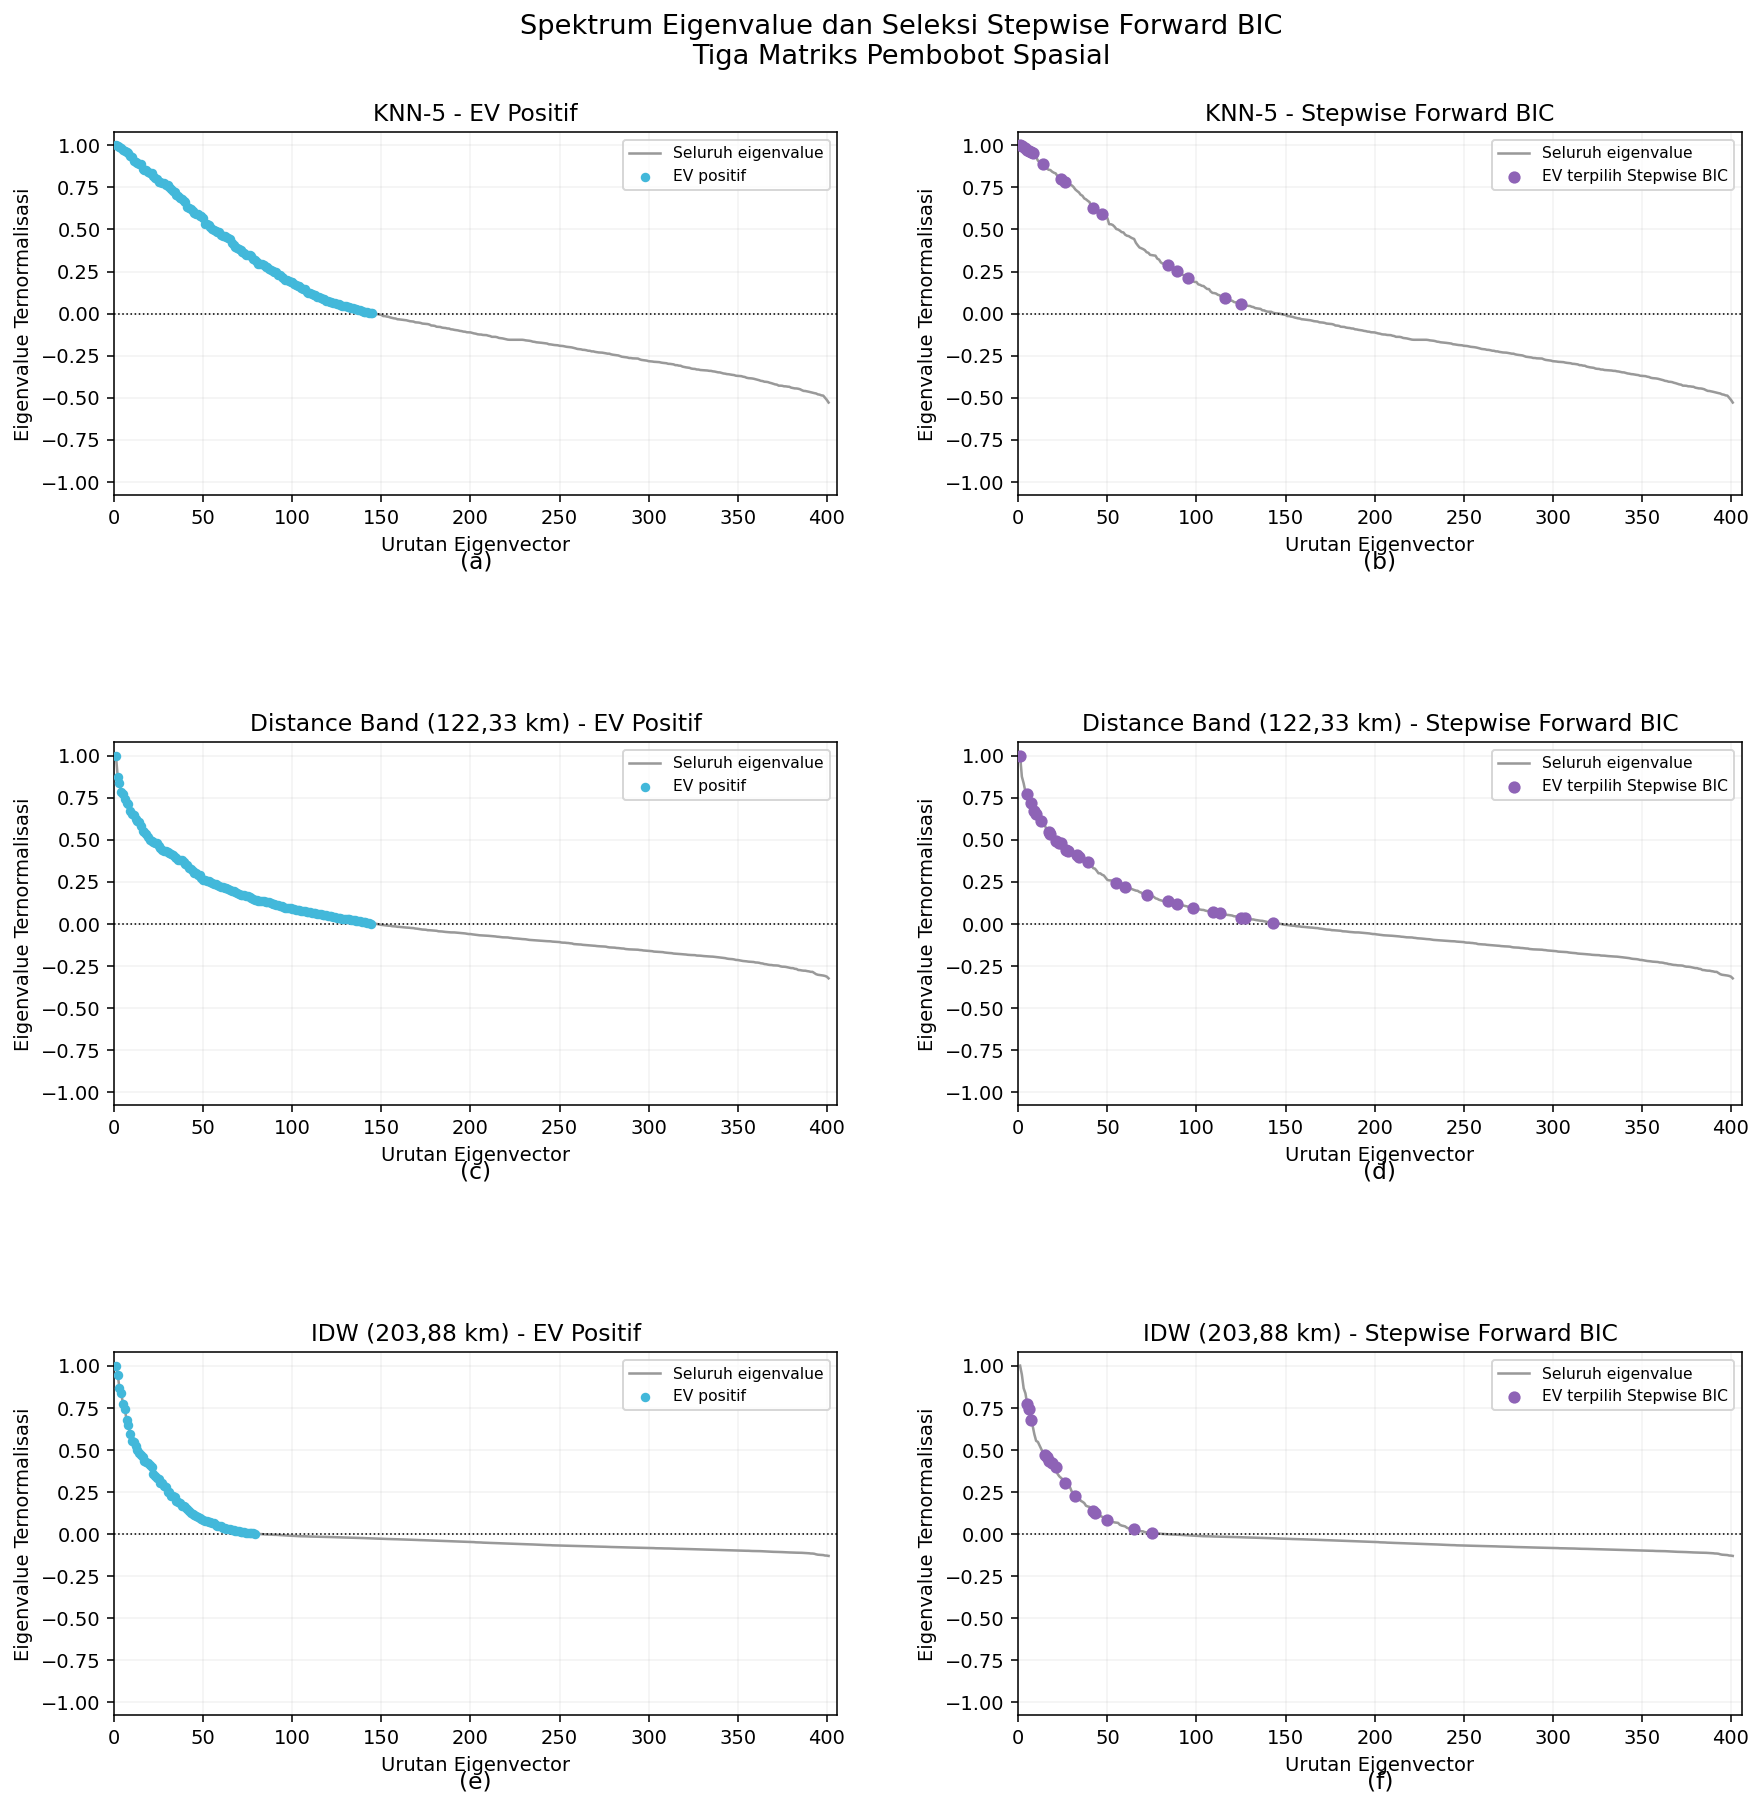


REKAP SELEKSI STEPWISE FORWARD BIC


,Matriks W,EV Positif,EV Terpilih Stepwise,EV Tidak Terpilih,BIC Awal,BIC Akhir,Penurunan BIC
0,KNN5,145,17,128,2319.14697,1989.64001,329.50696
1,DISTANCE,144,27,117,2319.14697,2021.43568,297.71129
2,IDW,79,15,64,2319.14697,2019.65498,299.49199


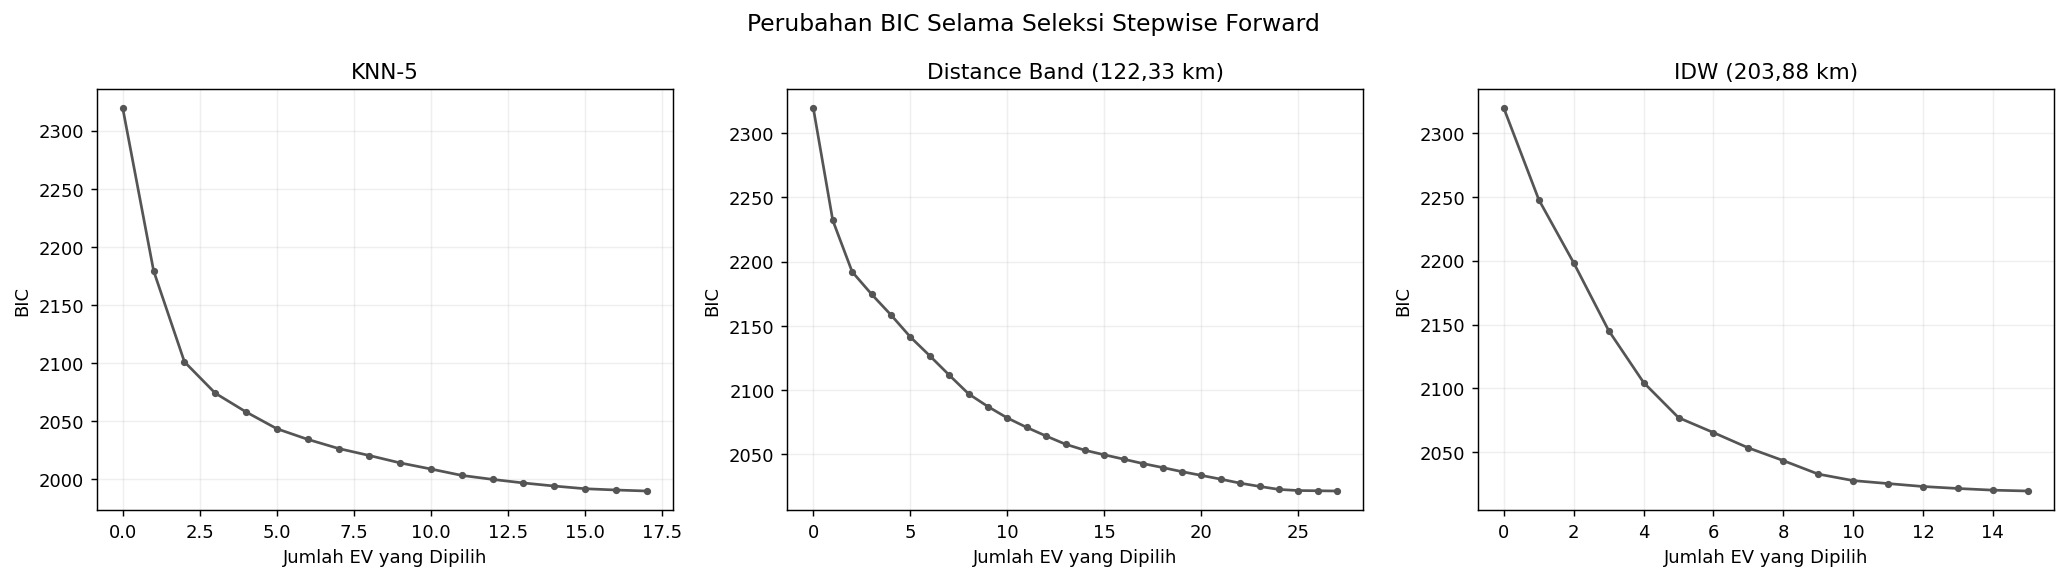


✅ SELEKSI STEPWISE FORWARD BIC SELESAI
✅ Grafik enam panel berhasil dibuat
✅ Grafik riwayat BIC berhasil dibuat
✅ EV terpilih disimpan dalam E_STEPWISE_STORE
✅ Tabel dan grafik tersimpan di /content/
✅ Siap lanjut seleksi SHAP


In [105]:

# ================================================================
# SELEKSI EIGENVECTOR STEPWISE FORWARD BIC
# + VISUALISASI EIGENVALUE 6 PANEL
#
# W        : KNN-5, DISTANCE BAND, IDW
# KANDIDAT : EV dengan eigenvalue positif
# RESPONS  : CPUE
# KRITERIA : Penambahan EV harus menurunkan BIC
#
# INPUT:
#   df_w
#   E_POSITIVE_STORE
#   EIGENVALUE_STORE
#   MWM_STORE
#
# OUTPUT:
#   E_STEPWISE_STORE
#   HASIL_STEPWISE_STORE
#   RIWAYAT_BIC_STORE
#   REKAP_STEPWISE_3W
#   Grafik PNG dan CSV
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------
# 1. PENGATURAN
# ------------------------------------------------

DAFTAR_W = ["KNN5", "DISTANCE", "IDW"]

NAMA_W = {
    "KNN5": "KNN-5",
    "DISTANCE": "Distance Band (122,33 km)",
    "IDW": "IDW (203,88 km)"
}

WARNA_SEMUA = "#999999"
WARNA_POSITIF = "#42b8da"
WARNA_STEPWISE = "#8e63b6"

TOL_EIGEN_RELATIF = 1e-10
TOL_BIC = 1e-9

os.makedirs("/content", exist_ok=True)

# ------------------------------------------------
# 2. VALIDASI DATA
# ------------------------------------------------

for nama_objek in [
    "df_w",
    "E_POSITIVE_STORE",
    "EIGENVALUE_STORE",
    "MWM_STORE"
]:
    if nama_objek not in globals():
        raise NameError(
            f"Objek {nama_objek} belum tersedia."
        )

Y = pd.to_numeric(
    df_w["cpue"],
    errors="coerce"
).to_numpy(dtype=float)

N = len(Y)

if not np.isfinite(Y).all():
    raise ValueError(
        "CPUE mengandung NaN atau infinity."
    )

if np.var(Y) <= 0:
    raise ValueError(
        "Variansi CPUE harus lebih besar dari nol."
    )

# ------------------------------------------------
# 3. FUNGSI STEPWISE FORWARD BIC
# ------------------------------------------------

def stepwise_forward_bic(X, y, nama_kolom):
    """
    Seleksi forward untuk regresi linear Gaussian.

    Model awal : intersep saja.
    Setiap langkah:
      1. Evaluasi semua EV yang belum dipilih.
      2. Hitung BIC jika EV ditambahkan.
      3. Pilih EV dengan BIC terkecil.
      4. Berhenti jika BIC tidak menurun.

    Intersep dihitung melalui pemusatan X dan y.

    Untuk efisiensi, perbaikan RSS dihitung
    melalui proyeksi ortogonal (QR).
    """

    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)

    n, p = X.shape

    if len(y) != n:
        raise ValueError("Panjang X dan y berbeda.")

    if p != len(nama_kolom):
        raise ValueError(
            "Jumlah kolom tidak sesuai nama EV."
        )

    if not np.isfinite(X).all():
        raise ValueError(
            "Matriks kandidat EV mengandung nilai invalid."
        )

    # Standarisasi kandidat
    mean_x = X.mean(axis=0)
    std_x = X.std(axis=0, ddof=0)

    std_aman = np.where(
        std_x > 1e-12,
        std_x,
        1.0
    )

    Xs = (X - mean_x) / std_aman

    # Pemusatan respons: intersep dipertahankan
    yc = y - y.mean()

    RSS_awal = float(yc @ yc)

    if RSS_awal <= 0:
        raise ValueError(
            "Variansi respons tidak boleh nol."
        )

    # BIC awal: model hanya memiliki intersep
    BIC_awal = (
        n * np.log(RSS_awal / n)
        + np.log(n)
    )

    terpilih_idx = []
    sisa_idx = list(range(p))

    RSS_saat_ini = RSS_awal
    BIC_saat_ini = BIC_awal

    riwayat = [{
        "Langkah": 0,
        "EV_Ditambahkan": "-",
        "Jumlah_EV": 0,
        "RSS": RSS_awal,
        "BIC": BIC_awal,
        "Penurunan_BIC": np.nan
    }]

    # Maksimal p langkah, namun berhenti otomatis
    # ketika tidak ada lagi penurunan BIC.
    for langkah in range(1, p + 1):

        if len(sisa_idx) == 0:
            break

        # Basis ortonormal EV yang sudah dipilih
        if len(terpilih_idx) > 0:

            Q, _ = np.linalg.qr(
                Xs[:, terpilih_idx],
                mode="reduced"
            )

            # Residual respons setelah dikontrol
            # oleh EV yang sudah terpilih.
            residual_y = yc - Q @ (Q.T @ yc)

        else:
            Q = None
            residual_y = yc.copy()

        # Semua EV yang belum dipilih
        Z = Xs[:, sisa_idx].copy()

        # Hilangkan komponen yang sudah dijelaskan
        # oleh EV terpilih
        if Q is not None:
            Z -= Q @ (Q.T @ Z)

        pembilang = residual_y @ Z

        penyebut = np.sum(
            Z * Z,
            axis=0
        )

        valid = penyebut > 1e-10

        # Perbaikan RSS untuk setiap kandidat
        perbaikan = np.zeros(len(sisa_idx))

        perbaikan[valid] = (
            pembilang[valid] ** 2
            / penyebut[valid]
        )

        RSS_kandidat = (
            RSS_saat_ini - perbaikan
        )

        # Hindari log(0) akibat presisi numerik
        RSS_kandidat = np.maximum(
            RSS_kandidat,
            np.finfo(float).tiny
        )

        # Intersep + jumlah EV setelah ditambahkan
        k_baru = len(terpilih_idx) + 2

        BIC_kandidat = (
            n * np.log(RSS_kandidat / n)
            + k_baru * np.log(n)
        )

        BIC_kandidat[~valid] = np.inf

        idx_lokal_terbaik = int(
            np.argmin(BIC_kandidat)
        )

        BIC_terbaik = float(
            BIC_kandidat[idx_lokal_terbaik]
        )

        # HENTIKAN jika BIC tidak menurun
        if not np.isfinite(BIC_terbaik):
            break

        if BIC_terbaik >= BIC_saat_ini - TOL_BIC:
            break

        # Masukkan EV terbaik
        idx_global_terbaik = sisa_idx.pop(
            idx_lokal_terbaik
        )

        BIC_lama = BIC_saat_ini

        terpilih_idx.append(idx_global_terbaik)

        BIC_saat_ini = BIC_terbaik

        # Hitung ulang RSS model terpilih
        # agar akurasi numerik tetap terjaga
        Q_baru, _ = np.linalg.qr(
            Xs[:, terpilih_idx],
            mode="reduced"
        )

        residual_baru = (
            yc - Q_baru @ (Q_baru.T @ yc)
        )

        RSS_saat_ini = float(
            residual_baru @ residual_baru
        )

        BIC_saat_ini = (
            n * np.log(
                max(RSS_saat_ini, np.finfo(float).tiny) / n
            )
            + (len(terpilih_idx) + 1) * np.log(n)
        )

        riwayat.append({
            "Langkah": langkah,
            "EV_Ditambahkan": nama_kolom[
                idx_global_terbaik
            ],
            "Jumlah_EV": len(terpilih_idx),
            "RSS": RSS_saat_ini,
            "BIC": BIC_saat_ini,
            "Penurunan_BIC": (
                BIC_lama - BIC_saat_ini
            )
        })

    return {
        "index_terpilih": terpilih_idx,
        "nama_terpilih": [
            nama_kolom[j]
            for j in terpilih_idx
        ],
        "BIC_awal": BIC_awal,
        "BIC_akhir": BIC_saat_ini,
        "RSS_akhir": RSS_saat_ini,
        "riwayat": pd.DataFrame(riwayat)
    }


# ------------------------------------------------
# 4. PENYIMPANAN HASIL
# ------------------------------------------------

E_STEPWISE_STORE = {}
HASIL_STEPWISE_STORE = {}
RIWAYAT_BIC_STORE = {}

rekap_stepwise = []

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(15, 13),
    dpi=140
)

# ------------------------------------------------
# 5. SELEKSI PADA MASING-MASING W
# ------------------------------------------------

for i, nama in enumerate(DAFTAR_W):

    print("\n" + "=" * 60)
    print("STEPWISE FORWARD BIC -", nama)
    print("=" * 60)

    E_df = E_POSITIVE_STORE[nama].copy()

    lambda_pos = np.asarray(
        EIGENVALUE_STORE[nama],
        dtype=float
    )

    if not E_df.index.equals(df_w.index):
        raise ValueError(
            f"Indeks EV {nama} tidak sesuai df_w."
        )

    if len(E_df) != N:
        raise ValueError(
            f"Jumlah observasi EV {nama} tidak sesuai."
        )

    if E_df.shape[1] != len(lambda_pos):
        raise ValueError(
            f"Jumlah EV dan eigenvalue {nama} berbeda."
        )

    # --------------------------------------------
    # A. JALANKAN SELEKSI STEPWISE
    # --------------------------------------------

    hasil = stepwise_forward_bic(
        X=E_df.to_numpy(dtype=float),
        y=Y,
        nama_kolom=E_df.columns.tolist()
    )

    nama_ev = hasil["nama_terpilih"]

    # Urutan kolom mengikuti urutan EV semula
    # supaya konsisten untuk penggabungan data.
    E_terpilih = E_df.loc[
        :,
        [c for c in E_df.columns if c in nama_ev]
    ].copy()

    E_STEPWISE_STORE[nama] = E_terpilih

    RIWAYAT_BIC_STORE[nama] = (
        hasil["riwayat"]
    )

    # --------------------------------------------
    # B. RINCIAN EV TERPILIH
    # --------------------------------------------

    mask_terpilih = (
        E_df.columns.isin(nama_ev)
    )

    urutan_masuk = {
        ev: urut
        for urut, ev in enumerate(nama_ev, start=1)
    }

    tabel = pd.DataFrame({
        "Eigenvector": E_df.columns,
        "Eigenvalue": lambda_pos,
        "Terpilih": mask_terpilih,
        "Urutan_Masuk": [
            urutan_masuk.get(c, np.nan)
            for c in E_df.columns
        ]
    })

    HASIL_STEPWISE_STORE[nama] = tabel

    # --------------------------------------------
    # C. SELURUH EIGENVALUE UNTUK GRAFIK
    # --------------------------------------------

    eigen_semua = np.linalg.eigvalsh(
        MWM_STORE[nama]
    )[::-1]

    skala = float(
        np.max(np.abs(eigen_semua))
    )

    eigen_plot = eigen_semua / skala

    urutan = np.arange(
        1, len(eigen_semua) + 1
    )

    toleransi = (
        TOL_EIGEN_RELATIF
        * max(1.0, skala)
    )

    posisi_positif = np.flatnonzero(
        eigen_semua > toleransi
    )

    if len(posisi_positif) != len(lambda_pos):
        raise ValueError(
            f"Jumlah EV positif tidak sesuai {nama}."
        )

    posisi_stepwise = posisi_positif[
        mask_terpilih
    ]

    # --------------------------------------------
    # D. PANEL KIRI: SEMUA EV DAN EV POSITIF
    # --------------------------------------------

    ax = axes[i, 0]

    ax.plot(
        urutan,
        eigen_plot,
        color=WARNA_SEMUA,
        linewidth=1.3,
        label="Seluruh eigenvalue"
    )

    ax.scatter(
        urutan[posisi_positif],
        eigen_plot[posisi_positif],
        color=WARNA_POSITIF,
        s=15,
        zorder=3,
        label="EV positif"
    )

    ax.axhline(
        0,
        color="black",
        linestyle=":",
        linewidth=0.8
    )

    ax.set_title(
        f"{NAMA_W[nama]} - EV Positif"
    )

    ax.set_xlabel("Urutan Eigenvector")
    ax.set_ylabel("Eigenvalue Ternormalisasi")
    ax.set_xlim(0, N + 5)
    ax.set_ylim(-1.08, 1.08)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.15)

    ax.text(
        0.5, -0.20,
        f"({chr(97 + 2*i)})",
        transform=ax.transAxes,
        ha="center",
        fontsize=12
    )

    # --------------------------------------------
    # E. PANEL KANAN: EV TERPILIH STEPWISE
    # --------------------------------------------

    ax = axes[i, 1]

    ax.plot(
        urutan,
        eigen_plot,
        color=WARNA_SEMUA,
        linewidth=1.3,
        label="Seluruh eigenvalue"
    )

    ax.scatter(
        urutan[posisi_stepwise],
        eigen_plot[posisi_stepwise],
        color=WARNA_STEPWISE,
        s=28,
        zorder=3,
        label="EV terpilih Stepwise BIC"
    )

    ax.axhline(
        0,
        color="black",
        linestyle=":",
        linewidth=0.8
    )

    ax.set_title(
        f"{NAMA_W[nama]} - Stepwise Forward BIC"
    )

    ax.set_xlabel("Urutan Eigenvector")
    ax.set_ylabel("Eigenvalue Ternormalisasi")
    ax.set_xlim(0, N + 5)
    ax.set_ylim(-1.08, 1.08)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.15)

    ax.text(
        0.5, -0.20,
        f"({chr(98 + 2*i)})",
        transform=ax.transAxes,
        ha="center",
        fontsize=12
    )

    # --------------------------------------------
    # F. REKAP HASIL
    # --------------------------------------------

    jumlah_kandidat = E_df.shape[1]
    jumlah_terpilih = E_terpilih.shape[1]

    rekap_stepwise.append({
        "Matriks W": nama,
        "EV Positif": jumlah_kandidat,
        "EV Terpilih Stepwise": jumlah_terpilih,
        "EV Tidak Terpilih": (
            jumlah_kandidat - jumlah_terpilih
        ),
        "BIC Awal": hasil["BIC_awal"],
        "BIC Akhir": hasil["BIC_akhir"],
        "Penurunan BIC": (
            hasil["BIC_awal"] - hasil["BIC_akhir"]
        )
    })

    print(
        "Kandidat EV positif :",
        jumlah_kandidat
    )

    print(
        "EV terpilih         :",
        jumlah_terpilih
    )

    print(
        "BIC awal            :",
        round(hasil["BIC_awal"], 4)
    )

    print(
        "BIC akhir           :",
        round(hasil["BIC_akhir"], 4)
    )

    print("\nUrutan EV yang masuk model:")
    display(
        hasil["riwayat"]
        .tail(15)
        .round(5)
    )

    # --------------------------------------------
    # G. SIMPAN CSV
    # --------------------------------------------

    tabel.to_csv(
        f"/content/SELEKSI_STEPWISE_{nama}.csv",
        index=False
    )

    hasil["riwayat"].to_csv(
        f"/content/RIWAYAT_BIC_{nama}.csv",
        index=False
    )

    tabel_ev = pd.concat(
        [
            df_w[["Longitude", "Latitude"]].copy(),
            E_terpilih
        ],
        axis=1
    )

    tabel_ev.to_csv(
        f"/content/EV_STEPWISE_{nama}.csv",
        index=False
    )

# ------------------------------------------------
# 6. TAMPILKAN GRAFIK 6 PANEL
# ------------------------------------------------

fig.suptitle(
    "Spektrum Eigenvalue dan Seleksi Stepwise Forward BIC\n"
    "Tiga Matriks Pembobot Spasial",
    fontsize=14,
    y=0.995
)

plt.subplots_adjust(
    hspace=0.68,
    wspace=0.25,
    top=0.93,
    bottom=0.06
)

plt.savefig(
    "/content/GRAFIK_EIGENVALUE_DAN_STEPWISE_3W.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 7. REKAP AKHIR
# ------------------------------------------------

REKAP_STEPWISE_3W = pd.DataFrame(
    rekap_stepwise
)

print("\n" + "=" * 65)
print("REKAP SELEKSI STEPWISE FORWARD BIC")
print("=" * 65)

display(REKAP_STEPWISE_3W.round(5))

REKAP_STEPWISE_3W.to_csv(
    "/content/REKAP_STEPWISE_3W.csv",
    index=False
)

# ------------------------------------------------
# 8. GRAFIK PERUBAHAN BIC
# ------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.5),
    dpi=130
)

for ax, nama in zip(axes, DAFTAR_W):

    riwayat = RIWAYAT_BIC_STORE[nama]

    ax.plot(
        riwayat["Jumlah_EV"],
        riwayat["BIC"],
        marker="o",
        markersize=3,
        linewidth=1.5,
        color="#555555"
    )

    ax.set_title(NAMA_W[nama])
    ax.set_xlabel("Jumlah EV yang Dipilih")
    ax.set_ylabel("BIC")
    ax.grid(alpha=0.2)

fig.suptitle(
    "Perubahan BIC Selama Seleksi Stepwise Forward",
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    "/content/GRAFIK_RIWAYAT_BIC_3W.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 9. PEMERIKSAAN TERAKHIR
# ------------------------------------------------

for nama in DAFTAR_W:

    assert len(E_STEPWISE_STORE[nama]) == N

    assert E_STEPWISE_STORE[nama].index.equals(
        df_w.index
    )

    assert (
        RIWAYAT_BIC_STORE[nama]["BIC"]
        .diff()
        .dropna()
        .lt(1e-8)
        .all()
    )

print("\n✅ SELEKSI STEPWISE FORWARD BIC SELESAI")
print("✅ Grafik enam panel berhasil dibuat")
print("✅ Grafik riwayat BIC berhasil dibuat")
print("✅ EV terpilih disimpan dalam E_STEPWISE_STORE")
print("✅ Tabel dan grafik tersimpan di /content/")
print("✅ Siap lanjut seleksi SHAP")



SELEKSI SHAP - KNN5
Kandidat EV positif : 145
EV terpilih SHAP    : 36
Ambang mean |SHAP|  : 0.01784781

10 EV dengan SHAP terbesar:


,Eigenvector,Eigenvalue,Mean_Abs_SHAP,Ambang_SHAP,Terpilih,Peringkat_SHAP
1,EV2,6.390862,0.671162,0.017848,True,1
17,EV18,5.472413,0.157180,0.017848,True,2
103,EV104,1.048586,0.057447,0.017848,True,3
64,EV65,2.844190,0.054764,0.017848,True,4
68,EV69,2.489743,0.052867,0.017848,True,5
11,EV12,5.767625,0.045983,0.017848,True,6
37,EV38,4.354896,0.045841,0.017848,True,7
22,EV23,5.163055,0.043793,0.017848,True,8
125,EV126,0.369133,0.043054,0.017848,True,9
4,EV5,6.240913,0.042341,0.017848,True,10



SELEKSI SHAP - DISTANCE
Kandidat EV positif : 144
EV terpilih SHAP    : 39
Ambang mean |SHAP|  : 0.01855655

10 EV dengan SHAP terbesar:


,Eigenvector,Eigenvalue,Mean_Abs_SHAP,Ambang_SHAP,Terpilih,Peringkat_SHAP
8,EV9,8.127340,0.267366,0.018557,True,1
9,EV10,7.976648,0.139616,0.018557,True,2
4,EV5,9.365323,0.120614,0.018557,True,3
6,EV7,8.725375,0.118054,0.018557,True,4
11,EV12,7.593008,0.099749,0.018557,True,5
3,EV4,9.549177,0.078013,0.018557,True,6
62,EV63,2.557274,0.074231,0.018557,True,7
15,EV16,6.735682,0.067716,0.018557,True,8
29,EV30,5.159295,0.067374,0.018557,True,9
32,EV33,4.974059,0.060586,0.018557,True,10



SELEKSI SHAP - IDW
Kandidat EV positif : 79
EV terpilih SHAP    : 16
Ambang mean |SHAP|  : 0.03212394

10 EV dengan SHAP terbesar:


,Eigenvector,Eigenvalue,Mean_Abs_SHAP,Ambang_SHAP,Terpilih,Peringkat_SHAP
4,EV5,0.213164,0.378433,0.032124,True,1
5,EV6,0.205151,0.297846,0.032124,True,2
6,EV7,0.186617,0.250222,0.032124,True,3
2,EV3,0.239162,0.138788,0.032124,True,4
1,EV2,0.261598,0.108903,0.032124,True,5
36,EV37,0.050589,0.071469,0.032124,True,6
71,EV72,0.002441,0.063262,0.032124,True,7
22,EV23,0.094449,0.059538,0.032124,True,8
62,EV63,0.008053,0.058819,0.032124,True,9
13,EV14,0.132820,0.056015,0.032124,True,10


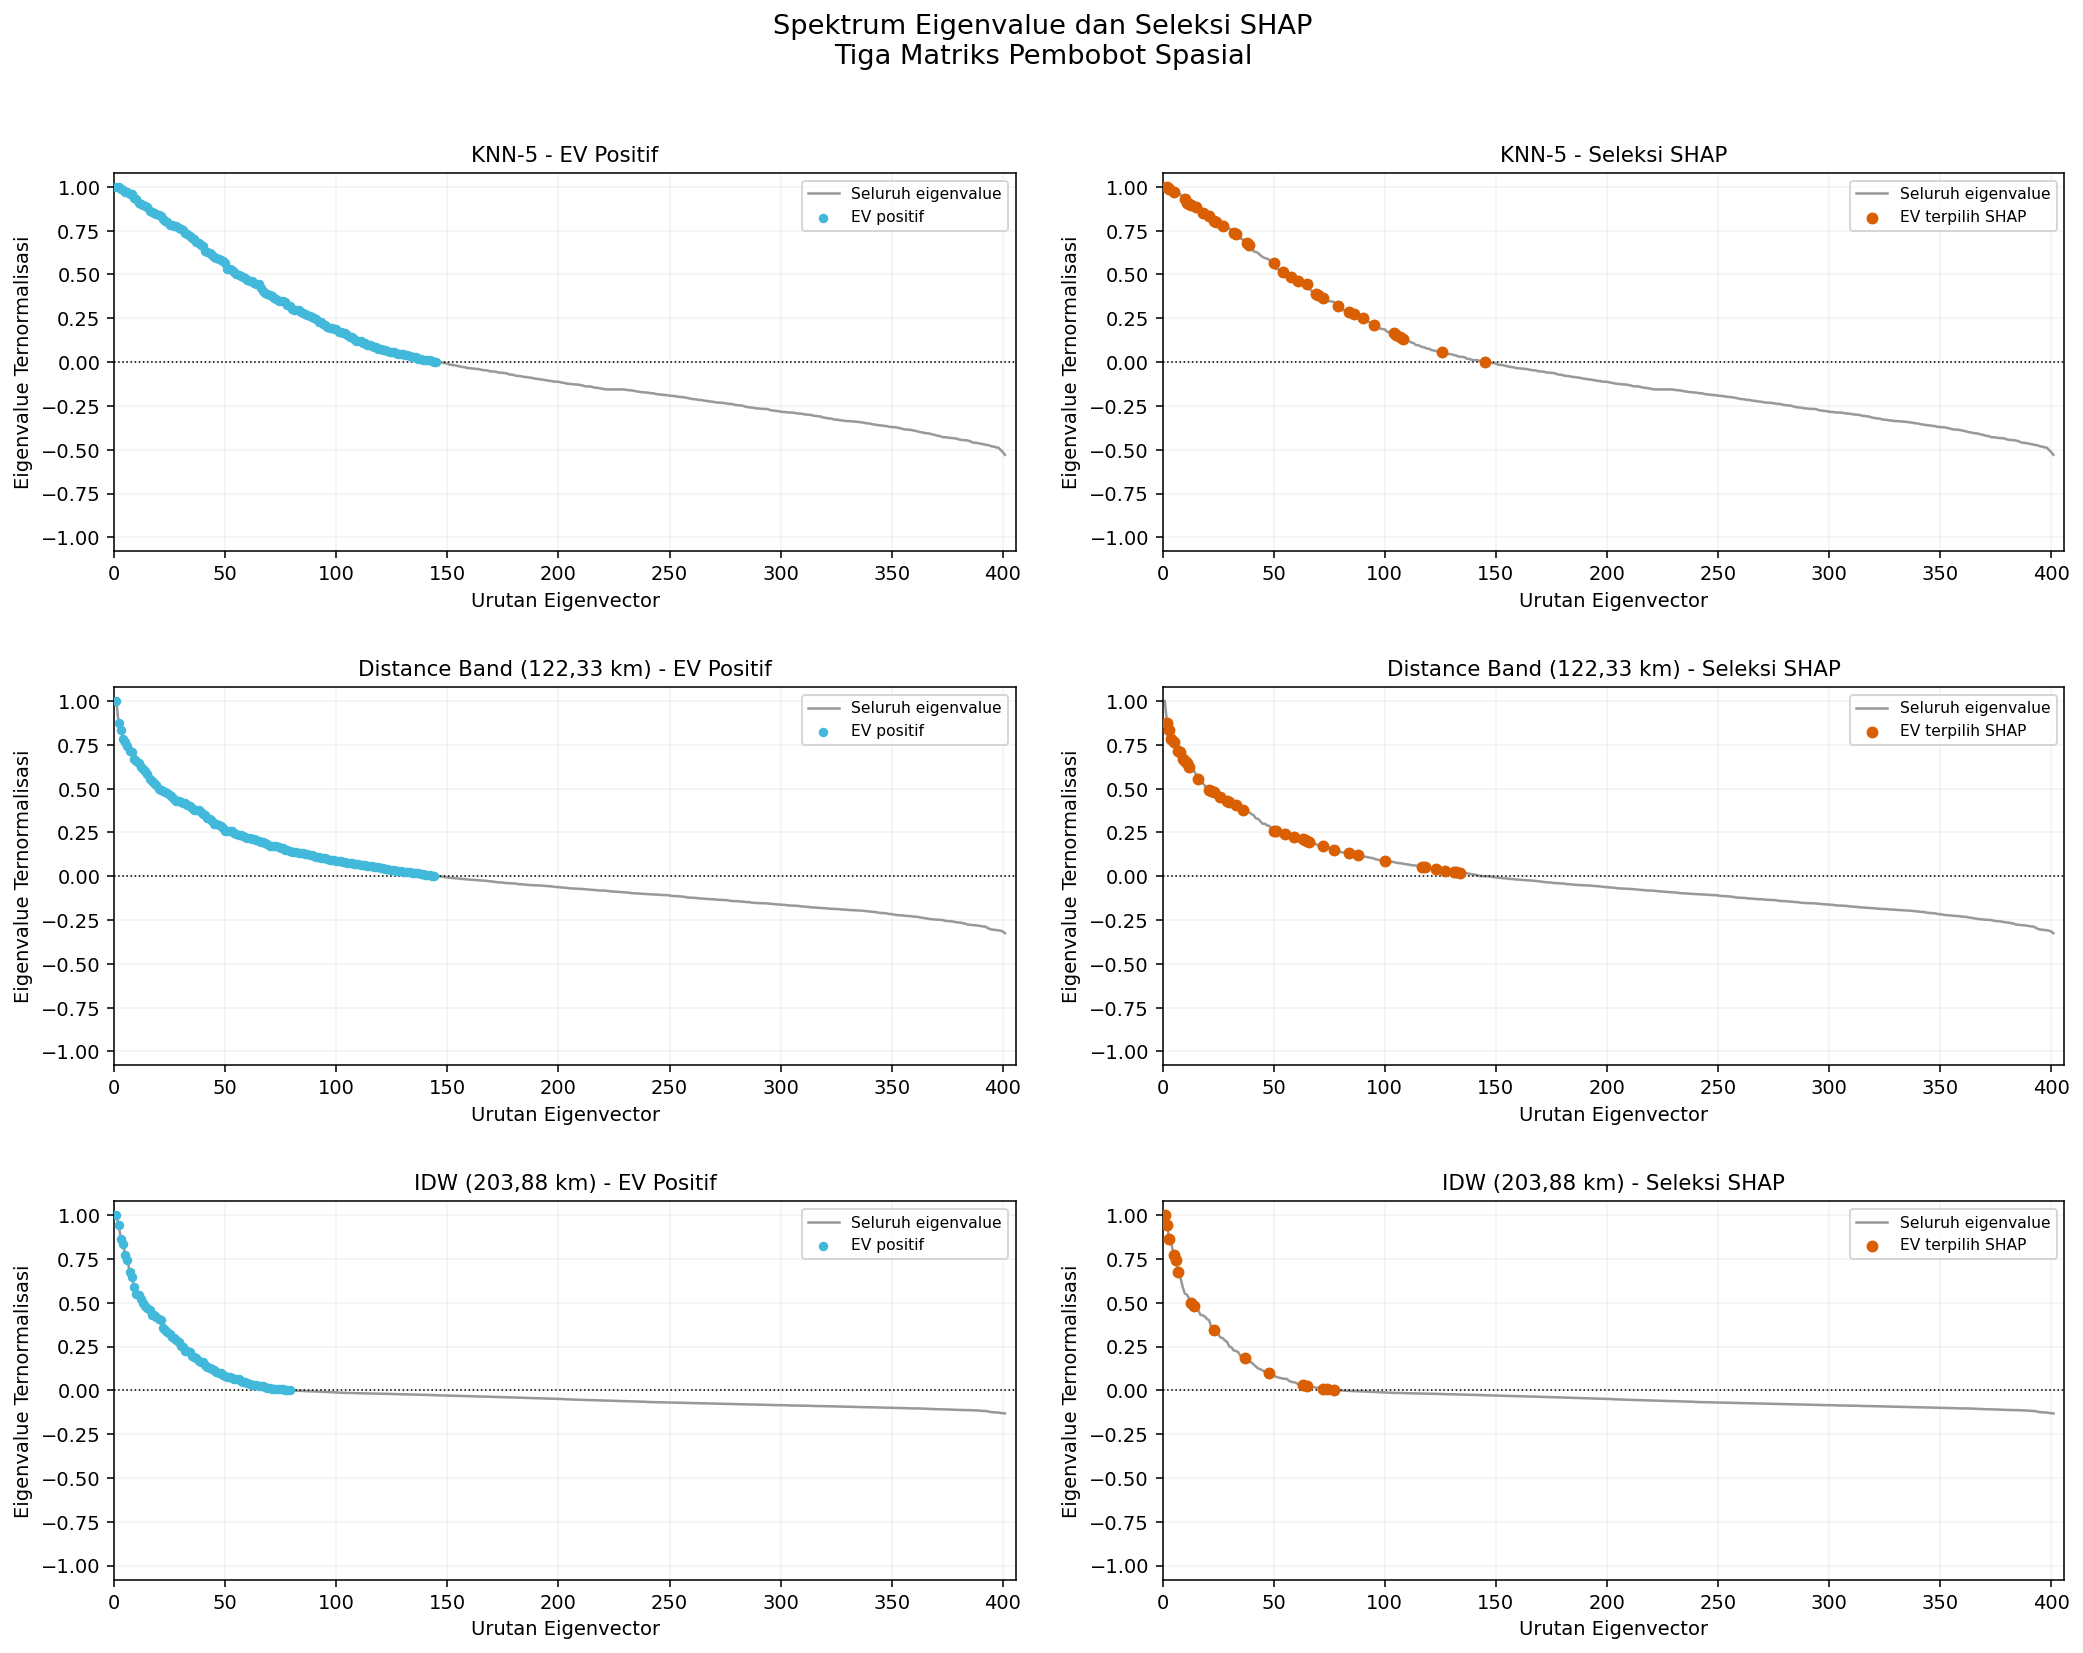


REKAP SELEKSI SHAP TIGA MATRIKS W


,Matriks W,EV Positif,EV Terpilih SHAP,EV Tidak Terpilih,Ambang Mean Abs SHAP,Persentase Terpilih (%)
0,KNN5,145,36,109,0.017848,24.827586
1,DISTANCE,144,39,105,0.018557,27.083333
2,IDW,79,16,63,0.032124,20.253165


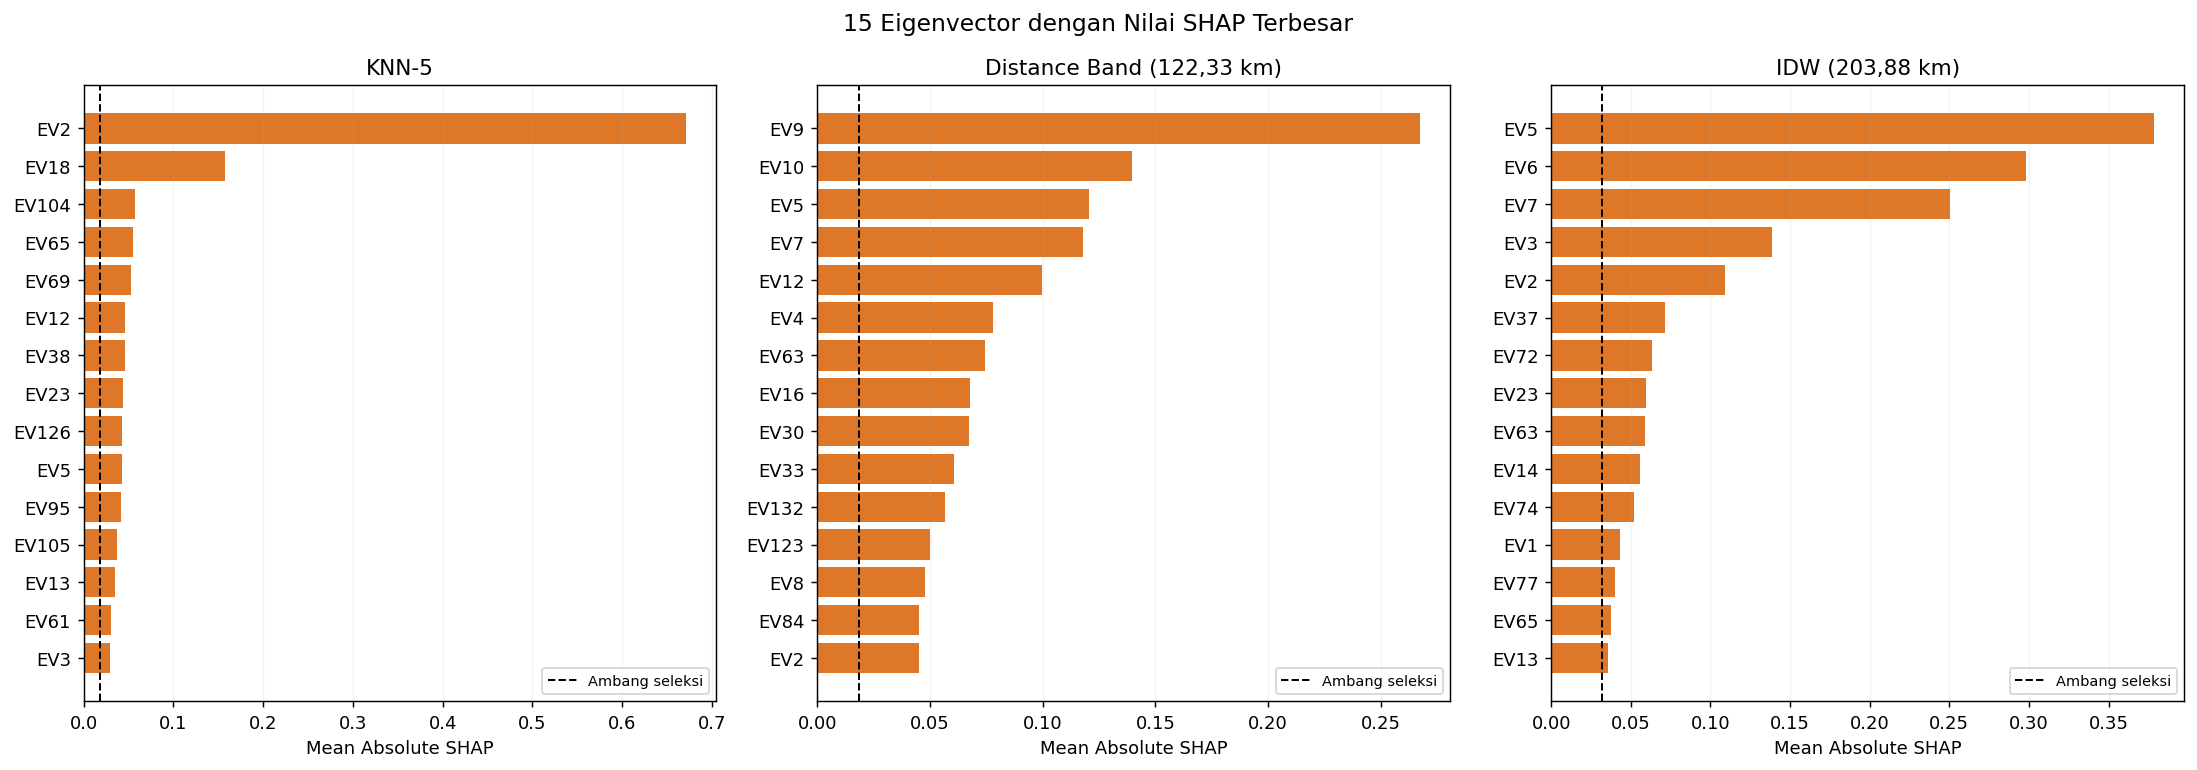


✅ SELEKSI SHAP SELESAI
✅ Tidak ada label (a), (b), dst. pada grafik
✅ EV terpilih tersimpan dalam E_SHAP_STORE
✅ Grafik dan tabel CSV berhasil disimpan


In [106]:

# ================================================================
# SELEKSI EIGENVECTOR SHAP - XGBOOST TWEEDIE
# KNN-5 | DISTANCE BAND | IDW
#
# Model bantu seleksi: XGBoost Tweedie GLOBAL
# Kandidat            : Eigenvector positif
# Kriteria            : Mean Absolute SHAP > rata-ratanya
#
# Grafik 6 panel TANPA label (a), (b), dst.
#
# INPUT:
#   df_w
#   E_POSITIVE_STORE
#   EIGENVALUE_STORE
#   MWM_STORE
#
# OUTPUT:
#   E_SHAP_STORE
#   HASIL_SHAP_STORE
#   MODEL_SHAP_STORE
#   NILAI_SHAP_STORE
#   REKAP_SHAP_3W
# ================================================================

!pip -q install xgboost

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from xgboost import XGBRegressor

os.makedirs("/content", exist_ok=True)

# ------------------------------------------------
# 1. PENGATURAN
# ------------------------------------------------

DAFTAR_W = ["KNN5", "DISTANCE", "IDW"]

NAMA_W = {
    "KNN5": "KNN-5",
    "DISTANCE": "Distance Band (122,33 km)",
    "IDW": "IDW (203,88 km)"
}

SEED = 2026
TOL_EIGEN_RELATIF = 1e-10

WARNA_SEMUA = "#999999"
WARNA_POSITIF = "#42b8da"
WARNA_SHAP = "#d95f02"

# Parameter model bantu SHAP.
# BUKAN hasil tuning Optuna GW-XGBoost.
PARAM_SHAP = {
    "n_estimators": 100,
    "max_depth": 3,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 7,
    "gamma": 0.3,
    "reg_alpha": 0.3,
    "reg_lambda": 2.0,
    "tweedie_variance_power": 1.5,
    "objective": "reg:tweedie",
    "tree_method": "hist",
    "random_state": SEED,
    "n_jobs": 1
}

# ------------------------------------------------
# 2. VALIDASI DATA
# ------------------------------------------------

for obj in [
    "df_w",
    "E_POSITIVE_STORE",
    "EIGENVALUE_STORE",
    "MWM_STORE"
]:
    if obj not in globals():
        raise NameError(
            f"Objek {obj} belum tersedia."
        )

Y = pd.to_numeric(
    df_w["cpue"],
    errors="coerce"
).to_numpy(dtype=float)

N = len(Y)

if not np.isfinite(Y).all():
    raise ValueError("CPUE mengandung nilai tidak valid.")

if np.any(Y < 0):
    raise ValueError(
        "CPUE harus nonnegatif untuk reg:tweedie."
    )

if np.var(Y) == 0:
    raise ValueError("CPUE tidak memiliki variasi.")

# ------------------------------------------------
# 3. TEMPAT MENYIMPAN HASIL
# ------------------------------------------------

E_SHAP_STORE = {}
HASIL_SHAP_STORE = {}
MODEL_SHAP_STORE = {}
NILAI_SHAP_STORE = {}

rekap_shap = []

fig, axes = plt.subplots(
    3, 2,
    figsize=(15, 12),
    dpi=140
)

# ------------------------------------------------
# 4. SELEKSI SHAP UNTUK KETIGA W
# ------------------------------------------------

for i, nama in enumerate(DAFTAR_W):

    print("\n" + "=" * 60)
    print(f"SELEKSI SHAP - {nama}")
    print("=" * 60)

    E_df = E_POSITIVE_STORE[nama].copy()

    lambda_pos = np.asarray(
        EIGENVALUE_STORE[nama],
        dtype=float
    )

    if len(E_df) != N:
        raise ValueError(
            f"Jumlah baris EV {nama} tidak sesuai."
        )

    if not E_df.index.equals(df_w.index):
        raise ValueError(
            f"Indeks EV {nama} tidak sejajar dengan df_w."
        )

    if E_df.shape[1] != len(lambda_pos):
        raise ValueError(
            f"Jumlah EV dan eigenvalue {nama} berbeda."
        )

    if not np.isfinite(E_df.to_numpy()).all():
        raise ValueError(
            f"EV {nama} mengandung nilai tidak valid."
        )

    # --------------------------------------------
    # A. MODEL BANTU XGBOOST TWEEDIE
    # --------------------------------------------

    # Model global berbasis kandidat EV positif.
    # Belum menggunakan kernel geografis lokal.
    model = XGBRegressor(**PARAM_SHAP)

    model.fit(E_df, Y)

    MODEL_SHAP_STORE[nama] = model

    # --------------------------------------------
    # B. MENGHITUNG TREE SHAP
    # --------------------------------------------

    # pred_contribs=True menghasilkan kontribusi
    # tiap fitur dalam skala output margin model.
    #
    # Untuk Tweedie dengan link log:
    # nilai SHAP berada dalam skala log-mean,
    # bukan langsung dalam satuan CPUE.

    dmatrix = xgb.DMatrix(
        E_df,
        feature_names=E_df.columns.tolist()
    )

    kontribusi = model.get_booster().predict(
        dmatrix,
        pred_contribs=True
    )

    # Kolom terakhir = bias / base value
    nilai_shap = kontribusi[:, :-1]

    if nilai_shap.shape != E_df.shape:
        raise ValueError(
            f"Dimensi SHAP tidak cocok: {nama}"
        )

    NILAI_SHAP_STORE[nama] = pd.DataFrame(
        nilai_shap,
        columns=E_df.columns,
        index=E_df.index
    )

    # --------------------------------------------
    # C. MEAN ABSOLUTE SHAP
    # --------------------------------------------

    mean_abs_shap = np.mean(
        np.abs(nilai_shap),
        axis=0
    )

    ambang_shap = float(
        np.mean(mean_abs_shap)
    )

    # Aturan pemilihan:
    # lebih besar dari rata-rata kepentingan
    mask_terpilih = (
        mean_abs_shap > ambang_shap
    )

    # Jika semua kontribusi identik/nol,
    # hasil dapat berupa 0 EV.
    # Tidak dipaksakan memilih EV tertentu.

    ev_terpilih = E_df.columns[
        mask_terpilih
    ].tolist()

    E_SHAP_STORE[nama] = E_df.loc[
        :, ev_terpilih
    ].copy()

    # --------------------------------------------
    # D. TABEL RINCIAN SELEKSI
    # --------------------------------------------

    tabel = pd.DataFrame({
        "Eigenvector": E_df.columns,
        "Eigenvalue": lambda_pos,
        "Mean_Abs_SHAP": mean_abs_shap,
        "Ambang_SHAP": ambang_shap,
        "Terpilih": mask_terpilih
    })

    tabel["Peringkat_SHAP"] = (
        tabel["Mean_Abs_SHAP"]
        .rank(
            ascending=False,
            method="min"
        )
        .astype(int)
    )

    HASIL_SHAP_STORE[nama] = tabel

    # --------------------------------------------
    # E. EIGENVALUE UNTUK GRAFIK
    # --------------------------------------------

    eigen_semua = np.linalg.eigvalsh(
        MWM_STORE[nama]
    )[::-1]

    skala = float(
        np.max(np.abs(eigen_semua))
    )

    if skala <= 0:
        raise ValueError(
            f"Semua eigenvalue {nama} nol."
        )

    toleransi = (
        TOL_EIGEN_RELATIF *
        max(1.0, skala)
    )

    posisi_positif = np.flatnonzero(
        eigen_semua > toleransi
    )

    if len(posisi_positif) != len(lambda_pos):
        raise ValueError(
            f"Jumlah EV positif {nama} tidak sesuai."
        )

    posisi_shap = posisi_positif[
        mask_terpilih
    ]

    eigen_plot = eigen_semua / skala
    urutan = np.arange(1, N + 1)

    # --------------------------------------------
    # F. PANEL KIRI - EV POSITIF
    # --------------------------------------------

    ax = axes[i, 0]

    ax.plot(
        urutan,
        eigen_plot,
        color=WARNA_SEMUA,
        linewidth=1.3,
        label="Seluruh eigenvalue"
    )

    ax.scatter(
        urutan[posisi_positif],
        eigen_plot[posisi_positif],
        color=WARNA_POSITIF,
        s=15,
        zorder=3,
        label="EV positif"
    )

    ax.axhline(
        0,
        color="black",
        linestyle=":",
        linewidth=0.8
    )

    ax.set_title(
        f"{NAMA_W[nama]} - EV Positif",
        fontsize=11
    )

    ax.set_xlabel("Urutan Eigenvector")
    ax.set_ylabel("Eigenvalue Ternormalisasi")
    ax.set_xlim(0, N + 5)
    ax.set_ylim(-1.08, 1.08)
    ax.grid(alpha=0.15)
    ax.legend(fontsize=8)

    # --------------------------------------------
    # G. PANEL KANAN - EV TERPILIH SHAP
    # TANPA LABEL (a), (b), dst.
    # --------------------------------------------

    ax = axes[i, 1]

    ax.plot(
        urutan,
        eigen_plot,
        color=WARNA_SEMUA,
        linewidth=1.3,
        label="Seluruh eigenvalue"
    )

    ax.scatter(
        urutan[posisi_shap],
        eigen_plot[posisi_shap],
        color=WARNA_SHAP,
        s=26,
        zorder=3,
        label="EV terpilih SHAP"
    )

    ax.axhline(
        0,
        color="black",
        linestyle=":",
        linewidth=0.8
    )

    ax.set_title(
        f"{NAMA_W[nama]} - Seleksi SHAP",
        fontsize=11
    )

    ax.set_xlabel("Urutan Eigenvector")
    ax.set_ylabel("Eigenvalue Ternormalisasi")
    ax.set_xlim(0, N + 5)
    ax.set_ylim(-1.08, 1.08)
    ax.grid(alpha=0.15)
    ax.legend(fontsize=8)

    # --------------------------------------------
    # H. REKAP
    # --------------------------------------------

    n_kandidat = E_df.shape[1]
    n_terpilih = E_SHAP_STORE[nama].shape[1]

    rekap_shap.append({
        "Matriks W": nama,
        "EV Positif": n_kandidat,
        "EV Terpilih SHAP": n_terpilih,
        "EV Tidak Terpilih": (
            n_kandidat - n_terpilih
        ),
        "Ambang Mean Abs SHAP": ambang_shap,
        "Persentase Terpilih (%)": (
            100 * n_terpilih / n_kandidat
        )
    })

    print("Kandidat EV positif :", n_kandidat)
    print("EV terpilih SHAP    :", n_terpilih)
    print(
        "Ambang mean |SHAP|  :",
        round(ambang_shap, 8)
    )

    print("\n10 EV dengan SHAP terbesar:")
    display(
        tabel.sort_values(
            "Mean_Abs_SHAP",
            ascending=False
        ).head(10).round(6)
    )

    # --------------------------------------------
    # I. SIMPAN CSV
    # --------------------------------------------

    tabel.to_csv(
        f"/content/SELEKSI_SHAP_{nama}.csv",
        index=False
    )

    tabel_ev = pd.concat(
        [
            df_w[
                ["Longitude", "Latitude"]
            ].copy(),
            E_SHAP_STORE[nama]
        ],
        axis=1
    )

    tabel_ev.to_csv(
        f"/content/EV_SHAP_{nama}.csv",
        index=False
    )

# ------------------------------------------------
# 5. SIMPAN DAN TAMPILKAN GRAFIK 6 PANEL
# ------------------------------------------------

fig.suptitle(
    "Spektrum Eigenvalue dan Seleksi SHAP\n"
    "Tiga Matriks Pembobot Spasial",
    fontsize=14
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96],
    h_pad=2.5,
    w_pad=2
)

plt.savefig(
    "/content/GRAFIK_EIGENVALUE_SHAP_3W.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 6. REKAP KESELURUHAN
# ------------------------------------------------

REKAP_SHAP_3W = pd.DataFrame(
    rekap_shap
)

print("\nREKAP SELEKSI SHAP TIGA MATRIKS W")

display(REKAP_SHAP_3W.round(6))

REKAP_SHAP_3W.to_csv(
    "/content/REKAP_SHAP_3W.csv",
    index=False
)

# ------------------------------------------------
# 7. GRAFIK TOP 15 SHAP TIAP W
# ------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 6),
    dpi=130
)

for ax, nama in zip(axes, DAFTAR_W):

    tabel = HASIL_SHAP_STORE[nama]

    top15 = (
        tabel.sort_values(
            "Mean_Abs_SHAP",
            ascending=False
        )
        .head(15)
        .sort_values("Mean_Abs_SHAP")
    )

    ax.barh(
        top15["Eigenvector"],
        top15["Mean_Abs_SHAP"],
        color=WARNA_SHAP,
        alpha=0.85
    )

    ambang = float(
        tabel["Ambang_SHAP"].iloc[0]
    )

    ax.axvline(
        ambang,
        color="black",
        linestyle="--",
        linewidth=1.1,
        label="Ambang seleksi"
    )

    ax.set_title(NAMA_W[nama])
    ax.set_xlabel("Mean Absolute SHAP")
    ax.grid(axis="x", alpha=0.15)
    ax.legend(fontsize=8)

fig.suptitle(
    "15 Eigenvector dengan Nilai SHAP Terbesar",
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    "/content/TOP15_SHAP_3W.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 8. VALIDASI HASIL
# ------------------------------------------------

for nama in DAFTAR_W:

    assert len(E_SHAP_STORE[nama]) == N

    assert E_SHAP_STORE[nama].index.equals(
        df_w.index
    )

    assert set(
        E_SHAP_STORE[nama].columns
    ).issubset(
        E_POSITIVE_STORE[nama].columns
    )

print("\n✅ SELEKSI SHAP SELESAI")
print("✅ Tidak ada label (a), (b), dst. pada grafik")
print("✅ EV terpilih tersimpan dalam E_SHAP_STORE")
print("✅ Grafik dan tabel CSV berhasil disimpan")


In [107]:

# ================================================================
# PENGGABUNGAN DATA SEBELUM CROSS-VALIDATION
# 12 DATASET ESF + 1 DATASET BASELINE = 13 DATASET
#
# 4 METODE:
#   MORAN, LASSO, STEPWISE, SHAP
#
# 3 MATRIKS W:
#   KNN5, DISTANCE, IDW
#
# Setiap dataset: 401 observasi
# Belum dilakukan pembagian Random/Spatial CV
# ================================================================

import os
import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------------
# 1. PENGATURAN
# ------------------------------------------------

VAR_KOORDINAT = [
    "Longitude",
    "Latitude"
]

VAR_RESPONS = "cpue"

VAR_X = [
    "so",
    "thetao",
    "zos",
    "uo",
    "vo",
    "chl",
    "o2",
    "mlotst",
    "nppv",
    "Kecepatan"
]

VAR_DASAR = (
    VAR_KOORDINAT
    + [VAR_RESPONS]
    + VAR_X
)

DAFTAR_W = [
    "KNN5",
    "DISTANCE",
    "IDW"
]

# ------------------------------------------------
# 2. CEK OBJEK HASIL SELEKSI
# ------------------------------------------------

OBJEK_WAJIB = [
    "df_w",
    "E_MORAN_STORE",
    "E_LASSO_STORE",
    "E_STEPWISE_STORE",
    "E_SHAP_STORE"
]

for nama_objek in OBJEK_WAJIB:
    if nama_objek not in globals():
        raise NameError(
            f"{nama_objek} belum tersedia. "
            "Jalankan tahap seleksi EV sebelumnya."
        )

STORE_METODE = {
    "MORAN": E_MORAN_STORE,
    "LASSO": E_LASSO_STORE,
    "STEPWISE": E_STEPWISE_STORE,
    "SHAP": E_SHAP_STORE
}

# ------------------------------------------------
# 3. SIAPKAN DATA AWAL
# ------------------------------------------------

kolom_hilang = [
    c for c in VAR_DASAR
    if c not in df_w.columns
]

if kolom_hilang:
    raise ValueError(
        f"Kolom data awal belum lengkap: {kolom_hilang}"
    )

if df_w.columns.duplicated().any():
    raise ValueError(
        "df_w memiliki nama kolom duplikat."
    )

DATA_DASAR = df_w[
    VAR_DASAR
].copy()

if DATA_DASAR.isna().any().any():
    raise ValueError(
        "Data dasar mengandung missing value. "
        "Periksa sebelum pemodelan."
    )

if not np.isfinite(
    DATA_DASAR.to_numpy(dtype=float)
).all():
    raise ValueError(
        "Data dasar mengandung nilai nonfinite."
    )

N_OBS = len(DATA_DASAR)

print("Jumlah observasi :", N_OBS)
print("Jumlah prediktor X :", len(VAR_X))
print("Jumlah kolom dasar :", len(VAR_DASAR))

# ------------------------------------------------
# 4. BUAT DATASET BASELINE
# ------------------------------------------------

DATASET_MODEL = {}

DATASET_MODEL["BASELINE"] = (
    DATA_DASAR.copy()
)

# ------------------------------------------------
# 5. BUAT 12 DATASET ESF
# ------------------------------------------------

rekap_dataset = [{
    "Kode Dataset": "BASELINE",
    "Metode Seleksi": "Tanpa ESF",
    "Matriks W": "-",
    "Jumlah Observasi": N_OBS,
    "Jumlah X": len(VAR_X),
    "Jumlah EV": 0,
    "Jumlah Prediktor Model": len(VAR_X),
    "Total Kolom Dataset": len(VAR_DASAR)
}]

for metode, store in STORE_METODE.items():

    for nama_w in DAFTAR_W:

        kode = f"{metode}_{nama_w}"

        if nama_w not in store:
            raise KeyError(
                f"EV {nama_w} tidak ditemukan "
                f"pada {metode}."
            )

        EV = store[nama_w].copy()

        # ----------------------------------------
        # VALIDASI EV
        # ----------------------------------------

        if len(EV) != N_OBS:
            raise ValueError(
                f"{kode}: jumlah baris EV "
                "tidak sesuai."
            )

        if not EV.index.equals(
            DATA_DASAR.index
        ):
            raise ValueError(
                f"{kode}: indeks EV tidak "
                "sejajar dengan data dasar."
            )

        if EV.columns.duplicated().any():
            raise ValueError(
                f"{kode}: nama kolom EV duplikat."
            )

        if set(EV.columns).intersection(
            DATA_DASAR.columns
        ):
            raise ValueError(
                f"{kode}: ada nama kolom EV "
                "yang sama dengan data dasar."
            )

        if EV.shape[1] > 0:

            if not np.isfinite(
                EV.to_numpy(dtype=float)
            ).all():
                raise ValueError(
                    f"{kode}: EV mengandung "
                    "NaN atau infinity."
                )

        # ----------------------------------------
        # GABUNGKAN DATA AWAL + EV TERPILIH
        # ----------------------------------------

        DATA_GABUNG = pd.concat(
            [
                DATA_DASAR.copy(),
                EV
            ],
            axis=1
        )

        DATASET_MODEL[kode] = DATA_GABUNG

        jumlah_ev = EV.shape[1]

        rekap_dataset.append({
            "Kode Dataset": kode,
            "Metode Seleksi": metode,
            "Matriks W": nama_w,
            "Jumlah Observasi": N_OBS,
            "Jumlah X": len(VAR_X),
            "Jumlah EV": jumlah_ev,
            "Jumlah Prediktor Model": (
                len(VAR_X) + jumlah_ev
            ),
            "Total Kolom Dataset": (
                DATA_GABUNG.shape[1]
            )
        })

# ------------------------------------------------
# 6. TABEL REKAP 13 DATASET
# ------------------------------------------------

REKAP_13_DATASET = pd.DataFrame(
    rekap_dataset
)

print("\n" + "=" * 75)
print("REKAP 13 DATASET SEBELUM SPLIT")
print("=" * 75)

display(REKAP_13_DATASET)

# ------------------------------------------------
# 7. VALIDASI KESELURUHAN DATASET
# ------------------------------------------------

assert len(DATASET_MODEL) == 13, (
    "Jumlah dataset harus 13."
)

for kode, df_model in DATASET_MODEL.items():

    assert len(df_model) == N_OBS, (
        f"Jumlah baris salah: {kode}"
    )

    assert df_model.index.equals(
        DATA_DASAR.index
    ), f"Indeks berbeda: {kode}"

    # Koordinat, respons, dan 10 X
    # harus sama pada seluruh dataset.
    pd.testing.assert_frame_equal(
        df_model[VAR_DASAR],
        DATA_DASAR
    )

    assert not df_model.columns.duplicated().any()

    assert not df_model.isna().any().any()

print("\n✅ Semua dataset memiliki", N_OBS, "baris")
print("✅ Data dasar identik pada 13 dataset")
print("✅ Hanya kolom EV yang berbeda")
print("✅ Total dataset:", len(DATASET_MODEL))

# ------------------------------------------------
# 8. SIMPAN SEMUA DATASET KE CSV
# ------------------------------------------------

FOLDER_OUTPUT = "/content/DATASET_13_MODEL"

os.makedirs(
    FOLDER_OUTPUT,
    exist_ok=True
)

for kode, df_model in DATASET_MODEL.items():

    lokasi_file = (
        f"{FOLDER_OUTPUT}/{kode}.csv"
    )

    df_model.to_csv(
        lokasi_file,
        index=False
    )

REKAP_13_DATASET.to_csv(
    f"{FOLDER_OUTPUT}/REKAP_13_DATASET.csv",
    index=False
)

# ------------------------------------------------
# 9. SIMPAN SEMUA KE SATU FILE ZIP
# ------------------------------------------------

import shutil

shutil.make_archive(
    "/content/DATASET_13_MODEL",
    "zip",
    FOLDER_OUTPUT
)

# ------------------------------------------------
# 10. CONTOH PENGAMBILAN DATA MODEL
# ------------------------------------------------

print("\nContoh dataset baseline:")
display(
    DATASET_MODEL["BASELINE"].head(3)
)

print("\nContoh dataset SHAP-IDW:")
display(
    DATASET_MODEL["SHAP_IDW"].head(3)
)

print("\nDAFTAR KODE DATASET:")
print(list(DATASET_MODEL.keys()))

print("\n✅ PENGGABUNGAN 13 DATASET SELESAI")
print("✅ Semua dataset tersimpan sebagai CSV")
print("✅ File ZIP: /content/DATASET_13_MODEL.zip")
print("✅ Belum dilakukan split cross-validation")


Jumlah observasi : 401
Jumlah prediktor X : 10
Jumlah kolom dasar : 13

REKAP 13 DATASET SEBELUM SPLIT


,Kode Dataset,Metode Seleksi,Matriks W,Jumlah Observasi,Jumlah X,Jumlah EV,Jumlah Prediktor Model,Total Kolom Dataset
0,BASELINE,Tanpa ESF,-,401,10,0,10,13
1,MORAN_KNN5,MORAN,KNN5,401,10,89,99,102
2,MORAN_DISTANCE,MORAN,DISTANCE,401,10,53,63,66
3,MORAN_IDW,MORAN,IDW,401,10,30,40,43
4,LASSO_KNN5,LASSO,KNN5,401,10,40,50,53
5,LASSO_DISTANCE,LASSO,DISTANCE,401,10,56,66,69
6,LASSO_IDW,LASSO,IDW,401,10,40,50,53
7,STEPWISE_KNN5,STEPWISE,KNN5,401,10,17,27,30
8,STEPWISE_DISTANCE,STEPWISE,DISTANCE,401,10,27,37,40
9,STEPWISE_IDW,STEPWISE,IDW,401,10,15,25,28



✅ Semua dataset memiliki 401 baris
✅ Data dasar identik pada 13 dataset
✅ Hanya kolom EV yang berbeda
✅ Total dataset: 13

Contoh dataset baseline:


,Longitude,Latitude,cpue,so,thetao,zos,uo,vo,chl,o2,mlotst,nppv,Kecepatan
0,92.25,2.75,32.812079,32.456251,29.179822,0.409609,0.007200,-0.005725,0.116589,200.629854,18.672807,4.189994,0.009199
1,92.25,3.25,39.330566,32.112098,29.233677,0.416061,0.048852,-0.034232,0.109667,200.716746,16.415003,3.758218,0.059652
2,92.25,3.75,18.095839,31.879946,29.342594,0.418971,0.068079,-0.070260,0.106332,200.683519,16.389571,3.515052,0.097833



Contoh dataset SHAP-IDW:


,Longitude,Latitude,cpue,so,thetao,zos,uo,vo,chl,o2,...,EV13,EV14,EV23,EV37,EV48,EV63,EV65,EV72,EV74,EV77
0,92.25,2.75,32.812079,32.456251,29.179822,0.409609,0.007200,-0.005725,0.116589,200.629854,...,0.013978,-0.016871,-0.000246,0.001288,-0.002891,-0.012019,-0.080671,0.001342,0.009939,-0.001155
1,92.25,3.25,39.330566,32.112098,29.233677,0.416061,0.048852,-0.034232,0.109667,200.716746,...,0.015781,-0.019264,-0.002124,0.006548,-0.001298,0.016265,0.085617,0.010559,-0.003212,0.008675
2,92.25,3.75,18.095839,31.879946,29.342594,0.418971,0.068079,-0.070260,0.106332,200.683519,...,0.015121,-0.018493,-0.003054,0.007953,-0.002248,0.021069,0.137384,0.022905,-0.014761,0.021961



DAFTAR KODE DATASET:
['BASELINE', 'MORAN_KNN5', 'MORAN_DISTANCE', 'MORAN_IDW', 'LASSO_KNN5', 'LASSO_DISTANCE', 'LASSO_IDW', 'STEPWISE_KNN5', 'STEPWISE_DISTANCE', 'STEPWISE_IDW', 'SHAP_KNN5', 'SHAP_DISTANCE', 'SHAP_IDW']

✅ PENGGABUNGAN 13 DATASET SELESAI
✅ Semua dataset tersimpan sebagai CSV
✅ File ZIP: /content/DATASET_13_MODEL.zip
✅ Belum dilakukan split cross-validation


In [108]:

# ================================================================
# ARSIP SEMUA HASIL PENELITIAN ESF-GW-XGBOOST TWEEDIE
# MULAI DARI PETA, EDA, W, MORAN, EIGENVALUE,
# 4 METODE SELEKSI, SAMPAI 13 DATASET MODEL
#
# OUTPUT:
# /content/HASIL_LENGKAP_ESF_TUNA.zip
# ================================================================

import os
import re
import io
import zipfile
import pandas as pd

from pathlib import Path
from google.colab import files
from IPython.display import display

# ------------------------------------------------
# 1. LOKASI DAN NAMA ZIP
# ------------------------------------------------

ROOT = Path("/content")

NAMA_ZIP = "HASIL_LENGKAP_ESF_TUNA.zip"
PATH_ZIP = ROOT / NAMA_ZIP

# Jenis file yang dikumpulkan
EKSTENSI = {
    ".png", ".jpg", ".jpeg", ".svg", ".webp",
    ".pdf", ".html",
    ".csv", ".xlsx", ".xls"
}

# Folder bawaan/teknis yang tidak perlu diarsipkan
FOLDER_ABAIKAN = {
    "sample_data",
    ".config",
    ".cache",
    "__pycache__",
    ".ipynb_checkpoints"
}

# ------------------------------------------------
# 2. FUNGSI PENGELOMPOKAN FILE
# ------------------------------------------------

def tentukan_kategori(path):

    nama = path.name.lower()
    lokasi = str(path).lower()

    # Dataset model didahulukan agar file seperti
    # MORAN_KNN5.csv tetap masuk folder dataset.
    if "dataset_13_model" in lokasi:
        return "09_DATASET_13_MODEL"

    # Seleksi metode
    if any(k in nama for k in [
        "stepwise", "riwayat_bic", "grafik_bic"
    ]):
        return "07_SELEKSI_STEPWISE"

    if "lasso" in nama:
        return "06_SELEKSI_LASSO"

    if "shap" in nama:
        return "08_SELEKSI_SHAP"

    if "moran" in nama and any(
        k in nama for k in [
            "seleksi", "ev_moran",
            "eigenvalue_dan_moran",
            "rekap_moran_3w"
        ]
    ):
        return "05_SELEKSI_MORAN"

    # Peta
    if any(k in nama for k in [
        "peta", "map", "grid", "wpp",
        "lokasi", "sebaran_spasial",
        "persebaran"
    ]):
        return "01_PETA"

    # EDA
    if any(k in nama for k in [
        "histogram", "boxplot", "eda",
        "korelasi", "correlation",
        "heatmap", "spearman",
        "pearson", "vif",
        "distribusi", "outlier",
        "scatter", "tweedie_check"
    ]):
        return "02_EDA"

    # Eigenvalue dan eigenvector
    if any(k in nama for k in [
        "eigen", "spektrum", "spectrum",
        "positive_ev", "ev_positive"
    ]):
        return "04_EIGENVALUE"

    # Matriks W dan Moran's I
    if any(k in nama for k in [
        "matriks_w", "bobot_spasial",
        "knn", "distance", "idw",
        "uji_moran", "moran_i",
        "rekap_w", "hasil_moran"
    ]):
        return "03_MATRIKS_W_DAN_MORAN"

    # File lain yang belum sesuai pola nama
    return "10_HASIL_LAINNYA"


# ------------------------------------------------
# 3. CARI SEMUA FILE HASIL DI /content
# ------------------------------------------------

daftar_file = []

for folder, subfolders, filenames in os.walk(ROOT):

    # Jangan masuk ke folder bawaan
    subfolders[:] = [
        d for d in subfolders
        if d not in FOLDER_ABAIKAN
        and not d.startswith(".")
        and d != "drive"  # Google Drive tidak di-scan
    ]

    for filename in filenames:

        path = Path(folder) / filename

        # Lewati ZIP agar tidak membuat duplikasi
        if path.suffix.lower() == ".zip":
            continue

        if path.suffix.lower() not in EKSTENSI:
            continue

        if not path.is_file():
            continue

        kategori = tentukan_kategori(path)

        daftar_file.append({
            "path": path,
            "kategori": kategori,
            "ukuran_kb": round(
                path.stat().st_size / 1024, 2
            )
        })

# Urutkan berdasarkan folder dan nama file
daftar_file.sort(
    key=lambda x: (
        x["kategori"],
        x["path"].name.lower()
    )
)

# ------------------------------------------------
# 4. BUAT FILE ZIP DENGAN FOLDER RAPI
# ------------------------------------------------

rekap_arsip = []

if len(daftar_file) == 0:

    print("⚠️ Belum ditemukan file PNG/CSV/PDF.")
    print("Pastikan hasil penelitian sudah disimpan.")

else:

    with zipfile.ZipFile(
        PATH_ZIP,
        mode="w",
        compression=zipfile.ZIP_DEFLATED,
        compresslevel=6
    ) as zipf:

        for item in daftar_file:

            path = item["path"]
            kategori = item["kategori"]

            # Pertahankan nama relatif agar
            # dua file bernama sama tidak tertimpa.
            relatif = path.relative_to(ROOT)

            # Hindari pengulangan folder dataset
            if relatif.parts[0] == "DATASET_13_MODEL":
                relatif = Path(*relatif.parts[1:])

            if str(relatif) == ".":
                relatif = Path(path.name)

            nama_dalam_zip = (
                f"{kategori}/{relatif.as_posix()}"
            )

            zipf.write(
                path,
                arcname=nama_dalam_zip
            )

            rekap_arsip.append({
                "Kategori": kategori,
                "Nama File": path.name,
                "Lokasi Asal": str(path),
                "Lokasi dalam ZIP": nama_dalam_zip,
                "Ukuran (KB)": item["ukuran_kb"]
            })

        # ----------------------------------------
        # 5. MASUKKAN DAFTAR FILE KE DALAM ZIP
        # ----------------------------------------

        TABEL_DAFTAR_FILE = pd.DataFrame(
            rekap_arsip
        )

        csv_bytes = TABEL_DAFTAR_FILE.to_csv(
            index=False
        ).encode("utf-8-sig")

        zipf.writestr(
            "DAFTAR_FILE.csv",
            csv_bytes
        )

        # Ringkasan informasi
        ringkasan = f"""
ARSIP HASIL PENELITIAN
ESF-GW-XGBOOST TWEEDIE

Jumlah file terkumpul: {len(rekap_arsip)}

Isi arsip:
01_PETA
02_EDA
03_MATRIKS_W_DAN_MORAN
04_EIGENVALUE
05_SELEKSI_MORAN
06_SELEKSI_LASSO
07_SELEKSI_STEPWISE
08_SELEKSI_SHAP
09_DATASET_13_MODEL
10_HASIL_LAINNYA

DAFTAR_FILE.csv memuat daftar file dan
lokasi asalnya di Google Colab.

CATATAN:
Hanya file yang sudah tersimpan di
/content yang dapat dikumpulkan.
Grafik yang baru ditampilkan tetapi belum
disimpan tidak otomatis masuk ZIP.
"""

        zipf.writestr(
            "BACA_SAYA.txt",
            ringkasan.strip()
        )

    # ------------------------------------------------
    # 6. TAMPILKAN REKAP FILE
    # ------------------------------------------------

    print("=" * 65)
    print("REKAP ARSIP HASIL PENELITIAN")
    print("=" * 65)

    REKAP_KATEGORI = (
        TABEL_DAFTAR_FILE
        .groupby("Kategori")
        .agg(
            Jumlah_File=("Nama File", "count"),
            Total_Ukuran_KB=("Ukuran (KB)", "sum")
        )
        .reset_index()
    )

    display(REKAP_KATEGORI.round(2))

    print("\nJumlah file:", len(rekap_arsip))

    print(
        "Ukuran ZIP:",
        round(
            PATH_ZIP.stat().st_size / (1024**2),
            2
        ),
        "MB"
    )

    print("\nContoh isi ZIP:")
    display(
        TABEL_DAFTAR_FILE[
            ["Kategori", "Nama File"]
        ].head(25)
    )

    # ------------------------------------------------
    # 7. DOWNLOAD OTOMATIS
    # ------------------------------------------------

    print("\n✅ Semua file berhasil disatukan")
    print("✅ ZIP:", PATH_ZIP)
    print("✅ Download dimulai...")

    files.download(str(PATH_ZIP))


REKAP ARSIP HASIL PENELITIAN


,Kategori,Jumlah_File,Total_Ukuran_KB
0,01_PETA,5,3828.18
1,02_EDA,5,1996.75
2,03_MATRIKS_W_DAN_MORAN,21,10958.13
3,04_EIGENVALUE,9,2076.81
4,05_SELEKSI_MORAN,16,4871.69
5,06_SELEKSI_LASSO,15,2844.59
6,07_SELEKSI_STEPWISE,18,1917.26
7,08_SELEKSI_SHAP,14,3028.48
8,09_DATASET_13_MODEL,14,4550.15
9,10_HASIL_LAINNYA,14,1703.13



Jumlah file: 131
Ukuran ZIP: 20.42 MB

Contoh isi ZIP:


,Kategori,Nama File
0,01_PETA,GRID_LENGKAP_WPP_572_573.csv
1,01_PETA,HEATMAP_KORELASI_XY.png
2,01_PETA,PETA_10_VARIABEL_OSEANOGRAFI.png
3,01_PETA,PETA_CPUE_GRID_INDONESIA.png
4,01_PETA,PETA_GRID_LENGKAP_WPP_572_573.png
5,02_EDA,BOXPLOT_CPUE_DAN_X.png
6,02_EDA,HISTOGRAM_CPUE_DAN_X.png
7,02_EDA,KORELASI_PEARSON_SPEARMAN.png
8,02_EDA,KORELASI_X_TERHADAP_CPUE.png
9,02_EDA,TABEL_KORELASI_XY.csv



✅ Semua file berhasil disatukan
✅ ZIP: /content/HASIL_LENGKAP_ESF_TUNA.zip
✅ Download dimulai...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Jumlah dataset : 13
Jumlah lokasi  : 401
Status         : Semua baris sejajar


,ID_Observasi,Longitude,Latitude,cpue,Fold_Random_10,Cluster_Spasial,Fold_Spatial_4
0,1,92.25,2.75,32.812079,6,1,3
1,2,92.25,3.25,39.330566,1,1,3
2,3,92.25,3.75,18.095839,9,1,3
3,4,92.75,1.25,2.806741,10,1,3
4,5,92.75,2.75,13.232582,5,1,3
5,6,92.75,3.25,52.779530,1,1,3
6,7,92.75,3.75,28.084742,2,1,3
7,8,93.25,0.75,37.616170,1,1,3
8,9,93.25,1.25,28.898506,5,1,3
9,10,93.25,3.75,88.362529,7,1,3



REKAP PEMBAGIAN CROSS-VALIDATION


,Jenis CV,Fold,Jumlah Train,Jumlah Validasi,CPUE Mean Train,CPUE Mean Validasi
0,RANDOM_10FOLD,1,360,41,9.2886,13.8504
1,RANDOM_10FOLD,2,361,40,9.8886,8.5498
2,RANDOM_10FOLD,3,361,40,9.9305,8.1711
3,RANDOM_10FOLD,4,361,40,10.0269,7.3016
4,RANDOM_10FOLD,5,361,40,10.2764,5.0501
5,RANDOM_10FOLD,6,361,40,10.0089,7.4640
6,RANDOM_10FOLD,7,361,40,9.8047,9.3066
7,RANDOM_10FOLD,8,361,40,8.9536,16.9881
8,RANDOM_10FOLD,9,361,40,9.5164,11.9088
9,RANDOM_10FOLD,10,361,40,9.8545,8.8575


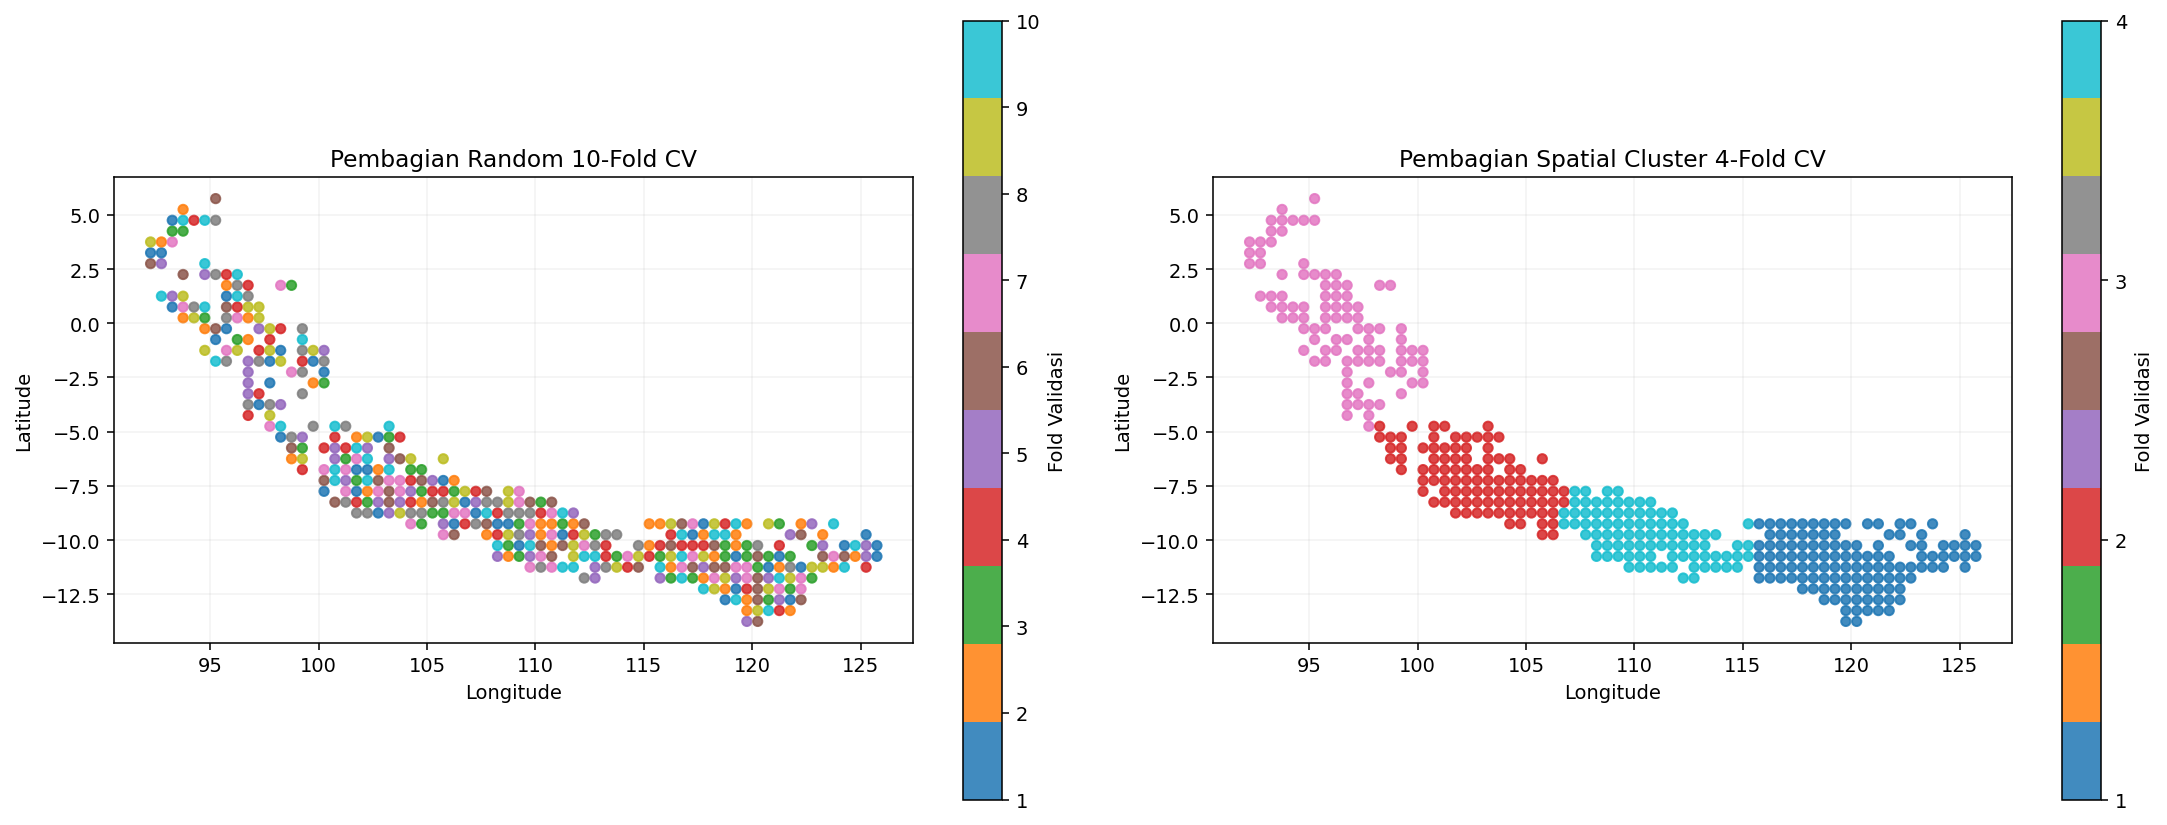


CONTOH: FOLD PERTAMA RANDOM 10-FOLD
Model         : MORAN_KNN5
Jumlah train  : 360
Jumlah valid  : 41

✅ RANDOM 10-FOLD BERHASIL
✅ SPATIAL CLUSTER 4-FOLD BERHASIL
✅ Indeks sama untuk seluruh 13 dataset
✅ CV_SPLITS siap dipakai saat pemodelan
✅ Grafik dan tabel disimpan dalam ZIP


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [110]:

# ================================================================
# PEMBAGIAN CROSS-VALIDATION OTOMATIS
# UNTUK SELURUH 13 DATASET MODEL
#
# 1. RANDOM 10-FOLD CV
# 2. SPATIAL CLUSTER 4-FOLD CV
#
# Semua dataset memakai indeks fold yang SAMA.
# Tidak perlu membuat split satu per satu.
#
# INPUT : DATASET_MODEL (13 DataFrame)
# OUTPUT:
#   CV_SPLITS
#   TABEL_FOLD
#   REKAP_FOLD
#   PLOT PEMBAGIAN FOLD
#   ZIP HASIL PEMBAGIAN
# ================================================================

import os
import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import KFold, GroupKFold
from sklearn.cluster import KMeans
from IPython.display import display
from google.colab import files

# ------------------------------------------------
# 1. PENGATURAN
# ------------------------------------------------

SEED = 2026
N_RANDOM = 10
N_SPATIAL = 4

FOLDER_CV = Path("/content/HASIL_PEMBAGIAN_CV")
FOLDER_CV.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 2. CEK 13 DATASET
# ------------------------------------------------

if "DATASET_MODEL" not in globals():
    raise NameError(
        "DATASET_MODEL belum tersedia. "
        "Jalankan cell penggabungan 13 dataset dahulu."
    )

if len(DATASET_MODEL) != 13:
    raise ValueError(
        "Jumlah dataset harus 13."
    )

BASE = DATASET_MODEL["BASELINE"]

N = len(BASE)

KOORD = BASE[
    ["Longitude", "Latitude"]
].to_numpy(dtype=float)

Y = BASE["cpue"].to_numpy(dtype=float)

if not np.isfinite(KOORD).all():
    raise ValueError(
        "Koordinat tidak valid."
    )

if not np.isfinite(Y).all():
    raise ValueError(
        "CPUE tidak valid."
    )

# Pastikan semua dataset identik dari segi
# jumlah baris, indeks, koordinat, dan CPUE.
for kode, data in DATASET_MODEL.items():

    if len(data) != N:
        raise ValueError(
            f"Jumlah baris berbeda: {kode}"
        )

    if not data.index.equals(BASE.index):
        raise ValueError(
            f"Indeks berbeda: {kode}"
        )

    pd.testing.assert_frame_equal(
        data[["Longitude", "Latitude", "cpue"]],
        BASE[["Longitude", "Latitude", "cpue"]]
    )

print("Jumlah dataset :", len(DATASET_MODEL))
print("Jumlah lokasi  :", N)
print("Status         : Semua baris sejajar")

# ------------------------------------------------
# 3. RANDOM 10-FOLD
# ------------------------------------------------

random_cv = KFold(
    n_splits=N_RANDOM,
    shuffle=True,
    random_state=SEED
)

SPLIT_RANDOM = list(
    random_cv.split(np.arange(N))
)

# Nomor fold validasi untuk tiap observasi
LABEL_RANDOM = np.zeros(
    N,
    dtype=int
)

for nomor_fold, (_, idx_valid) in enumerate(
    SPLIT_RANDOM,
    start=1
):
    LABEL_RANDOM[idx_valid] = nomor_fold

# ------------------------------------------------
# 4. SPATIAL CLUSTER 4-FOLD
# ------------------------------------------------

# Koordinat longitude-latitude diubah menjadi
# koordinat planar aproksimasi dalam kilometer.
#
# Konversi ini digunakan HANYA untuk membentuk
# kelompok lokasi spasial (bukan W dan bukan
# bandwidth GW-XGBoost).
#
# x = 111.32 * lon * cos(lat_referensi)
# y = 111.32 * lat

lon = KOORD[:, 0]
lat = KOORD[:, 1]

lat_ref = np.deg2rad(
    float(np.mean(lat))
)

XY_KM = np.column_stack([
    lon * 111.32 * np.cos(lat_ref),
    lat * 111.32
])

# Bentuk empat kelompok geografis
kmeans_spasial = KMeans(
    n_clusters=N_SPATIAL,
    n_init=30,
    random_state=SEED
)

KELOMPOK_SPASIAL = (
    kmeans_spasial.fit_predict(XY_KM)
)

# GroupKFold memastikan satu kelompok spasial
# masuk seluruhnya ke train ATAU validasi.
# Satu kelompok tidak dipecah ke dua bagian.

spatial_cv = GroupKFold(
    n_splits=N_SPATIAL
)

SPLIT_SPATIAL = list(
    spatial_cv.split(
        np.arange(N),
        Y,
        groups=KELOMPOK_SPASIAL
    )
)

LABEL_SPATIAL = np.zeros(
    N,
    dtype=int
)

for nomor_fold, (_, idx_valid) in enumerate(
    SPLIT_SPATIAL,
    start=1
):
    LABEL_SPATIAL[idx_valid] = nomor_fold

# ------------------------------------------------
# 5. SIMPAN SEMUA SPLIT DALAM SATU OBJEK
# ------------------------------------------------

CV_SPLITS = {
    "RANDOM_10FOLD": SPLIT_RANDOM,
    "SPATIAL_4FOLD": SPLIT_SPATIAL
}

# ------------------------------------------------
# 6. TABEL IDENTITAS FOLD PER OBSERVASI
# ------------------------------------------------

TABEL_FOLD = pd.DataFrame({
    "ID_Observasi": np.arange(1, N + 1),
    "Longitude": lon,
    "Latitude": lat,
    "cpue": Y,
    "Fold_Random_10": LABEL_RANDOM,
    "Cluster_Spasial": KELOMPOK_SPASIAL + 1,
    "Fold_Spatial_4": LABEL_SPATIAL
})

display(TABEL_FOLD.head(10))

TABEL_FOLD.to_csv(
    FOLDER_CV / "IDENTITAS_FOLD_401_DATA.csv",
    index=False
)

# ------------------------------------------------
# 7. TABEL UKURAN TRAIN DAN VALIDASI
# ------------------------------------------------

rekap = []
rincian_fold = []

for nama_cv, split_list in CV_SPLITS.items():

    for fold_ke, (idx_train, idx_valid) in enumerate(
        split_list,
        start=1
    ):

        # Pastikan train dan validasi tidak overlap
        assert len(
            np.intersect1d(idx_train, idx_valid)
        ) == 0

        # Pastikan keseluruhan 401 lokasi tercakup
        assert len(
            np.union1d(idx_train, idx_valid)
        ) == N

        if nama_cv == "SPATIAL_4FOLD":

            grup_train = set(
                KELOMPOK_SPASIAL[idx_train]
            )

            grup_valid = set(
                KELOMPOK_SPASIAL[idx_valid]
            )

            assert grup_train.isdisjoint(
                grup_valid
            )

        rekap.append({
            "Jenis CV": nama_cv,
            "Fold": fold_ke,
            "Jumlah Train": len(idx_train),
            "Jumlah Validasi": len(idx_valid),
            "CPUE Mean Train": float(
                np.mean(Y[idx_train])
            ),
            "CPUE Mean Validasi": float(
                np.mean(Y[idx_valid])
            )
        })

        # Simpan indeks untuk reproduksibilitas
        for j in idx_train:
            rincian_fold.append({
                "Jenis CV": nama_cv,
                "Fold": fold_ke,
                "ID_Observasi": int(j + 1),
                "Peran": "TRAIN"
            })

        for j in idx_valid:
            rincian_fold.append({
                "Jenis CV": nama_cv,
                "Fold": fold_ke,
                "ID_Observasi": int(j + 1),
                "Peran": "VALIDASI"
            })

REKAP_FOLD = pd.DataFrame(rekap)

RINCIAN_INDEKS_FOLD = pd.DataFrame(
    rincian_fold
)

print("\nREKAP PEMBAGIAN CROSS-VALIDATION")
display(REKAP_FOLD.round(4))

REKAP_FOLD.to_csv(
    FOLDER_CV / "REKAP_UKURAN_FOLD.csv",
    index=False
)

RINCIAN_INDEKS_FOLD.to_csv(
    FOLDER_CV / "INDEKS_TRAIN_VALIDASI.csv",
    index=False
)

# ------------------------------------------------
# 8. VISUALISASI PEMBAGIAN 10 DAN 4 FOLD
# ------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6),
    dpi=140
)

# Random CV
sc1 = axes[0].scatter(
    lon,
    lat,
    c=LABEL_RANDOM,
    cmap="tab10",
    s=23,
    alpha=0.85
)

axes[0].set_title(
    "Pembagian Random 10-Fold CV"
)

axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].set_aspect("equal", adjustable="box")
axes[0].grid(alpha=0.15)

cbar1 = plt.colorbar(
    sc1,
    ax=axes[0],
    ticks=range(1, 11)
)

cbar1.set_label("Fold Validasi")

# Spatial CV
sc2 = axes[1].scatter(
    lon,
    lat,
    c=LABEL_SPATIAL,
    cmap="tab10",
    s=23,
    alpha=0.85
)

axes[1].set_title(
    "Pembagian Spatial Cluster 4-Fold CV"
)

axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].set_aspect("equal", adjustable="box")
axes[1].grid(alpha=0.15)

cbar2 = plt.colorbar(
    sc2,
    ax=axes[1],
    ticks=range(1, 5)
)

cbar2.set_label("Fold Validasi")

plt.tight_layout()

plt.savefig(
    FOLDER_CV / "PETA_RANDOM_DAN_SPATIAL_CV.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 9. CONTOH PEMAKAIAN PADA SEMUA DATASET
# ------------------------------------------------

# Tidak perlu menyimpan 13 x 14 file terpisah.
# Gunakan indeks split dari CV_SPLITS.

print("\nCONTOH: FOLD PERTAMA RANDOM 10-FOLD")

idx_train, idx_valid = (
    CV_SPLITS["RANDOM_10FOLD"][0]
)

contoh = DATASET_MODEL["MORAN_KNN5"]

data_train = contoh.iloc[idx_train].copy()
data_valid = contoh.iloc[idx_valid].copy()

print("Model         : MORAN_KNN5")
print("Jumlah train  :", len(data_train))
print("Jumlah valid  :", len(data_valid))

# Hanya contoh. Semua dataset menggunakan
# indeks yang identik.
assert len(data_train) + len(data_valid) == N

# ------------------------------------------------
# 10. SIMPAN METADATA
# ------------------------------------------------

metadata = {
    "jumlah_observasi": N,
    "jumlah_dataset": len(DATASET_MODEL),
    "seed": SEED,
    "random_cv": {
        "metode": "KFold",
        "n_splits": N_RANDOM,
        "shuffle": True
    },
    "spatial_cv": {
        "metode": "KMeans + GroupKFold",
        "n_clusters": N_SPATIAL,
        "n_splits": N_SPATIAL,
        "koordinat": "Aproksimasi kilometer"
    },
    "dataset": list(DATASET_MODEL.keys())
}

with open(
    FOLDER_CV / "METADATA_CV.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        metadata,
        f,
        indent=2
    )

# ------------------------------------------------
# 11. ZIP DAN DOWNLOAD
# ------------------------------------------------

PATH_ZIP_CV = shutil.make_archive(
    "/content/HASIL_PEMBAGIAN_CV",
    "zip",
    FOLDER_CV
)

print("\n✅ RANDOM 10-FOLD BERHASIL")
print("✅ SPATIAL CLUSTER 4-FOLD BERHASIL")
print("✅ Indeks sama untuk seluruh 13 dataset")
print("✅ CV_SPLITS siap dipakai saat pemodelan")
print("✅ Grafik dan tabel disimpan dalam ZIP")

files.download(PATH_ZIP_CV)
